# Audit critique et sélection des variables — DPE Corse

**Projet Machine Learning sous Python — M2 SISE**

## Objectif

Cette étude vise à analyser et améliorer la sélection des variables
utilisées pour prédire :

1. L'étiquette énergétique DPE (classification A à G).
2. La consommation énergétique en kWhEP/m²/an (régression).

Nous étudions les logements existants et neufs de Corse,
à partir des deux API de l'ADEME.

Notre démarche consiste à :

- Examiner les variables candidates.
- Comprendre et vérifier les exclusions déjà réalisées.
- Étudier les valeurs manquantes et les distributions.
- Évaluer la pertinence statistique et métier des variables.
- Identifier de nouvelles variables explicatives.
- Comparer les performances des modèles avant et après sélection.

Les choix seront justifiés par des analyses statistiques,
des expérimentations et les contraintes d'utilisation de l'application.

In [2]:
# ============================================================
# 1. INVENTAIRE ET ANALYSE DES VARIABLES ACTUELLES
# ============================================================

import sys
import json
from pathlib import Path

import pandas as pd

# ------------------------------------------------------------
# 1.1. Accès aux fichiers du projet
# ------------------------------------------------------------

# Identifier la racine du dépôt
RACINE = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

# Permettre l'importation des modules du projet
sys.path.insert(0, str(RACINE))

# Importer les configurations et les transformations existantes
from src.utilis import config
from src.data import transformateurs as tf

# ------------------------------------------------------------
# 1.2. Récupération des variables candidates
# ------------------------------------------------------------

# Variables numériques disponibles pour la sélection
variables_num = config.VARIABLES_CANDIDATES_NUMERIQUES

# Variables catégorielles disponibles pour la sélection
variables_cat = config.VARIABLES_CANDIDATES_CATEGORIELLES

# Variables créées par transformation des variables initiales
variables_creees = tf.VARIABLES_CREEES_CATEGORIELLES

# Ensemble des variables étudiées
toutes_variables = (
    variables_num
    + variables_cat
    + variables_creees
)

# ------------------------------------------------------------
# 1.3. Charger les décisions de sélection déjà réalisées
# ------------------------------------------------------------

chemin_selection = (
    config.DOSSIER_MODELES / "variables_retenues.json"
)

with open(chemin_selection, "r", encoding="utf-8") as fichier:
    selection = json.load(fichier)

# Variables retenues par Saliou
variables_retenues = (
    selection["variables_numeriques"]
    + selection["variables_categorielles"]
)

# Variables supprimées et raisons associées
variables_supprimees = selection["variables_retirees"]

# ------------------------------------------------------------
# 1.4. Construire le tableau d'audit
# ------------------------------------------------------------

inventaire = pd.DataFrame({
    "Variable": toutes_variables,

    "Type": (
        ["Numérique"] * len(variables_num)
        + ["Catégorielle"] * len(variables_cat)
        + ["Créée"] * len(variables_creees)
    )
})

# Indiquer si la variable a été retenue
inventaire["Décision actuelle"] = inventaire["Variable"].apply(
    lambda variable:
    "Retenue" if variable in variables_retenues
    else "Supprimée"
)

# Récupérer la justification de suppression
inventaire["Justification actuelle"] = (
    inventaire["Variable"]
    .map(variables_supprimees)
    .fillna("—")
)

# ------------------------------------------------------------
# 1.5. Affichage des résultats
# ------------------------------------------------------------

print("===== RÉSUMÉ DE LA SÉLECTION ACTUELLE =====")

print("Variables numériques :", len(variables_num))
print("Variables catégorielles :", len(variables_cat))
print("Variables créées :", len(variables_creees))

print("\nTotal des variables étudiées :", len(toutes_variables))
print("Variables retenues :", len(variables_retenues))
print("Variables supprimées :", len(variables_supprimees))

print("\n===== TABLEAU D'AUDIT =====")

display(inventaire)

===== RÉSUMÉ DE LA SÉLECTION ACTUELLE =====
Variables numériques : 10
Variables catégorielles : 29
Variables créées : 3

Total des variables étudiées : 42
Variables retenues : 23
Variables supprimées : 19

===== TABLEAU D'AUDIT =====


,Variable,Type,Décision actuelle,Justification actuelle
0,surface_habitable_logement,Numérique,Retenue,—
1,hauteur_sous_plafond,Numérique,Retenue,—
2,annee_construction,Numérique,Retenue,—
3,nombre_niveau_logement,Numérique,Supprimée,faible importance (hors des 95% cumulés ; 0.9%)
4,numero_etage_appartement,Numérique,Supprimée,faible importance (hors des 95% cumulés ; 0.7%)
5,nombre_niveau_immeuble,Numérique,Supprimée,manquants 86%
6,nombre_appartement,Numérique,Retenue,—
7,surface_habitable_immeuble,Numérique,Supprimée,manquants 81%
8,volume_stockage_generateur_n1_ecs_n1,Numérique,Retenue,—
9,surface_chauffee_installation_chauffage_n1,Numérique,Retenue,—


## 2. Analyse des valeurs manquantes

### Objectif

Évaluer la qualité des variables candidates afin de déterminer
si leur sélection actuelle est pertinente.

L'analyse distingue :

- Le taux global de valeurs manquantes.
- Le taux de valeurs manquantes dans les logements existants.
- Le taux de valeurs manquantes dans les logements neufs.
- Les différences de disponibilité entre les deux sources.

Nous travaillons sur le jeu d'entraînement afin de ne pas
utiliser les données de test pour prendre les décisions
de sélection des variables.

Une variable présentant beaucoup de valeurs manquantes
n'est pas automatiquement inutile : sa pertinence dépend
également de son intérêt métier et de son pouvoir prédictif.

In [3]:
# ============================================================
# 2. ANALYSE DES VALEURS MANQUANTES
# ============================================================

# ------------------------------------------------------------
# 2.1. Chargement du jeu d'entraînement
# ------------------------------------------------------------

chemin_train = config.DATA_TRAITE / "train.csv"

train = pd.read_csv(
    chemin_train,
    low_memory=False
)

print("Dimensions du jeu d'entraînement :", train.shape)

print("\nRépartition des logements :")
print(train["source_jeu"].value_counts())

# ------------------------------------------------------------
# 2.2. Identifier les variables présentes
# ------------------------------------------------------------

variables_etudiees = inventaire["Variable"].tolist()

variables_presentes = [
    variable
    for variable in variables_etudiees
    if variable in train.columns
]

variables_absentes = [
    variable
    for variable in variables_etudiees
    if variable not in train.columns
]

print("\nVariables présentes :", len(variables_presentes))
print("Variables absentes :", variables_absentes)

# ------------------------------------------------------------
# 2.3. Calcul des taux de valeurs manquantes
# ------------------------------------------------------------

# Taux global de valeurs manquantes
manquants_global = (
    train[variables_presentes]
    .isna()
    .mean()
    * 100
)

# Calcul séparé pour les logements existants et neufs
manquants_source = (
    train.groupby("source_jeu")[variables_presentes]
    .apply(lambda df: df.isna().mean() * 100)
)

# ------------------------------------------------------------
# 2.4. Construire le tableau comparatif
# ------------------------------------------------------------

audit_manquants = inventaire[
    inventaire["Variable"].isin(variables_presentes)
].copy()

audit_manquants["Manquants global (%)"] = (
    audit_manquants["Variable"].map(manquants_global)
)

audit_manquants["Manquants existants (%)"] = (
    audit_manquants["Variable"].map(
        manquants_source.loc["existant"]
    )
)

audit_manquants["Manquants neufs (%)"] = (
    audit_manquants["Variable"].map(
        manquants_source.loc["neuf"]
    )
)

# Différence entre les deux sources
audit_manquants["Écart entre sources (points)"] = (
    audit_manquants["Manquants existants (%)"]
    - audit_manquants["Manquants neufs (%)"]
).abs()

# ------------------------------------------------------------
# 2.5. Affichage des résultats
# ------------------------------------------------------------

# Classer par différence de disponibilité
audit_manquants = audit_manquants.sort_values(
    "Écart entre sources (points)",
    ascending=False
)

colonnes_affichage = [
    "Variable",
    "Décision actuelle",
    "Manquants global (%)",
    "Manquants existants (%)",
    "Manquants neufs (%)",
    "Écart entre sources (points)"
]

print("===== COMPARAISON DES VALEURS MANQUANTES =====")

display(
    audit_manquants[colonnes_affichage].round(1)
)

Dimensions du jeu d'entraînement : (39387, 61)

Répartition des logements :
source_jeu
existant    36375
neuf         3012
Name: count, dtype: int64

Variables présentes : 42
Variables absentes : []
===== COMPARAISON DES VALEURS MANQUANTES =====


,Variable,Décision actuelle,Manquants global (%),Manquants existants (%),Manquants neufs (%),Écart entre sources (points)
9,surface_chauffee_installation_chauffage_n1,Retenue,11.1,3.8,99.8,96.0
22,classe_inertie_batiment,Retenue,9.1,1.8,97.5,95.7
25,type_emetteur_installation_chauffage_n1,Retenue,11.0,3.8,98.3,94.5
26,type_generateur_n1_installation_n1,Retenue,11.0,3.8,98.3,94.5
29,type_generateur_n1_ecs_n1,Retenue,11.2,4.0,98.3,94.2
38,type_installation_solaire_n1,Supprimée,11.2,4.0,98.3,94.2
8,volume_stockage_generateur_n1_ecs_n1,Retenue,11.2,4.0,98.3,94.2
39,famille_ventilation,Retenue,12.6,5.6,97.8,92.2
19,type_ventilation,Supprimée,12.6,5.6,97.8,92.2
33,inertie_lourde,Retenue,20.5,16.3,72.1,55.8


In [4]:
# ============================================================
# 2.6. VARIABLES RETENUES MAIS POTENTIELLEMENT PROBLÉMATIQUES
# ============================================================

# Variables actuellement retenues
retenues = audit_manquants[
    audit_manquants["Décision actuelle"] == "Retenue"
].copy()

# Identifier les variables avec au moins 50 % de valeurs
# manquantes dans l'une des deux sources
a_examiner = retenues[
    (retenues["Manquants existants (%)"] >= 50)
    |
    (retenues["Manquants neufs (%)"] >= 50)
]

print("Nombre de variables retenues à examiner :", len(a_examiner))

display(
    a_examiner[colonnes_affichage]
    .sort_values(
        "Écart entre sources (points)",
        ascending=False
    )
    .round(1)
)

Nombre de variables retenues à examiner : 11


,Variable,Décision actuelle,Manquants global (%),Manquants existants (%),Manquants neufs (%),Écart entre sources (points)
9,surface_chauffee_installation_chauffage_n1,Retenue,11.1,3.8,99.8,96.0
22,classe_inertie_batiment,Retenue,9.1,1.8,97.5,95.7
25,type_emetteur_installation_chauffage_n1,Retenue,11.0,3.8,98.3,94.5
26,type_generateur_n1_installation_n1,Retenue,11.0,3.8,98.3,94.5
29,type_generateur_n1_ecs_n1,Retenue,11.2,4.0,98.3,94.2
8,volume_stockage_generateur_n1_ecs_n1,Retenue,11.2,4.0,98.3,94.2
39,famille_ventilation,Retenue,12.6,5.6,97.8,92.2
33,inertie_lourde,Retenue,20.5,16.3,72.1,55.8
35,protection_solaire_exterieure,Retenue,18.4,14.2,69.7,55.5
32,isolation_toiture,Retenue,18.4,14.2,69.7,55.5


## 3. Comparaison des étiquettes DPE entre logements neufs et existants

### Objectif

Étudier la distribution des classes énergétiques A à G
pour les deux sources de données.

Cette analyse permet :

- D'identifier les déséquilibres entre les classes.
- De comparer les profils énergétiques des logements.
- De comprendre les différences de performance des modèles.
- De déterminer si une sélection commune des variables est pertinente.

Un diagramme en barres est utilisé car l'étiquette DPE
est une variable qualitative ordinale.

Les résultats sont calculés sur le jeu d'entraînement.

===== EFFECTIFS PAR CLASSE =====


etiquette_dpe,A,B,C,D,E,F,G
source_jeu,,,,,,,
existant,4555,6516,14513,6364,2722,1168,537
neuf,2558,306,147,0,0,0,1


===== RÉPARTITION DES CLASSES (%) =====


etiquette_dpe,A,B,C,D,E,F,G
source_jeu,,,,,,,
existant,12.52,17.91,39.90,17.5,7.48,3.21,1.48
neuf,84.93,10.16,4.88,0.0,0.00,0.00,0.03


existant : classe majoritaire C (39.9 %)
neuf : classe majoritaire A (84.9 %)


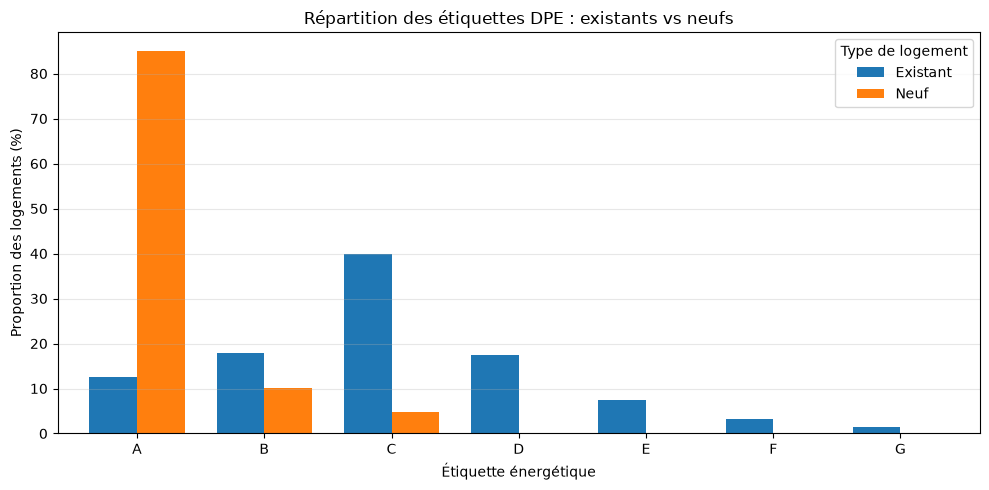

In [5]:
# ============================================================
# 3. COMPARAISON DES ÉTIQUETTES DPE PAR SOURCE
# ============================================================

import matplotlib.pyplot as plt

# Ordre officiel des classes énergétiques
ordre_classes = list("ABCDEFG")

# ------------------------------------------------------------
# 3.1. Calculer les effectifs
# ------------------------------------------------------------

effectifs = pd.crosstab(
    train["source_jeu"],
    train["etiquette_dpe"]
)

# Respecter l'ordre des classes
effectifs = effectifs.reindex(
    index=["existant", "neuf"],
    columns=ordre_classes,
    fill_value=0
)

print("===== EFFECTIFS PAR CLASSE =====")
display(effectifs)

# ------------------------------------------------------------
# 3.2. Calculer les proportions
# ------------------------------------------------------------

# Chaque source totalise 100 %
proportions = (
    effectifs.div(effectifs.sum(axis=1), axis=0)
    * 100
)

print("===== RÉPARTITION DES CLASSES (%) =====")
display(proportions.round(2))

# ------------------------------------------------------------
# 3.3. Identifier la classe majoritaire
# ------------------------------------------------------------

for source in proportions.index:

    classe = proportions.loc[source].idxmax()
    proportion = proportions.loc[source].max()

    print(
        f"{source} : classe majoritaire {classe} "
        f"({proportion:.1f} %)"
    )

# ------------------------------------------------------------
# 3.4. Représentation graphique
# ------------------------------------------------------------

ax = proportions.T.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title(
    "Répartition des étiquettes DPE : existants vs neufs"
)

ax.set_xlabel("Étiquette énergétique")
ax.set_ylabel("Proportion des logements (%)")

ax.legend(
    title="Type de logement",
    labels=["Existant", "Neuf"]
)

ax.set_xticklabels(
    ordre_classes,
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

### 3.5. Vérification du périmètre géographique

L'étude porte exclusivement sur les DPE de Corse
(code région 94).

Nous vérifions que les logements du jeu d'entraînement
appartiennent uniquement aux départements 2A et 2B.

In [6]:
# ============================================================
# 3.5. VÉRIFICATION DU PÉRIMÈTRE CORSE
# ============================================================

# Répartition des DPE par département et par source
tableau_departements = pd.crosstab(
    train["code_departement_ban"],
    train["source_jeu"],
    margins=True
)

print("===== RÉPARTITION GÉOGRAPHIQUE =====")
display(tableau_departements)

# Vérifier les codes départementaux présents
codes_presents = set(
    train["code_departement_ban"]
    .dropna()
    .astype(str)
    .unique()
)

print("Codes départementaux trouvés :", codes_presents)

# Vérification du périmètre
codes_corse = {"2A", "2B"}

assert codes_presents == codes_corse, (
    "Attention : départements inattendus ou manquants !"
)

print("\n✅ Périmètre géographique confirmé : Corse.")

===== RÉPARTITION GÉOGRAPHIQUE =====


source_jeu,existant,neuf,All
code_departement_ban,,,
2A,18276,1789,20065
2B,18099,1223,19322
All,36375,3012,39387


Codes départementaux trouvés : {'2A', '2B'}

✅ Périmètre géographique confirmé : Corse.


# 4. Réévaluation critique des variables sélectionnées

## 4.1. Analyse des variables catégorielles

L'objectif est de vérifier si certaines variables ont été
supprimées trop rapidement ou conservées malgré des limites.

Pour chaque variable et chaque source de données, nous étudions :

- le pourcentage de valeurs manquantes ;
- le nombre de modalités différentes ;
- la modalité la plus fréquente ;
- la proportion de cette modalité.

Une variable presque constante apporte généralement peu
d'information au modèle.

Une variable très incomplète peut néanmoins être utile
pour une partie des logements.

Ces résultats permettront de discuter les décisions de
sélection initiales avant de réaliser de nouveaux essais.

In [7]:
# Variables à examiner en priorité
variables_a_verifier = [
    "type_batiment",
    "zone_climatique",
    "famille_energie_ecs",
    "type_generateur_froid",
    "classe_inertie_batiment"
]

resultats = []

# Analyse séparée des logements existants et neufs
for variable in variables_a_verifier:

    if variable not in train.columns:
        print(f"Variable absente du train : {variable}")
        continue

    for source, groupe in train.groupby("source_jeu"):

        valeurs = groupe[variable]

        # Pourcentage de valeurs manquantes
        manquants = valeurs.isna().mean() * 100

        # Nombre de catégories différentes
        nb_modalites = valeurs.nunique(dropna=True)

        # Fréquence des catégories parmi les valeurs renseignées
        frequences = valeurs.value_counts(
            normalize=True,
            dropna=True
        )

        # Catégorie dominante et sa proportion
        if len(frequences) > 0:
            modalite_dominante = frequences.index[0]
            proportion_dominante = frequences.iloc[0] * 100
        else:
            modalite_dominante = "Aucune"
            proportion_dominante = 0

        resultats.append({
            "variable": variable,
            "source": source,
            "manquants_%": round(manquants, 1),
            "nb_modalites": nb_modalites,
            "modalite_dominante": modalite_dominante,
            "part_dominante_%": round(proportion_dominante, 1)
        })

# Tableau récapitulatif
audit_categories = pd.DataFrame(resultats)

display(audit_categories)

,variable,source,manquants_%,nb_modalites,modalite_dominante,part_dominante_%
0,type_batiment,existant,0.0,3,appartement,70.7
1,type_batiment,neuf,0.0,3,appartement,70.1
2,zone_climatique,existant,0.1,8,H3,99.0
3,zone_climatique,neuf,20.3,6,H3,98.5
4,famille_energie_ecs,existant,0.0,7,electricite,79.7
5,famille_energie_ecs,neuf,0.0,1,autre,100.0
6,type_generateur_froid,existant,44.3,17,PAC air/air installée à partir de 2015,58.2
7,type_generateur_froid,neuf,99.0,1,PAC air/eau installée après 2017,100.0
8,classe_inertie_batiment,existant,1.8,4,Moyenne,36.0
9,classe_inertie_batiment,neuf,97.5,3,Lourde,74.3


## 4.2. Vérification du regroupement des énergies ECS

L'analyse précédente montre que la variable
`famille_energie_ecs` prend uniquement la valeur "autre"
pour les logements neufs.

Nous vérifions les libellés ADEME d'origine afin de déterminer
si cette situation provient :

- d'une véritable absence de diversité ;
- de modalités non reconnues par les règles de regroupement ;
- d'une différence de codification entre logements existants et neufs.

L'objectif est de vérifier la qualité du prétraitement avant
de confirmer la suppression de cette variable.

In [8]:
# Vérifier les libellés ADEME d'origine chez les logements neufs

colonne_originale = "type_energie_principale_ecs"
colonne_creee = "famille_energie_ecs"

if colonne_originale in train.columns:

    # Sélection des logements neufs classés dans "autre"
    donnees_a_verifier = train.loc[
        (train["source_jeu"] == "neuf")
        & (train[colonne_creee] == "autre"),
        colonne_originale
    ]

    print("===== LIBELLÉS D'ORIGINE CLASSÉS DANS 'AUTRE' =====")

    print(f"Nombre de logements concernés : {len(donnees_a_verifier)}")

    display(
        donnees_a_verifier
        .value_counts(dropna=False)
        .rename_axis("libelle_original")
        .reset_index(name="effectif")
        .head(20)
    )

else:
    print("Colonne d'origine absente du jeu d'entraînement.")

===== LIBELLÉS D'ORIGINE CLASSÉS DANS 'AUTRE' =====
Nombre de logements concernés : 3012


,libelle_original,effectif
0,Non affecté,3012


In [9]:
import pandas as pd

# Vérifier les colonnes nécessaires
colonnes = [
    "source_jeu",
    "code_departement_ban",
    "methode_application_dpe",
    "etiquette_dpe"
]

manquantes = [c for c in colonnes if c not in train.columns]

if manquantes:
    print("Colonnes introuvables :", manquantes)
else:
    neufs = train.loc[train["source_jeu"] == "neuf"].copy()

    # Voir les méthodes réellement présentes dans les données
    print("===== MÉTHODES DPE DES LOGEMENTS NEUFS =====")
    display(neufs["methode_application_dpe"].value_counts(dropna=False))

    # Comparer les classes par département et méthode
    print("\n===== EFFECTIFS PAR DÉPARTEMENT ET MÉTHODE =====")

    tableau = pd.crosstab(
        [
            neufs["code_departement_ban"],
            neufs["methode_application_dpe"]
        ],
        neufs["etiquette_dpe"]
    )

    tableau = tableau.reindex(
        columns=list("ABCDEFG"),
        fill_value=0
    )

    display(tableau)

    print("\n===== RÉPARTITION DES CLASSES (%) =====")

    pourcentages = (
        tableau.div(tableau.sum(axis=1), axis=0) * 100
    ).round(1)

    display(pourcentages)

===== MÉTHODES DPE DES LOGEMENTS NEUFS =====


methode_application_dpe
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : appartement                       1707
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : maison individuelle                561
dpe appartement généré à partir des données DPE immeuble                                          378
dpe maison individuelle                                                                           112
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : maison individuelle     110
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : immeuble                           100
dpe issu d'une étude energie environement réglementaire RE2020 bâtiment : appartement              20
dpe immeuble collectif                                                                             13
dpe appartement individuel                                                                          7
dpe issu d'une étude energie environement réglementaire RE


===== EFFECTIFS PAR DÉPARTEMENT ET MÉTHODE =====


etiquette_dpe                                                              A  \
code_departement_ban methode_application_dpe                                   
2A                   dpe appartement généré à partir des données DPE...  156   
                     dpe appartement individuel                            4   
                     dpe immeuble collectif                                3   
                     dpe issu d'une étude energie environement régle...    3   
                     dpe issu d'une étude energie environement régle...    2   
                     dpe issu d'une étude energie environement régle...   50   
                     dpe issu d'une étude thermique réglementaire RT...  674   
                     dpe issu d'une étude thermique réglementaire RT...   42   
                     dpe issu d'une étude thermique réglementaire RT...  358   
                     dpe maison individuelle                              73   
2B                   dpe appartement généré à partir des données DPE...  216   
                     dpe appartement individuel                            1   
                     dpe immeuble collectif                               10   
                     dpe issu d'une étude energie environement régle...    0   
                     dpe issu d'une étude energie environement régle...    0   
                     dpe issu d'une étude energie environement régle...   52   
                     dpe issu d'une étude thermique réglementaire RT...  638   
                     dpe issu d'une étude thermique réglementaire RT...   43   
                     dpe issu d'une étude thermique réglementaire RT...  196   
                     dpe maison individuelle                              37   

etiquette_dpe                                                              B  \
code_departement_ban methode_application_dpe                                   
2A                   dpe appartement généré à partir des données DPE...    6   
                     dpe appartement individuel                            2   
                     dpe immeuble collectif                                0   
                     dpe issu d'une étude energie environement régle...    0   
                     dpe issu d'une étude energie environement régle...    0   
                     dpe issu d'une étude energie environement régle...    0   
                     dpe issu d'une étude thermique réglementaire RT...  257   
                     dpe issu d'une étude thermique réglementaire RT...   14   
                     dpe issu d'une étude thermique réglementaire RT...    2   
                     dpe maison individuelle                               2   
2B                   dpe appartement généré à partir des données DPE...    0   
                     dpe appartement individuel                            0   
                     dpe immeuble collectif                                0   
                     dpe issu d'une étude energie environement régle...   17   
                     dpe issu d'une étude energie environement régle...    2   
                     dpe issu d'une étude energie environement régle...    1   
                     dpe issu d'une étude thermique réglementaire RT...    0   
                     dpe issu d'une étude thermique réglementaire RT...    0   
                     dpe issu d'une étude thermique réglementaire RT...    3   
                     dpe maison individuelle                               0   

etiquette_dpe                                                              C  \
code_departement_ban methode_application_dpe                                   
2A                   dpe appartement généré à partir des données DPE...    0   
                     dpe appartement individuel                            0   
                     dpe immeuble collectif                                0   
                     dpe issu d'une étude energie environement régle...    0  


===== RÉPARTITION DES CLASSES (%) =====


etiquette_dpe                                                                A  \
code_departement_ban methode_application_dpe                                     
2A                   dpe appartement généré à partir des données DPE...   96.3   
                     dpe appartement individuel                           66.7   
                     dpe immeuble collectif                              100.0   
                     dpe issu d'une étude energie environement régle...  100.0   
                     dpe issu d'une étude energie environement régle...  100.0   
                     dpe issu d'une étude energie environement régle...  100.0   
                     dpe issu d'une étude thermique réglementaire RT...   63.0   
                     dpe issu d'une étude thermique réglementaire RT...   73.7   
                     dpe issu d'une étude thermique réglementaire RT...   98.9   
                     dpe maison individuelle                              97.3   
2B                   dpe appartement généré à partir des données DPE...  100.0   
                     dpe appartement individuel                          100.0   
                     dpe immeuble collectif                              100.0   
                     dpe issu d'une étude energie environement régle...    0.0   
                     dpe issu d'une étude energie environement régle...    0.0   
                     dpe issu d'une étude energie environement régle...   86.7   
                     dpe issu d'une étude thermique réglementaire RT...  100.0   
                     dpe issu d'une étude thermique réglementaire RT...  100.0   
                     dpe issu d'une étude thermique réglementaire RT...   98.5   
                     dpe maison individuelle                             100.0   

etiquette_dpe                                                                B  \
code_departement_ban methode_application_dpe                                     
2A                   dpe appartement généré à partir des données DPE...    3.7   
                     dpe appartement individuel                           33.3   
                     dpe immeuble collectif                                0.0   
                     dpe issu d'une étude energie environement régle...    0.0   
                     dpe issu d'une étude energie environement régle...    0.0   
                     dpe issu d'une étude energie environement régle...    0.0   
                     dpe issu d'une étude thermique réglementaire RT...   24.0   
                     dpe issu d'une étude thermique réglementaire RT...   24.6   
                     dpe issu d'une étude thermique réglementaire RT...    0.6   
                     dpe maison individuelle                               2.7   
2B                   dpe appartement généré à partir des données DPE...    0.0   
                     dpe appartement individuel                            0.0   
                     dpe immeuble collectif                                0.0   
                     dpe issu d'une étude energie environement régle...  100.0   
                     dpe issu d'une étude energie environement régle...  100.0   
                     dpe issu d'une étude energie environement régle...    1.7   
                     dpe issu d'une étude thermique réglementaire RT...    0.0   
                     dpe issu d'une étude thermique réglementaire RT...    0.0   
                     dpe issu d'une étude thermique réglementaire RT...    1.5   
                     dpe maison individuelle                               0.0   

etiquette_dpe                                                               C  \
code_departement_ban methode_application_dpe                                    
2A                   dpe appartement généré à partir des données DPE...   0.0   
                     dpe appartement individuel                           0.0   
                     dpe immeuble collectif                       

In [10]:
import pandas as pd

# Garder uniquement les logements neufs
neufs = train.loc[train["source_jeu"] == "neuf"].copy()

# Regrouper les méthodes pour faciliter la comparaison
methode = neufs["methode_application_dpe"].astype("string").str.lower()

neufs["famille_methode"] = "Autre"

neufs.loc[
    methode.str.contains("rt2012", na=False),
    "famille_methode"
] = "RT2012"

neufs.loc[
    methode.str.contains("re2020", na=False),
    "famille_methode"
] = "RE2020"

# Effectifs par département, méthode et classe
effectifs = pd.crosstab(
    [
        neufs["code_departement_ban"],
        neufs["famille_methode"]
    ],
    neufs["etiquette_dpe"]
)

effectifs = effectifs.reindex(
    columns=list("ABCDEFG"),
    fill_value=0
)

effectifs["TOTAL"] = effectifs.sum(axis=1)

print("===== EFFECTIFS PAR MÉTHODE =====")
display(effectifs)

# Pourcentages
pourcentages = (
    effectifs[list("ABCDEFG")]
    .div(effectifs["TOTAL"], axis=0)
    .mul(100)
    .round(1)
)

pourcentages["TOTAL_LOGEMENTS"] = effectifs["TOTAL"]

print("===== POURCENTAGES ET TAILLES DES GROUPES =====")
display(pourcentages)

===== EFFECTIFS PAR MÉTHODE =====


etiquette_dpe                            A    B    C  D  E  F  G  TOTAL
code_departement_ban famille_methode                                   
2A                   Autre             236   10    0  0  0  0  0    246
                     RE2020             55    0    0  0  0  0  0     55
                     RT2012           1074  273  140  0  0  0  1   1488
2B                   Autre             264    0    0  0  0  0  0    264
                     RE2020             52   20    7  0  0  0  0     79
                     RT2012            877    3    0  0  0  0  0    880

===== POURCENTAGES ET TAILLES DES GROUPES =====


etiquette_dpe                             A     B    C    D    E    F    G  \
code_departement_ban famille_methode                                         
2A                   Autre             95.9   4.1  0.0  0.0  0.0  0.0  0.0   
                     RE2020           100.0   0.0  0.0  0.0  0.0  0.0  0.0   
                     RT2012            72.2  18.3  9.4  0.0  0.0  0.0  0.1   
2B                   Autre            100.0   0.0  0.0  0.0  0.0  0.0  0.0   
                     RE2020            65.8  25.3  8.9  0.0  0.0  0.0  0.0   
                     RT2012            99.7   0.3  0.0  0.0  0.0  0.0  0.0   

etiquette_dpe                         TOTAL_LOGEMENTS  
code_departement_ban famille_methode                   
2A                   Autre                        246  
                     RE2020                        55  
                     RT2012                      1488  
2B                   Autre                        264  
                     RE2020                        79  
                     RT2012                       880

In [11]:
import pandas as pd

# Sélection des logements neufs avec méthode RT2012
rt2012 = train.loc[
    (train["source_jeu"] == "neuf")
    &
    (
        train["methode_application_dpe"]
        .astype("string")
        .str.contains("RT2012", case=False, na=False)
    )
].copy()

# Répartition par département et type de bâtiment
tableau = pd.crosstab(
    [
        rt2012["code_departement_ban"],
        rt2012["type_batiment"]
    ],
    rt2012["etiquette_dpe"]
)

tableau = tableau.reindex(
    columns=list("ABCDEFG"),
    fill_value=0
)

# Nombre de logements
tableau["TOTAL"] = tableau.sum(axis=1)

# Pourcentage de logements A
tableau["PART_A_%"] = (
    tableau["A"] / tableau["TOTAL"] * 100
).round(1)

print("===== RT2012 : CLASSES PAR TYPE DE BÂTIMENT =====")
display(tableau)

# Composition des départements en types de bâtiments
composition = pd.crosstab(
    rt2012["code_departement_ban"],
    rt2012["type_batiment"],
    normalize="index"
).mul(100).round(1)

print("===== COMPOSITION DES LOGEMENTS RT2012 (%) =====")
display(composition)

===== RT2012 : CLASSES PAR TYPE DE BÂTIMENT =====


etiquette_dpe                         A    B    C  D  E  F  G  TOTAL  PART_A_%
code_departement_ban type_batiment                                            
2A                   appartement    674  257  138  0  0  0  0   1069      63.0
                     immeuble        42   14    1  0  0  0  0     57      73.7
                     maison         358    2    1  0  0  0  1    362      98.9
2B                   appartement    638    0    0  0  0  0  0    638     100.0
                     immeuble        43    0    0  0  0  0  0     43     100.0
                     maison         196    3    0  0  0  0  0    199      98.5

===== COMPOSITION DES LOGEMENTS RT2012 (%) =====


type_batiment,appartement,immeuble,maison
code_departement_ban,,,
2A,71.8,3.8,24.3
2B,72.5,4.9,22.6


## Analyse des différences entre départements

### Objectif

Comprendre pourquoi les logements neufs de Corse-du-Sud (2A)
et de Haute-Corse (2B) présentent des répartitions
d'étiquettes DPE très différentes.

### Résultats

L'analyse des logements neufs RT2012 montre que la composition
des bâtiments est relativement similaire entre les deux
départements :

- 2A : 71,8 % d'appartements et 24,3 % de maisons.
- 2B : 72,5 % d'appartements et 22,6 % de maisons.

Cependant, parmi les appartements RT2012 :

- 2A : 63 % sont classés A (674 sur 1 069).
- 2B : 100 % sont classés A (638 sur 638).

Pour les maisons individuelles, les proportions de classe A
sont proches : 98,9 % en 2A contre 98,5 % en 2B.

### Interprétation

Les différences de répartition des étiquettes ne semblent
pas s'expliquer principalement par la composition en types
de bâtiments.

Un écart important subsiste entre les départements pour
les appartements, malgré une méthode DPE commune.

### Limites

Ces résultats ne permettent pas encore de déterminer
si l'écart provient des caractéristiques énergétiques
des logements, de leur période de construction ou
de particularités dans la collecte des diagnostics.

### Prochaine vérification

Comparer les consommations énergétiques primaires et
les émissions de GES des appartements RT2012 entre
les départements 2A et 2B.

Aucune décision définitive de sélection de variables
n'est prise à cette étape.

In [12]:
import pandas as pd

# Appartements neufs RT2012 uniquement
appartements = rt2012.loc[
    rt2012["type_batiment"] == "appartement"
].copy()

# Indicateurs physiques à rechercher
indicateurs = [
    "conso_5_usages_par_m2_ep",
    "emission_ges_5_usages_par_m2"
]

disponibles = [
    col for col in indicateurs
    if col in appartements.columns
]

print("===== INDICATEURS DISPONIBLES =====")
print(disponibles)

if disponibles:

    # Conversion numérique
    for col in disponibles:
        appartements[col] = pd.to_numeric(
            appartements[col]
            .astype("string")
            .str.replace(",", ".", regex=False),
            errors="coerce"
        )

    # Comparaison entre départements
    comparaison = appartements.groupby(
        "code_departement_ban"
    )[disponibles].agg(
        ["count", "median", "mean", "min", "max"]
    )

    print("\n===== COMPARAISON ÉNERGÉTIQUE =====")
    display(comparaison.round(2))

else:
    print("Indicateurs non trouvés.")
    print("Colonnes proches disponibles :")

    print([
        col for col in appartements.columns
        if "conso" in col.lower()
        or "ges" in col.lower()
        or "emission" in col.lower()
    ])

===== INDICATEURS DISPONIBLES =====
['conso_5_usages_par_m2_ep', 'emission_ges_5_usages_par_m2']

===== COMPARAISON ÉNERGÉTIQUE =====


conso_5_usages_par_m2_ep                           \
                                        count median   mean  min   max   
code_departement_ban                                                     
2A                                       1069   43.6  43.88  2.3  86.0   
2B                                        638   36.3   36.6  7.9  76.5   

                     emission_ges_5_usages_par_m2                          
                                            count median  mean  min   max  
code_departement_ban                                                       
2A                                           1069    1.6  4.58  0.0  16.3  
2B                                            638    1.0  1.18  0.2   2.7

## Comparaison énergétique des appartements RT2012

### Objectif

Déterminer si les différences d'étiquettes DPE entre
la Corse-du-Sud (2A) et la Haute-Corse (2B) peuvent être
associées aux consommations énergétiques et aux émissions
de gaz à effet de serre.

### Résultats

L'analyse porte sur 1 069 appartements en 2A et
638 appartements en 2B.

**Consommation d'énergie primaire :**

- Médiane 2A : 43,6 kWhEP/m²/an.
- Médiane 2B : 36,3 kWhEP/m²/an.
- La consommation médiane est environ 16,7 % plus faible en 2B.

**Émissions de gaz à effet de serre :**

- Moyenne 2A : 4,58 kgCO₂e/m²/an.
- Moyenne 2B : 1,18 kgCO₂e/m²/an.
- Les émissions moyennes sont environ 74,2 % plus faibles en 2B.

### Interprétation

Les appartements de Haute-Corse présentent des consommations
énergétiques légèrement inférieures et des émissions de GES
nettement plus faibles.

Cette différence pourrait contribuer à expliquer pourquoi
les appartements RT2012 de 2B sont tous classés A,
contrairement à ceux de 2A.

### Hypothèse à tester

Les différences d'émissions pourraient être liées
à la nature des énergies utilisées pour le chauffage.

### Limites

Cette analyse descriptive ne permet pas encore
d'établir une relation causale.

Les étiquettes DPE dépendent également des règles
réglementaires applicables à la date du diagnostic.

### Prochaine étape

Comparer les énergies principales de chauffage
et les émissions de GES selon la classe DPE.

In [14]:
import pandas as pd

# Appartements neufs RT2012
appartements = train.loc[
    (train["source_jeu"] == "neuf")
    &
    (train["type_batiment"] == "appartement")
    &
    (
        train["methode_application_dpe"]
        .astype("string")
        .str.contains("RT2012", case=False, na=False)
    )
].copy()

# 1. Énergie et GES selon la classe DPE
indicateurs = [
    "conso_5_usages_par_m2_ep",
    "emission_ges_5_usages_par_m2"
]

for col in indicateurs:
    appartements[col] = pd.to_numeric(
        appartements[col]
        .astype("string")
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

resultats = appartements.groupby(
    ["code_departement_ban", "etiquette_dpe"]
)[indicateurs].agg(["count", "median", "mean"])

print("===== ÉNERGIE ET GES PAR CLASSE DPE =====")
display(resultats.round(2))


# 2. Énergie principale utilisée pour le chauffage
if "famille_energie_chauffage" in appartements.columns:
    variable_energie = "famille_energie_chauffage"
else:
    variable_energie = "type_energie_principale_chauffage"

tableau = pd.crosstab(
    [
        appartements["code_departement_ban"],
        appartements[variable_energie].fillna("Non renseignée")
    ],
    appartements["etiquette_dpe"]
)

tableau = tableau.reindex(
    columns=list("ABCDEFG"),
    fill_value=0
)

tableau["TOTAL"] = tableau.sum(axis=1)

print("\n===== ÉNERGIE DE CHAUFFAGE ET CLASSE DPE =====")
display(tableau)

===== ÉNERGIE ET GES PAR CLASSE DPE =====


conso_5_usages_par_m2_ep                \
                                                      count median   mean   
code_departement_ban etiquette_dpe                                          
2A                   A                                  674   38.6  39.23   
                     B                                  257   48.3  47.86   
                     C                                  138   58.5  59.21   
2B                   A                                  638   36.3   36.6   

                                   emission_ges_5_usages_par_m2                
                                                          count median   mean  
code_departement_ban etiquette_dpe                                             
2A                   A                                      674    1.2   1.27  
                     B                                      257    9.5   9.32  
                     C                                      138   11.9  11.91  
2B                   A                                      638    1.0   1.18


===== ÉNERGIE DE CHAUFFAGE ET CLASSE DPE =====


etiquette_dpe                                     A    B   C  D  E  F  G  \
code_departement_ban famille_energie_chauffage                             
2A                   electricite                674   38  47  0  0  0  0   
                     gaz_naturel                  0  219  91  0  0  0  0   
2B                   autre                       45    0   0  0  0  0  0   
                     electricite                593    0   0  0  0  0  0   

etiquette_dpe                                   TOTAL  
code_departement_ban famille_energie_chauffage         
2A                   electricite                  759  
                     gaz_naturel                  310  
2B                   autre                         45  
                     electricite                  593

In [15]:
import pandas as pd

# Appartements neufs RT2012
appartements = train.loc[
    (train["source_jeu"] == "neuf")
    &
    (train["type_batiment"] == "appartement")
    &
    (
        train["methode_application_dpe"]
        .astype("string")
        .str.contains("RT2012", case=False, na=False)
    )
].copy()

colonnes = [
    "code_departement_ban",
    "type_energie_principale_chauffage",
    "famille_energie_chauffage",
    "etiquette_dpe"
]

manquantes = [c for c in colonnes if c not in appartements.columns]

if manquantes:
    print("Colonnes manquantes :", manquantes)

else:
    # Comparaison des libellés d'origine
    # avec les catégories que nous avons créées

    tableau = pd.crosstab(
        [
            appartements["code_departement_ban"],
            appartements[
                "type_energie_principale_chauffage"
            ].fillna("NON RENSEIGNÉ")
        ],
        appartements[
            "famille_energie_chauffage"
        ].fillna("NON RENSEIGNÉ")
    )

    print("===== LIBELLÉS D'ORIGINE ET REGROUPEMENT =====")
    display(tableau)

    # Répartition des étiquettes selon le libellé original

    tableau_classes = pd.crosstab(
        [
            appartements["code_departement_ban"],
            appartements[
                "type_energie_principale_chauffage"
            ].fillna("NON RENSEIGNÉ")
        ],
        appartements["etiquette_dpe"]
    )

    tableau_classes = tableau_classes.reindex(
        columns=list("ABCDEFG"),
        fill_value=0
    )

    tableau_classes["TOTAL"] = tableau_classes.sum(axis=1)

    print("\n===== LIBELLÉS D'ORIGINE ET CLASSES DPE =====")
    display(tableau_classes)

===== LIBELLÉS D'ORIGINE ET REGROUPEMENT =====


famille_energie_chauffage                               autre  electricite  \
code_departement_ban type_energie_principale_chauffage                       
2A                   Gaz naturel                            0            0   
                     Électricité                            0          759   
2B                   Non affecté                           45            0   
                     Électricité                            0          593   

famille_energie_chauffage                               gaz_naturel  
code_departement_ban type_energie_principale_chauffage               
2A                   Gaz naturel                                310  
                     Électricité                                  0  
2B                   Non affecté                                  0  
                     Électricité                                  0


===== LIBELLÉS D'ORIGINE ET CLASSES DPE =====


etiquette_dpe                                             A    B   C  D  E  F  \
code_departement_ban type_energie_principale_chauffage                          
2A                   Gaz naturel                          0  219  91  0  0  0   
                     Électricité                        674   38  47  0  0  0   
2B                   Non affecté                         45    0   0  0  0  0   
                     Électricité                        593    0   0  0  0  0   

etiquette_dpe                                           G  TOTAL  
code_departement_ban type_energie_principale_chauffage            
2A                   Gaz naturel                        0    310  
                     Électricité                        0    759  
2B                   Non affecté                        0     45  
                     Électricité                        0    593

## Analyse de l'influence de l'énergie de chauffage

### Résultats

L'analyse des appartements neufs RT2012 révèle une forte
association entre la famille d'énergie de chauffage et
l'étiquette DPE.

En Corse-du-Sud (2A) :

- 759 appartements utilisent une énergie classée "électricité".
- 310 appartements utilisent une énergie classée "gaz_naturel".
- Les 310 appartements de la seconde catégorie sont classés
  B ou C.
- Ils représentent 78,5 % des appartements B ou C du département.

En Haute-Corse (2B) :

- 593 appartements sont classés "électricité".
- 45 appartements sont classés "autre".
- Tous les appartements étudiés sont classés A.

### Interprétation

La différence de répartition des énergies de chauffage
semble contribuer fortement à l'écart des étiquettes DPE
entre les départements.

Cette observation est cohérente avec le principe du DPE,
qui tient compte de la consommation d'énergie primaire
et des émissions de gaz à effet de serre.

Cependant, l'énergie de chauffage ne suffit pas à expliquer
toutes les différences, puisque certains appartements
classés "électricité" sont également en B ou C.

### Point de vigilance : qualité des données

La catégorie créée "gaz_naturel" doit être vérifiée.

En effet, la Corse dispose notamment de réseaux de
distribution de GPL. Il faut donc s'assurer que les
libellés d'origine ne sont pas regroupés incorrectement.

### Décision

Aucune modification de variable n'est réalisée
avant la vérification des libellés d'origine et
de la fonction de regroupement.

In [16]:
import pandas as pd

# Appartements neufs RT2012 de Corse-du-Sud déclarés au gaz naturel
gaz_2a = train.loc[
    (train["source_jeu"] == "neuf")
    &
    (train["code_departement_ban"] == "2A")
    &
    (train["type_batiment"] == "appartement")
    &
    (train["type_energie_principale_chauffage"] == "Gaz naturel")
    &
    (
        train["methode_application_dpe"]
        .astype("string")
        .str.contains("RT2012", case=False, na=False)
    )
].copy()

print("===== NOMBRE DE LOGEMENTS =====")
print(len(gaz_2a))

# 1. Répartition par commune
colonnes_commune = [
    "nom_commune_ban",
    "nom_commune",
    "code_commune_ban",
    "code_commune"
]

col_commune = next(
    (c for c in colonnes_commune if c in gaz_2a.columns),
    None
)

if col_commune:
    print("\n===== RÉPARTITION PAR COMMUNE =====")

    repartition = gaz_2a[col_commune].value_counts(
        dropna=False
    )

    display(repartition.head(10).to_frame("Nombre de DPE"))

    print(
        "Part de la commune dominante :",
        round(repartition.iloc[0] / len(gaz_2a) * 100, 1),
        "%"
    )

else:
    print("Aucune colonne de commune trouvée.")


# 2. Recherche d'identifiants de bâtiments et d'adresses
identifiants = [
    "adresse_ban",
    "identifiant_batiment",
    "id_batiment",
    "numero_dpe",
    "numero_immatriculation_copropriete"
]

print("\n===== IDENTIFIANTS DISPONIBLES =====")

for col in identifiants:

    if col in gaz_2a.columns:

        valeurs = gaz_2a[col].dropna()
        frequences = valeurs.value_counts()

        print(f"\nVariable : {col}")
        print("Valeurs renseignées :", len(valeurs))
        print("Valeurs distinctes :", valeurs.nunique())

        if len(frequences) > 0:
            print(
                "Nombre maximal de DPE partageant une valeur :",
                frequences.iloc[0]
            )

===== NOMBRE DE LOGEMENTS =====
310

===== RÉPARTITION PAR COMMUNE =====


,Nombre de DPE
nom_commune_ban,
Ajaccio,310


Part de la commune dominante : 100.0 %

===== IDENTIFIANTS DISPONIBLES =====

Variable : adresse_ban
Valeurs renseignées : 310
Valeurs distinctes : 6
Nombre maximal de DPE partageant une valeur : 107

Variable : numero_dpe
Valeurs renseignées : 310
Valeurs distinctes : 310
Nombre maximal de DPE partageant une valeur : 1


## Vérification des libellés d'énergie de chauffage

### Résultat

Les 310 appartements RT2012 de Corse-du-Sud classés
dans la famille "gaz_naturel" possèdent effectivement
le libellé d'origine "Gaz naturel".

La fonction de regroupement respecte donc le libellé
présent dans les données chargées.

Ces logements sont tous classés B ou C.

En Haute-Corse, aucun appartement de l'échantillon
RT2012 ne présente ce libellé.

### Point de vigilance

La Corse est principalement desservie par des réseaux
de GPL et non de gaz naturel.

La signification des libellés enregistrés dans les
diagnostics nécessite donc une vérification complémentaire.

Les données ne seront pas corrigées sans justification.

### Nouvelle hypothèse

Les observations pourraient être concentrées dans
un nombre limité de communes ou de bâtiments.

Cette hypothèse sera évaluée en analysant les communes,
les adresses et les identifiants disponibles.

### Enjeu pour la modélisation

Si plusieurs appartements d'un même bâtiment figurent
à la fois dans l'entraînement et dans le test, les
performances du modèle pourraient être surestimées.

Il faudra alors envisager une séparation des données
par groupes de bâtiments.

In [18]:
import pandas as pd

# Réutilisation des 310 logements identifiés
gaz = gaz_2a.copy()

# Création d'identifiants anonymes pour les adresses
codes, adresses_uniques = pd.factorize(
    gaz["adresse_ban"],
    sort=True
)

gaz["groupe_adresse"] = [
    f"Adresse_{i + 1}" for i in codes
]

# Étiquettes DPE par adresse
tableau = pd.crosstab(
    gaz["groupe_adresse"],
    gaz["etiquette_dpe"]
)

tableau = tableau.reindex(
    columns=list("ABCDEFG"),
    fill_value=0
)

tableau["TOTAL"] = tableau.sum(axis=1)

print("===== CLASSES DPE PAR ADRESSE =====")
display(tableau)

# Concentration des observations
print("\n===== CONCENTRATION DES DPE =====")

concentration = (
    gaz["groupe_adresse"]
    .value_counts()
    .rename_axis("Adresse")
    .reset_index(name="Nombre_DPE")
)

concentration["Part_%"] = (
    concentration["Nombre_DPE"] / len(gaz) * 100
).round(1)

display(concentration)

===== CLASSES DPE PAR ADRESSE =====


etiquette_dpe,A,B,C,D,E,F,G,TOTAL
groupe_adresse,,,,,,,,
Adresse_1,0,0,7,0,0,0,0,7
Adresse_2,0,66,28,0,0,0,0,94
Adresse_3,0,89,18,0,0,0,0,107
Adresse_4,0,23,2,0,0,0,0,25
Adresse_5,0,37,36,0,0,0,0,73
Adresse_6,0,4,0,0,0,0,0,4



===== CONCENTRATION DES DPE =====


,Adresse,Nombre_DPE,Part_%
0,Adresse_3,107,34.5
1,Adresse_2,94,30.3
2,Adresse_5,73,23.5
3,Adresse_4,25,8.1
4,Adresse_1,7,2.3
5,Adresse_6,4,1.3


In [22]:
from pathlib import Path
import pandas as pd

# Rechercher le fichier de test
chemins = [
    Path("src/data/processed/test.csv"),
    Path("../src/data/processed/test.csv"),
    Path("data/processed/test.csv"),
    Path("../data/processed/test.csv")
]

chemin_test = next(
    (p for p in chemins if p.exists()),
    None
)

if chemin_test is None:
    print("Fichier test.csv introuvable.")

else:
    print("Fichier trouvé :", chemin_test.resolve())

    test = pd.read_csv(
        chemin_test,
        low_memory=False
    )

    # Adresses distinctes
    adresses_train = set(train["adresse_ban"].dropna())
    adresses_test = set(test["adresse_ban"].dropna())

    # Adresses communes
    communes = adresses_train & adresses_test

    print("\n===== VÉRIFICATION DU DÉCOUPAGE =====")
    print("Adresses du train :", len(adresses_train))
    print("Adresses du test :", len(adresses_test))
    print("Adresses communes :", len(communes))

    # Vérification des six adresses d'Ajaccio
    adresses_gaz = set(gaz_2a["adresse_ban"].dropna())

    communes_gaz = adresses_gaz & adresses_test

    print(
        "Adresses des 310 appartements également",
        "dans le test :",
        len(communes_gaz)
    )

    # Vérification des numéros de DPE
    dpe_train = set(train["numero_dpe"].dropna())
    dpe_test = set(test["numero_dpe"].dropna())

    print(
        "Numéros de DPE communs :",
        len(dpe_train & dpe_test)
    )

Fichier trouvé : C:\Users\user\Documents\GitHub\projet_ml_SISE\src\data\processed\test.csv

===== VÉRIFICATION DU DÉCOUPAGE =====
Adresses du train : 10900
Adresses du test : 2738
Adresses communes : 0
Adresses des 310 appartements également dans le test : 0
Numéros de DPE communs : 0


## Analyse de la concentration des diagnostics

### Résultats

Les 310 appartements neufs RT2012 de Corse-du-Sud
déclarés au gaz naturel sont répartis sur six
adresses à Ajaccio.

Les trois adresses principales regroupent
274 diagnostics, soit 88,4 % de cet ensemble.

Chaque diagnostic possède un numéro DPE distinct.

### Interprétation

Les observations ne sont pas nécessairement
indépendantes, car plusieurs appartements peuvent
partager une même adresse et certaines
caractéristiques du bâtiment.

Les adresses regroupent toutefois plusieurs
classes DPE : elles ne correspondent pas
systématiquement à une étiquette unique.

### Vérification méthodologique

Le notebook de prétraitement utilise
StratifiedGroupKFold avec l'adresse comme
variable de regroupement.

Cette méthode vise à éviter qu'une même adresse
figure simultanément dans les données
d'entraînement et de test.

### Vérification complémentaire

Contrôler directement les fichiers train.csv
et test.csv afin de confirmer l'absence
d'adresses et de numéros de DPE communs.

In [23]:
import pandas as pd

# Réunir train et test uniquement pour comparer leurs distributions
comparaison = pd.concat([
    train.assign(jeu="train"),
    test.assign(jeu="test")
], ignore_index=True)

classes = list("ABCDEFG")

# 1. Effectifs par classe et par source
effectifs = pd.crosstab(
    [
        comparaison["jeu"],
        comparaison["source_jeu"]
    ],
    comparaison["etiquette_dpe"]
)

effectifs = effectifs.reindex(
    columns=classes,
    fill_value=0
)

effectifs["TOTAL"] = effectifs.sum(axis=1)

print("===== EFFECTIFS TRAIN / TEST PAR SOURCE =====")
display(effectifs)


# 2. Répartition en pourcentage
pourcentages = (
    effectifs[classes]
    .div(effectifs["TOTAL"], axis=0)
    .mul(100)
    .round(1)
)

pourcentages["TOTAL"] = effectifs["TOTAL"]

print("\n===== RÉPARTITION DES CLASSES (%) =====")
display(pourcentages)

===== EFFECTIFS TRAIN / TEST PAR SOURCE =====


etiquette_dpe        A     B      C     D     E     F    G  TOTAL
jeu   source_jeu                                                 
test  existant    1139  1630   3629  1590   681   292  135   9096
      neuf         640    70     31     1     0     1    0    743
train existant    4555  6516  14513  6364  2722  1168  537  36375
      neuf        2558   306    147     0     0     0    1   3012


===== RÉPARTITION DES CLASSES (%) =====


etiquette_dpe        A     B     C     D    E    F    G  TOTAL
jeu   source_jeu                                              
test  existant    12.5  17.9  39.9  17.5  7.5  3.2  1.5   9096
      neuf        86.1   9.4   4.2   0.1  0.0  0.1  0.0    743
train existant    12.5  17.9  39.9  17.5  7.5  3.2  1.5  36375
      neuf        84.9  10.2   4.9   0.0  0.0  0.0  0.0   3012

## Vérification de la représentativité du test

### Objectif

Vérifier que les répartitions des classes DPE restent
comparables entre les ensembles d'entraînement et de test.

### Résultats

**Logements existants :**

Les distributions des sept classes sont pratiquement
identiques entre le train et le test.

Toutes les classes A à G sont représentées.

**Logements neufs :**

Les distributions sont également proches, avec une
forte majorité de logements classés A :

- Train : 84,9 % de classe A.
- Test : 86,1 % de classe A.

Les classes D, E, F et G sont extrêmement rares.

### Interprétation

Le découpage conserve correctement les grandes
caractéristiques des deux sources.

Cependant, le déséquilibre des classes parmi les
logements neufs constitue une limite pour
l'apprentissage et l'évaluation.

### Conséquences pour la modélisation

Les performances devront être analysées :

- Globalement.
- Séparément pour les logements existants et neufs.
- À l'aide du F1-score macro et des métriques par classe.

L'accuracy seule sera insuffisante.

### Conclusion

La séparation entraînement/test est conservée.

Les prochaines expérimentations de sélection
de variables seront réalisées uniquement sur
une validation interne aux données d'entraînement.

In [26]:
from sklearn.model_selection import StratifiedGroupKFold

# Regroupement par adresse
groupes = train["adresse_ban"].fillna(
    train["numero_dpe"]
)

# Stratification par classe DPE et source
strates = (
    train["etiquette_dpe"].astype(str)
    + "_"
    + train["source_jeu"].astype(str)
)

# Regrouper les strates trop rares
rares = strates.value_counts()[
    lambda s: s < 5
].index

strates = strates.where(
    ~strates.isin(rares),
    train["etiquette_dpe"].astype(str) + "_existant"
)

# Validation interne groupée par adresse
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

idx_fit, idx_val = next(
    cv.split(train, strates, groups=groupes)
)

fit = train.iloc[idx_fit].copy()
val = train.iloc[idx_val].copy()

# Vérifier l'absence d'adresses communes
adresses_fit = set(fit["adresse_ban"].dropna())
adresses_val = set(val["adresse_ban"].dropna())

assert not (adresses_fit & adresses_val)

print("===== VALIDATION INTERNE =====")
print("Observations d'entraînement :", len(fit))
print("Observations de validation :", len(val))
print(
    "Adresses communes :",
    len(adresses_fit & adresses_val)
)

===== VALIDATION INTERNE =====
Observations d'entraînement : 31514
Observations de validation : 7873
Adresses communes : 0


In [27]:
import json
import sys
import pandas as pd

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)
from sklearn.metrics import (
    f1_score,
    mean_absolute_error
)

# 1. Retrouver la racine du projet
racine = Path.cwd().resolve()

if not (racine / "src").is_dir():
    racine = racine.parent

if str(racine) not in sys.path:
    sys.path.insert(0, str(racine))

from src.data import transformateurs as tf

# 2. Charger la sélection actuelle
chemin_variables = (
    racine / "src" / "models" / "variables_retenues.json"
)

with open(chemin_variables, encoding="utf-8") as f:
    selection = json.load(f)

variables_num = selection["variables_numeriques"]
variables_cat = selection["variables_categorielles"]

print("Variables initiales :", len(variables_num) + len(variables_cat))

# 3. Définir les deux configurations
configurations = {
    "M1_23_variables": variables_cat,
    "M2_avec_type_batiment": variables_cat + ["type_batiment"]
}

# 4. Préparer les données de régression
# Même exclusion des consommations aberrantes que dans
# le notebook original de prétraitement
if "conso_aberrante" not in fit.columns:
    raise ValueError(
        "Colonne 'conso_aberrante' absente : "
        "vérifier le chargement des données traitées."
    )

masque_fit = (
    fit["conso_aberrante"]
    .astype("string")
    .str.lower()
    .eq("false")
)

masque_val = (
    val["conso_aberrante"]
    .astype("string")
    .str.lower()
    .eq("false")
)

fit_reg = fit.loc[masque_fit]
val_reg = val.loc[masque_val]

resultats = []

# 5. Comparer les configurations
for nom, variables_categorielles in configurations.items():

    variables = variables_num + variables_categorielles

    print(f"\n===== {nom} =====")
    print("Nombre de variables :", len(variables))

    # Classification
    modele_classification = Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                variables_num,
                variables_categorielles,
                pour="arbres"
            )
        ),
        (
            "modele",
            RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=3,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=42
            )
        )
    ])

    modele_classification.fit(
        fit[variables],
        fit["etiquette_dpe"]
    )

    predictions_cls = modele_classification.predict(
        val[variables]
    )

    f1 = f1_score(
        val["etiquette_dpe"],
        predictions_cls,
        labels=list("ABCDEFG"),
        average="macro",
        zero_division=0
    )

    # Régression
    modele_regression = Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                variables_num,
                variables_categorielles,
                pour="arbres"
            )
        ),
        (
            "modele",
            RandomForestRegressor(
                n_estimators=100,
                min_samples_leaf=3,
                n_jobs=-1,
                random_state=42
            )
        )
    ])

    modele_regression.fit(
        fit_reg[variables],
        fit_reg["conso_5_usages_par_m2_ep"]
    )

    predictions_reg = modele_regression.predict(
        val_reg[variables]
    )

    mae = mean_absolute_error(
        val_reg["conso_5_usages_par_m2_ep"],
        predictions_reg
    )

    resultats.append({
        "Configuration": nom,
        "Nb_variables": len(variables),
        "F1_macro": round(f1, 4),
        "MAE": round(mae, 2)
    })

# 6. Tableau récapitulatif
comparaison_modeles = pd.DataFrame(resultats)

print("\n===== COMPARAISON DES MODÈLES =====")
display(comparaison_modeles)

# Différences entre les deux configurations
delta_f1 = (
    comparaison_modeles.loc[1, "F1_macro"]
    - comparaison_modeles.loc[0, "F1_macro"]
)

delta_mae = (
    comparaison_modeles.loc[1, "MAE"]
    - comparaison_modeles.loc[0, "MAE"]
)

print("\n===== ÉVOLUTION =====")
print(f"Variation du F1 macro : {delta_f1:+.4f}")
print(f"Variation de la MAE : {delta_mae:+.2f}")

Variables initiales : 23

===== M1_23_variables =====
Nombre de variables : 23

===== M2_avec_type_batiment =====
Nombre de variables : 24

===== COMPARAISON DES MODÈLES =====


,Configuration,Nb_variables,F1_macro,MAE
0,M1_23_variables,23,0.5253,29.25
1,M2_avec_type_batiment,24,0.5356,29.27



===== ÉVOLUTION =====
Variation du F1 macro : +0.0103
Variation de la MAE : +0.02


## Expérience 1 — Réintégration de `type_batiment`

### Objectif

Évaluer si l'ajout de la variable `type_batiment`
améliore les performances des modèles.

Cette variable avait été supprimée pour sa faible
importance dans la sélection initiale.

Elle reste néanmoins pertinente du point de vue
physique et facilement renseignable dans l'application.

### Protocole

Deux configurations sont comparées :

- M1 : les 23 variables actuellement sélectionnées.
- M2 : les 23 variables avec `type_batiment`.

Les modèles utilisent les mêmes hyperparamètres,
la même graine aléatoire et les mêmes observations.

L'évaluation est réalisée sur une validation interne
groupée par adresse, sans utiliser le test final.

### Métriques

- Classification : F1-score macro.
- Régression : erreur absolue moyenne (MAE).

### Décision

La variable sera conservée ou rejetée après
comparaison des performances et vérification
de la stabilité des résultats.

In [28]:
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# Deux configurations de variables
configurations_cv = {
    "M1_23_variables": variables_cat,
    "M2_avec_type_batiment": variables_cat + ["type_batiment"]
}

# Validation croisée à 5 plis, groupée par adresse
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_cv = []

for numero_pli, (idx_fit, idx_val) in enumerate(
    cv.split(train, strates, groups=groupes),
    start=1
):

    fit_cv = train.iloc[idx_fit].copy()
    val_cv = train.iloc[idx_val].copy()

    # Vérifier la séparation des adresses
    adresses_fit = set(fit_cv["adresse_ban"].dropna())
    adresses_val = set(val_cv["adresse_ban"].dropna())

    assert not (adresses_fit & adresses_val)

    print(f"\n===== PLI {numero_pli}/5 =====")

    for nom, variables_categorielles in configurations_cv.items():

        variables = variables_num + variables_categorielles

        modele = Pipeline([
            (
                "preparation",
                tf.construire_preprocesseur(
                    variables_num,
                    variables_categorielles,
                    pour="arbres"
                )
            ),
            (
                "modele",
                RandomForestClassifier(
                    n_estimators=100,
                    min_samples_leaf=3,
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=42
                )
            )
        ])

        modele.fit(
            fit_cv[variables],
            fit_cv["etiquette_dpe"]
        )

        predictions = modele.predict(
            val_cv[variables]
        )

        score = f1_score(
            val_cv["etiquette_dpe"],
            predictions,
            labels=list("ABCDEFG"),
            average="macro",
            zero_division=0
        )

        resultats_cv.append({
            "Pli": numero_pli,
            "Configuration": nom,
            "F1_macro": score
        })

        print(f"{nom} : F1 macro = {score:.4f}")


# Comparaison par pli
resultats_cv = pd.DataFrame(resultats_cv)

tableau_cv = resultats_cv.pivot(
    index="Pli",
    columns="Configuration",
    values="F1_macro"
)

tableau_cv["Gain_M2"] = (
    tableau_cv["M2_avec_type_batiment"]
    - tableau_cv["M1_23_variables"]
)

print("\n===== COMPARAISON SUR LES 5 PLIS =====")
display(tableau_cv.round(4))


# Synthèse
print("\n===== SYNTHÈSE =====")

print("F1 moyen M1 :", round(tableau_cv["M1_23_variables"].mean(), 4))
print("F1 moyen M2 :", round(tableau_cv["M2_avec_type_batiment"].mean(), 4))

print(
    "Gain moyen :",
    round(tableau_cv["Gain_M2"].mean(), 4)
)

print(
    "Nombre de plis améliorés :",
    int((tableau_cv["Gain_M2"] > 0).sum()),
    "/ 5"
)

print(
    "Écart-type des gains :",
    round(tableau_cv["Gain_M2"].std(), 4)
)


===== PLI 1/5 =====
M1_23_variables : F1 macro = 0.5253
M2_avec_type_batiment : F1 macro = 0.5356

===== PLI 2/5 =====
M1_23_variables : F1 macro = 0.5174
M2_avec_type_batiment : F1 macro = 0.5134

===== PLI 3/5 =====
M1_23_variables : F1 macro = 0.5123
M2_avec_type_batiment : F1 macro = 0.5268

===== PLI 4/5 =====
M1_23_variables : F1 macro = 0.5334
M2_avec_type_batiment : F1 macro = 0.5309

===== PLI 5/5 =====
M1_23_variables : F1 macro = 0.4980
M2_avec_type_batiment : F1 macro = 0.4955

===== COMPARAISON SUR LES 5 PLIS =====


Configuration,M1_23_variables,M2_avec_type_batiment,Gain_M2
Pli,,,
1,0.5253,0.5356,0.0103
2,0.5174,0.5134,-0.0039
3,0.5123,0.5268,0.0144
4,0.5334,0.5309,-0.0024
5,0.4980,0.4955,-0.0026



===== SYNTHÈSE =====
F1 moyen M1 : 0.5173
F1 moyen M2 : 0.5204
Gain moyen : 0.0031
Nombre de plis améliorés : 2 / 5
Écart-type des gains : 0.0085


### Premiers résultats — Ajout de `type_batiment`

Deux modèles de classification et de régression
ont été comparés sur un même ensemble de validation
interne, avec les mêmes paramètres.

**Classification :**

- M1 (23 variables) : F1 macro = 0,5253.
- M2 (24 variables) : F1 macro = 0,5356.
- Amélioration : +0,0103.

**Régression :**

- M1 : MAE = 29,25 kWhEP/m²/an.
- M2 : MAE = 29,27 kWhEP/m²/an.

### Interprétation

L'ajout de `type_batiment` semble améliorer
la classification des étiquettes DPE.

En revanche, aucun bénéfice significatif
n'est observé pour la prédiction de la
consommation énergétique.

### Limite

Cette première comparaison repose sur un seul
découpage de validation.

Une validation croisée groupée par adresse
sur cinq plis est nécessaire pour confirmer
la stabilité du gain.

### Décision provisoire

Ne pas modifier la sélection définitive
avant les résultats de validation croisée.

### Résultats de la validation croisée — `type_batiment`

La comparaison a été répétée sur cinq plis
de validation, groupés par adresse.

**Résultats moyens :**

- M1 (23 variables) : F1 macro = 0,5173.
- M2 (24 variables) : F1 macro = 0,5204.
- Gain moyen : +0,0031.
- Plis améliorés : 2 sur 5.
- Écart-type des gains : 0,0085.

### Interprétation

L'ajout de `type_batiment` procure un gain moyen
très faible et non régulier selon les plis.

La variable reste intéressante pour comprendre
les caractéristiques des logements, mais son
apport supplémentaire à la classification n'est
pas suffisamment démontré.

### Décision

La sélection actuelle de 23 variables est conservée.

`type_batiment` n'est pas réintégrée dans les
variables explicatives à cette étape.

Elle pourra néanmoins être utilisée pour les
analyses descriptives et les filtres de l'application.

In [30]:
# Variables actuellement retenues
variables_23 = variables_num + variables_cat

# Séparer les deux sources
existants = train.loc[
    train["source_jeu"] == "existant"
]

neufs = train.loc[
    train["source_jeu"] == "neuf"
]

# Taux de valeurs manquantes par source
audit_manquants = pd.DataFrame({
    "manquants_existant_%":
        existants[variables_23].isna().mean() * 100,

    "manquants_neuf_%":
        neufs[variables_23].isna().mean() * 100
})

audit_manquants["ecart_points"] = (
    audit_manquants["manquants_neuf_%"]
    - audit_manquants["manquants_existant_%"]
)

audit_manquants = audit_manquants.round(1)

# Identifier les variables très incomplètes chez les neufs
variables_probleme = audit_manquants.loc[
    audit_manquants["manquants_neuf_%"] >= 90
].sort_values(
    "manquants_neuf_%",
    ascending=False
)

print("===== VARIABLES MANQUANTES À PLUS DE 90 % CHEZ LES NEUFS =====")
display(variables_probleme)

print(
    "\nNombre de variables concernées :",
    len(variables_probleme)
)

print("\nListe :")
print(variables_probleme.index.tolist())

===== VARIABLES MANQUANTES À PLUS DE 90 % CHEZ LES NEUFS =====


,manquants_existant_%,manquants_neuf_%,ecart_points
surface_chauffee_installation_chauffage_n1,3.8,99.8,96.0
type_generateur_froid,44.3,99.0,54.7
volume_stockage_generateur_n1_ecs_n1,4.0,98.3,94.2
type_generateur_n1_ecs_n1,4.0,98.3,94.2
type_generateur_n1_installation_n1,3.8,98.3,94.5
type_emetteur_installation_chauffage_n1,3.8,98.3,94.5
famille_ventilation,5.6,97.8,92.2
classe_inertie_batiment,1.8,97.5,95.7



Nombre de variables concernées : 8

Liste :
['surface_chauffee_installation_chauffage_n1', 'type_generateur_froid', 'volume_stockage_generateur_n1_ecs_n1', 'type_generateur_n1_ecs_n1', 'type_generateur_n1_installation_n1', 'type_emetteur_installation_chauffage_n1', 'famille_ventilation', 'classe_inertie_batiment']


## Expérience 2 — Variables très incomplètes chez les neufs

### Objectif

Évaluer l'impact des variables presque entièrement
manquantes dans les données des logements neufs.

### Constat

Parmi les 23 variables sélectionnées,
8 présentent plus de 90 % de valeurs manquantes
chez les logements neufs.

En revanche, ces variables sont généralement
beaucoup mieux renseignées chez les logements existants.

### Hypothèse

Le retrait de ces variables pourrait améliorer
la robustesse du modèle pour les logements neufs,
mais éventuellement dégrader les performances
sur les logements existants.

### Protocole

Deux configurations sont comparées :

- M1 : 23 variables actuelles.
- M3 : 15 variables, après retrait des 8 variables
  très incomplètes chez les logements neufs.

Les mêmes modèles et paramètres sont utilisés.

La comparaison repose sur une validation interne,
sans utilisation du test final.

### Métriques

Classification :
- F1 macro global.
- F1 macro sur les logements existants.
- F1 macro sur les classes A, B et C des logements neufs.

Régression :
- MAE globale.
- MAE des logements existants.
- MAE des logements neufs.

### Décision

Aucune suppression définitive n'est réalisée
avant l'analyse des résultats.

In [31]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)
from sklearn.metrics import (
    f1_score,
    mean_absolute_error
)

# 1. Variables à retirer pour l'expérience M3
a_retirer = set(variables_probleme.index)

variables_num_m3 = [
    v for v in variables_num
    if v not in a_retirer
]

variables_cat_m3 = [
    v for v in variables_cat
    if v not in a_retirer
]

configurations_m3 = {
    "M1_23_variables": (
        variables_num,
        variables_cat
    ),
    "M3_15_variables": (
        variables_num_m3,
        variables_cat_m3
    )
}

print("===== CONFIGURATIONS =====")

for nom, (num, cat) in configurations_m3.items():
    print(nom, ":", len(num) + len(cat), "variables")


# 2. Données de régression sans consommations aberrantes
masque_fit = (
    fit["conso_aberrante"]
    .astype("string")
    .str.lower()
    .eq("false")
)

masque_val = (
    val["conso_aberrante"]
    .astype("string")
    .str.lower()
    .eq("false")
)

fit_r = fit.loc[masque_fit]
val_r = val.loc[masque_val]


# 3. Entraînement et évaluation
resultats_m3 = []

for nom, (num, cat) in configurations_m3.items():

    variables = num + cat

    print(f"\n===== {nom} =====")

    # Classification
    classifieur = Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                num, cat, pour="arbres"
            )
        ),
        (
            "modele",
            RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=3,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=42
            )
        )
    ])

    classifieur.fit(
        fit[variables],
        fit["etiquette_dpe"]
    )

    predictions_cls = pd.Series(
        classifieur.predict(val[variables]),
        index=val.index
    )

    # F1 global (A à G)
    f1_global = f1_score(
        val["etiquette_dpe"],
        predictions_cls,
        labels=list("ABCDEFG"),
        average="macro",
        zero_division=0
    )

    # F1 existants (A à G)
    masque_existant = val["source_jeu"] == "existant"

    f1_existant = f1_score(
        val.loc[masque_existant, "etiquette_dpe"],
        predictions_cls.loc[masque_existant],
        labels=list("ABCDEFG"),
        average="macro",
        zero_division=0
    )

    # F1 neufs, classes A/B/C
    masque_neuf = (
        (val["source_jeu"] == "neuf")
        &
        (val["etiquette_dpe"].isin(["A", "B", "C"]))
    )

    f1_neuf = f1_score(
        val.loc[masque_neuf, "etiquette_dpe"],
        predictions_cls.loc[masque_neuf],
        labels=["A", "B", "C"],
        average="macro",
        zero_division=0
    )

    # Régression
    regresseur = Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                num, cat, pour="arbres"
            )
        ),
        (
            "modele",
            RandomForestRegressor(
                n_estimators=100,
                min_samples_leaf=3,
                n_jobs=-1,
                random_state=42
            )
        )
    ])

    regresseur.fit(
        fit_r[variables],
        fit_r["conso_5_usages_par_m2_ep"]
    )

    predictions_reg = pd.Series(
        regresseur.predict(val_r[variables]),
        index=val_r.index
    )

    cible_reg = val_r["conso_5_usages_par_m2_ep"]

    # MAE globale
    mae_global = mean_absolute_error(
        cible_reg,
        predictions_reg
    )

    # MAE par source
    masque_r_existant = val_r["source_jeu"] == "existant"
    masque_r_neuf = val_r["source_jeu"] == "neuf"

    mae_existant = mean_absolute_error(
        cible_reg.loc[masque_r_existant],
        predictions_reg.loc[masque_r_existant]
    )

    mae_neuf = mean_absolute_error(
        cible_reg.loc[masque_r_neuf],
        predictions_reg.loc[masque_r_neuf]
    )

    resultats_m3.append({
        "Configuration": nom,
        "F1_global": round(f1_global, 4),
        "F1_existant": round(f1_existant, 4),
        "F1_neuf_ABC": round(f1_neuf, 4),
        "MAE_global": round(mae_global, 2),
        "MAE_existant": round(mae_existant, 2),
        "MAE_neuf": round(mae_neuf, 2)
    })


# 4. Résultats
comparaison_m3 = pd.DataFrame(resultats_m3)

print("\n===== COMPARAISON M1 / M3 =====")
display(comparaison_m3)

===== CONFIGURATIONS =====
M1_23_variables : 23 variables
M3_15_variables : 15 variables

===== M1_23_variables =====

===== M3_15_variables =====

===== COMPARAISON M1 / M3 =====


,Configuration,F1_global,F1_existant,F1_neuf_ABC,MAE_global,MAE_existant,MAE_neuf
0,M1_23_variables,0.5253,0.5197,0.7460,29.25,30.99,8.04
1,M3_15_variables,0.4241,0.4096,0.7028,37.86,40.24,8.76


### Expérience 2 — Influence des variables fortement manquantes chez les logements neufs

**Objectif**

Évaluer si la suppression des 8 variables présentant plus de 90 % de
valeurs manquantes chez les logements neufs améliore la robustesse
des modèles.

**Configurations comparées**

- M1 : 23 variables initialement retenues.
- M3 : 15 variables après suppression simultanée des 8 variables.

**Résultats**

Classification :
- F1 macro global : 0,5253 (M1) contre 0,4241 (M3).
- F1 macro existant : 0,5197 contre 0,4096.
- F1 macro neuf (classes A/B/C) : 0,7460 contre 0,7028.

Régression :
- MAE globale : 29,25 contre 37,86 kWhEP/m²/an.
- MAE existant : 30,99 contre 40,24.
- MAE neuf : 8,04 contre 8,76.

**Interprétation**

La suppression simultanée des 8 variables dégrade les performances
en classification comme en régression, pour les logements existants
et les logements neufs.

Ces variables contiennent donc collectivement des informations utiles,
malgré leur forte proportion de valeurs manquantes chez les neufs.

La suppression est particulièrement pénalisante pour les logements
existants, où plusieurs de ces variables sont largement renseignées.

**Décision provisoire**

Conserver M1 comme configuration de référence.

Ne pas retenir M3 dans sa forme actuelle.

Cette expérience repose sur un seul découpage de validation interne.
Elle ne permet pas de déterminer l'utilité individuelle des 8 variables.

**Prochaine étape**

Analyser les performances par classe DPE afin d'identifier les erreurs
dominantes avant de poursuivre l'optimisation des variables.

In [32]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Modèle de référence : 23 variables
variables_m1 = variables_num + variables_cat

modele_diagnostic = Pipeline([
    (
        "preparation",
        tf.construire_preprocesseur(
            variables_num,
            variables_cat,
            pour="arbres"
        )
    ),
    (
        "modele",
        RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

# Entraînement uniquement sur le train interne
modele_diagnostic.fit(
    fit[variables_m1],
    fit["etiquette_dpe"]
)

# Prédiction sur la validation interne
predictions = modele_diagnostic.predict(
    val[variables_m1]
)

classes = list("ABCDEFG")

# Résultats par classe
print("===== PERFORMANCES PAR CLASSE DPE =====")

rapport = classification_report(
    val["etiquette_dpe"],
    predictions,
    labels=classes,
    output_dict=True,
    zero_division=0
)

tableau_rapport = pd.DataFrame(rapport).T

display(
    tableau_rapport.loc[
        classes,
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

# Matrice de confusion
print("\n===== MATRICE DE CONFUSION =====")

matrice = confusion_matrix(
    val["etiquette_dpe"],
    predictions,
    labels=classes
)

display(
    pd.DataFrame(
        matrice,
        index=[f"Réel {c}" for c in classes],
        columns=[f"Prédit {c}" for c in classes]
    )
)

# Diagnostic spécifique aux bâtiments existants
print("\n===== PERFORMANCES : LOGEMENTS EXISTANTS =====")

masque_existant = val["source_jeu"].eq("existant")

rapport_existant = classification_report(
    val.loc[masque_existant, "etiquette_dpe"],
    predictions[masque_existant.to_numpy()],
    labels=classes,
    output_dict=True,
    zero_division=0
)

display(
    pd.DataFrame(rapport_existant).T.loc[
        classes,
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

===== PERFORMANCES PAR CLASSE DPE =====


,precision,recall,f1-score,support
A,0.927,0.914,0.920,1423.0
B,0.646,0.640,0.643,1351.0
C,0.720,0.685,0.702,2939.0
D,0.447,0.490,0.468,1273.0
E,0.319,0.354,0.336,545.0
F,0.248,0.231,0.239,234.0
G,0.353,0.389,0.370,108.0



===== MATRICE DE CONFUSION =====


,Prédit A,Prédit B,Prédit C,Prédit D,Prédit E,Prédit F,Prédit G
Réel A,1301,106,14,2,0,0,0
Réel B,90,864,366,25,4,2,0
Réel C,12,345,2012,480,75,12,3
Réel D,1,22,353,624,220,43,10
Réel E,0,0,45,208,193,69,30
Réel F,0,0,3,48,95,54,34
Réel G,0,0,1,9,18,38,42



===== PERFORMANCES : LOGEMENTS EXISTANTS =====


,precision,recall,f1-score,support
A,0.896,0.866,0.881,911.0
B,0.647,0.637,0.642,1303.0
C,0.719,0.688,0.703,2903.0
D,0.447,0.490,0.468,1273.0
E,0.319,0.354,0.336,545.0
F,0.248,0.231,0.239,234.0
G,0.353,0.389,0.370,108.0


### Expérience 3 — Analyse de la gravité des erreurs DPE

**Objectif**

Analyser les erreurs du modèle M1 en tenant compte du caractère
ordonné des classes énergétiques A à G.

**Constats initiaux**

- F1 macro global : 0,5253.
- La classe A est bien reconnue (F1 = 0,920).
- Les classes E, F et G présentent les performances les plus faibles.
- 86,4 % des erreurs concernent des classes voisines.
- Seulement 49,1 % des logements réellement F/G sont prédits F/G.

**Hypothèse**

La proximité entre certaines classes, notamment autour des seuils
réglementaires du DPE, peut contribuer aux confusions observées.

**Points à vérifier**

1. Quelle proportion des erreurs dépasse une classe DPE ?
2. Les erreurs sont-elles plus importantes dans l'existant ?
3. Le modèle identifie-t-il suffisamment les logements F/G ?

**Précaution**

Cette analyse repose uniquement sur la validation interne.
Le jeu de test final reste réservé à l'évaluation finale.

In [33]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Ordre des classes DPE
ordre_classes = {
    "A": 0, "B": 1, "C": 2, "D": 3,
    "E": 4, "F": 5, "G": 6
}

# Tableau de diagnostic
diagnostic = val[
    ["source_jeu", "etiquette_dpe"]
].copy()

diagnostic["prediction"] = predictions

# Distance entre classe réelle et classe prédite
diagnostic["ecart_classes"] = (
    diagnostic["etiquette_dpe"].map(ordre_classes)
    - diagnostic["prediction"].map(ordre_classes)
).abs()

# Analyse par population
resultats = []

for source, donnees in [
    ("Global", diagnostic),
    ("Existant", diagnostic[diagnostic["source_jeu"] == "existant"]),
    ("Neuf", diagnostic[diagnostic["source_jeu"] == "neuf"])
]:

    resultats.append({
        "Population": source,
        "Effectif": len(donnees),
        "Exact (%)": round(
            100 * (donnees["ecart_classes"] == 0).mean(), 1
        ),
        "Erreur_1_classe (%)": round(
            100 * (donnees["ecart_classes"] == 1).mean(), 1
        ),
        "Erreur_2_classes_ou_plus (%)": round(
            100 * (donnees["ecart_classes"] >= 2).mean(), 1
        ),
        "Ecart_moyen_classes": round(
            donnees["ecart_classes"].mean(), 3
        )
    })

print("===== GRAVITÉ DES ERREURS PAR POPULATION =====")
display(pd.DataFrame(resultats))

# Détection spécifique des logements F/G
print("\n===== DÉTECTION DES LOGEMENTS F/G =====")

resultats_fg = []

for source, donnees in [
    ("Global", diagnostic),
    ("Existant", diagnostic[diagnostic["source_jeu"] == "existant"])
]:

    y_reel = donnees["etiquette_dpe"].isin(["F", "G"])
    y_predit = donnees["prediction"].isin(["F", "G"])

    resultats_fg.append({
        "Population": source,
        "Nombre_reels_FG": int(y_reel.sum()),
        "Nombre_predits_FG": int(y_predit.sum()),
        "Precision_FG": round(
            precision_score(y_reel, y_predit, zero_division=0), 3
        ),
        "Rappel_FG": round(
            recall_score(y_reel, y_predit, zero_division=0), 3
        ),
        "F1_FG": round(
            f1_score(y_reel, y_predit, zero_division=0), 3
        )
    })

display(pd.DataFrame(resultats_fg))

===== GRAVITÉ DES ERREURS PAR POPULATION =====


,Population,Effectif,Exact (%),Erreur_1_classe (%),Erreur_2_classes_ou_plus (%),Ecart_moyen_classes
0,Global,7873,64.7,30.5,4.8,0.408
1,Existant,7277,62.2,32.6,5.2,0.437
2,Neuf,596,94.3,5.7,0.0,0.057



===== DÉTECTION DES LOGEMENTS F/G =====


,Population,Nombre_reels_FG,Nombre_predits_FG,Precision_FG,Rappel_FG,F1_FG
0,Global,342,337,0.499,0.491,0.495
1,Existant,342,337,0.499,0.491,0.495


### Expérience 4 — Analyse physique des erreurs sur les classes F/G

**Objectif**

Comprendre pourquoi certains logements réellement classés F ou G
ne sont pas identifiés par le modèle de classification.

**Résultats précédents**

- 342 logements réellement classés F/G.
- 168 correctement identifiés comme F/G.
- 174 prédits dans les classes A à E.
- Rappel F/G : 49,1 %.
- F1 F/G : 49,5 %.

**Hypothèse**

Les erreurs pourraient être liées à la proximité des seuils
réglementaires du DPE ou à des différences entre consommation
énergétique et émissions de gaz à effet de serre.

**Méthode**

Comparer les indicateurs physiques des logements F/G
correctement détectés et non détectés.

**Précaution**

Les indicateurs de consommation et d'émissions sont utilisés
uniquement pour le diagnostic des erreurs, et non comme
variables prédictives du modèle.

In [34]:
import pandas as pd

# Indicateurs physiques du DPE
indicateurs = [
    "conso_5_usages_par_m2_ep",
    "emission_ges_5_usages_par_m2"
]

# Vérification de leur disponibilité
for variable in indicateurs:
    assert variable in val.columns, f"Colonne absente : {variable}"

# Constitution du tableau de diagnostic
analyse_fg = val[
    ["etiquette_dpe"] + indicateurs
].copy()

analyse_fg["prediction"] = predictions

# Conserver uniquement les véritables logements F ou G
analyse_fg = analyse_fg[
    analyse_fg["etiquette_dpe"].isin(["F", "G"])
].copy()

# Distinguer les logements détectés et non détectés
analyse_fg["detection"] = analyse_fg["prediction"].apply(
    lambda x: "F/G détecté" if x in ["F", "G"]
    else "F/G non détecté"
)

# Conversion des indicateurs en valeurs numériques
for variable in indicateurs:
    analyse_fg[variable] = pd.to_numeric(
        analyse_fg[variable],
        errors="coerce"
    )

# Comparaison des deux groupes
resultats_physiques = (
    analyse_fg
    .groupby(["etiquette_dpe", "detection"])
    .agg(
        Nombre_logements=("prediction", "size"),
        Nombre_conso_renseignees=(
            "conso_5_usages_par_m2_ep", "count"
        ),
        Conso_mediane=(
            "conso_5_usages_par_m2_ep", "median"
        ),
        Conso_moyenne=(
            "conso_5_usages_par_m2_ep", "mean"
        ),
        Nombre_GES_renseignes=(
            "emission_ges_5_usages_par_m2", "count"
        ),
        GES_mediane=(
            "emission_ges_5_usages_par_m2", "median"
        ),
        GES_moyenne=(
            "emission_ges_5_usages_par_m2", "mean"
        )
    )
    .round(2)
)

print("===== COMPARAISON PHYSIQUE DES LOGEMENTS F/G =====")
display(resultats_physiques)

print("\n===== CLASSES PRÉDITES POUR LES LOGEMENTS F/G =====")
display(
    pd.crosstab(
        analyse_fg["etiquette_dpe"],
        analyse_fg["prediction"]
    )
)

===== COMPARAISON PHYSIQUE DES LOGEMENTS F/G =====


Nombre_logements  Nombre_conso_renseignees  \
etiquette_dpe detection                                                     
F             F/G détecté                    88                        88   
              F/G non détecté               146                       146   
G             F/G détecté                    80                        80   
              F/G non détecté                28                        28   

                               Conso_mediane  Conso_moyenne  \
etiquette_dpe detection                                       
F             F/G détecté             363.60         360.03   
              F/G non détecté         356.85         362.67   
G             F/G détecté             480.30         492.41   
              F/G non détecté         460.45         465.01   

                               Nombre_GES_renseignes  GES_mediane  GES_moyenne  
etiquette_dpe detection                                                         
F             F/G détecté                         88        15.00        26.62  
              F/G non détecté                    146        14.00        24.80  
G             F/G détecté                         80        20.00        34.94  
              F/G non détecté                     28        18.25        36.11


===== CLASSES PRÉDITES POUR LES LOGEMENTS F/G =====


prediction,C,D,E,F,G
etiquette_dpe,,,,,
F,3,48,95,54,34
G,1,9,18,38,42


### Expérience 5 — Modèle spécialisé dans la détection F/G

**Objectif**

Évaluer si un modèle de classification binaire permet de mieux
identifier les logements F/G que le modèle multiclasse initial.

**Modèle M1**

- Classification en 7 classes : A à G.
- 23 variables explicatives.
- Random Forest.

**Modèle M4**

- Classification binaire : F/G contre A/E.
- Les mêmes 23 variables explicatives.
- Même algorithme et mêmes paramètres principaux.

**Hypothèse**

Un modèle entraîné directement à identifier les logements F/G
pourrait améliorer leur détection.

**Évaluation**

Comparer :
- La précision F/G.
- Le rappel F/G.
- Le F1-score F/G.
- Le nombre de faux positifs.
- Le nombre de faux négatifs.

**Précaution**

M4 ne remplace pas le modèle multiclasse M1.
Il constitue une expérience complémentaire visant un objectif
de détection spécifique.

In [35]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Variables du modèle M1
variables_m4 = variables_num + variables_cat

# Cible binaire : 1 si F/G, 0 sinon
y_fit_fg = fit["etiquette_dpe"].isin(["F", "G"]).astype(int)
y_val_fg = val["etiquette_dpe"].isin(["F", "G"]).astype(int)

print("===== EFFECTIFS D'ENTRAÎNEMENT =====")
print(y_fit_fg.value_counts().sort_index())

print("\n===== EFFECTIFS DE VALIDATION =====")
print(y_val_fg.value_counts().sort_index())

# Modèle spécialisé F/G
modele_m4 = Pipeline([
    (
        "preparation",
        tf.construire_preprocesseur(
            variables_num,
            variables_cat,
            pour="arbres"
        )
    ),
    (
        "modele",
        RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

# Entraînement
modele_m4.fit(
    fit[variables_m4],
    y_fit_fg
)

# Prédictions M4
pred_m4 = modele_m4.predict(val[variables_m4])

# Probabilités d'appartenance à F/G
proba_m4 = modele_m4.predict_proba(
    val[variables_m4]
)[:, 1]

# Transformer les prédictions de M1 en indicateur binaire
pred_m1_fg = pd.Series(predictions).isin(["F", "G"]).astype(int)

# Comparaison
resultats_m4 = []

for nom, pred in [
    ("M1_multiclasse", pred_m1_fg),
    ("M4_binaire_FG", pred_m4)
]:

    resultats_m4.append({
        "Modele": nom,
        "Precision_FG": round(
            precision_score(y_val_fg, pred, zero_division=0), 3
        ),
        "Rappel_FG": round(
            recall_score(y_val_fg, pred, zero_division=0), 3
        ),
        "F1_FG": round(
            f1_score(y_val_fg, pred, zero_division=0), 3
        ),
        "Faux_positifs": int(
            ((y_val_fg.to_numpy() == 0) & (pred == 1)).sum()
        ),
        "Faux_negatifs": int(
            ((y_val_fg.to_numpy() == 1) & (pred == 0)).sum()
        )
    })

print("\n===== COMPARAISON M1 / M4 =====")
display(pd.DataFrame(resultats_m4))

print("\n===== QUALITÉ DU CLASSEMENT DES RISQUES =====")
print(
    "Part réelle de F/G :",
    round(100 * y_val_fg.mean(), 2), "%"
)

print(
    "Average Precision M4 :",
    round(
        average_precision_score(y_val_fg, proba_m4),
        3
    )
)

===== EFFECTIFS D'ENTRAÎNEMENT =====
etiquette_dpe
0    30150
1     1364
Name: count, dtype: int64

===== EFFECTIFS DE VALIDATION =====
etiquette_dpe
0    7531
1     342
Name: count, dtype: int64

===== COMPARAISON M1 / M4 =====


,Modele,Precision_FG,Rappel_FG,F1_FG,Faux_positifs,Faux_negatifs
0,M1_multiclasse,0.499,0.491,0.495,169,174
1,M4_binaire_FG,0.513,0.520,0.517,169,164



===== QUALITÉ DU CLASSEMENT DES RISQUES =====
Part réelle de F/G : 4.34 %
Average Precision M4 : 0.507


### Résultats de l'expérience 5 — Modèle binaire F/G

**Résultats**

| Indicateur | M1 | M4 |
|---|---:|---:|
| Précision F/G | 0,499 | 0,513 |
| Rappel F/G | 0,491 | 0,520 |
| F1 F/G | 0,495 | 0,517 |
| Faux positifs | 169 | 169 |
| Faux négatifs | 174 | 164 |

**Interprétation**

Le modèle spécialisé M4 améliore légèrement la détection des
logements F/G.

Il identifie 10 logements supplémentaires sans augmenter
le nombre de faux positifs.

Le gain de F1 est de 0,022.

L'Average Precision de M4 est égale à 0,507, alors que
la proportion de logements F/G est de 4,34 %.

**Limites**

L'expérience repose sur un seul découpage de validation.

M1 et M4 utilisent des règles de décision différentes.
Une comparaison des courbes précision-rappel est donc nécessaire.

**Décision provisoire**

M4 est une piste d'amélioration, mais ne remplace pas M1.

La prochaine étape consiste à comparer leurs capacités à classer
les logements selon leur probabilité d'appartenir aux classes F/G.

===== COMPARAISON AVERAGE PRECISION =====


,Modele,Average_Precision
0,M1_multiclasse,0.5170
1,M4_binaire_FG,0.5074



===== ÉVOLUTION =====
Gain M4 : -0.0096


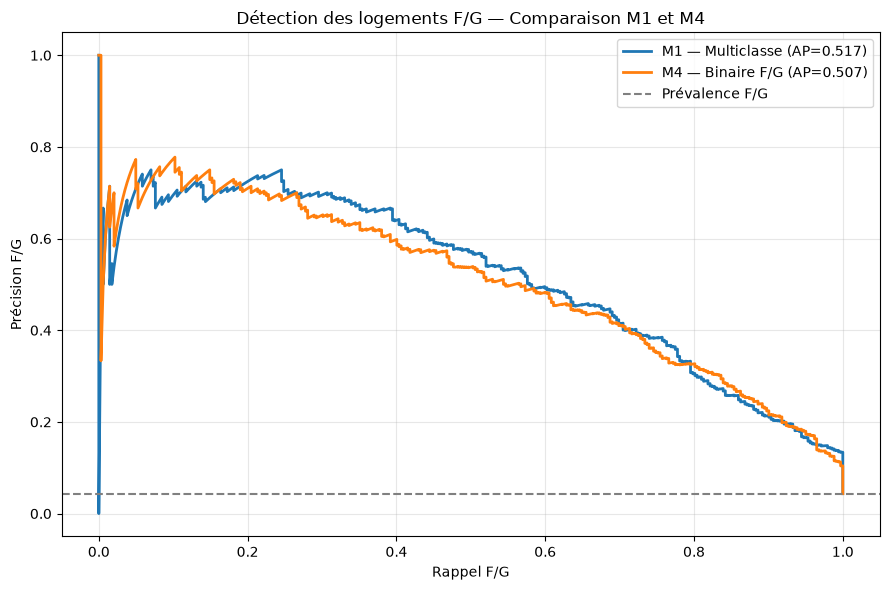

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve
)

# 1. Probabilités du modèle M1
proba_m1 = modele_diagnostic.predict_proba(
    val[variables_m4]
)

# Ordre des classes appris par M1
classes_m1 = modele_diagnostic.named_steps["modele"].classes_

# Additionner les probabilités des classes F et G
indices_fg = np.isin(classes_m1, ["F", "G"])

score_fg_m1 = proba_m1[:, indices_fg].sum(axis=1)

# 2. Probabilités du modèle M4
score_fg_m4 = proba_m4

# 3. Average Precision des deux modèles
ap_m1 = average_precision_score(
    y_val_fg,
    score_fg_m1
)

ap_m4 = average_precision_score(
    y_val_fg,
    score_fg_m4
)

comparaison_ap = pd.DataFrame({
    "Modele": ["M1_multiclasse", "M4_binaire_FG"],
    "Average_Precision": [
        round(ap_m1, 4),
        round(ap_m4, 4)
    ]
})

print("===== COMPARAISON AVERAGE PRECISION =====")
display(comparaison_ap)

print("\n===== ÉVOLUTION =====")
print(
    "Gain M4 :",
    round(ap_m4 - ap_m1, 4)
)

# 4. Courbes précision-rappel
precision_m1, rappel_m1, _ = precision_recall_curve(
    y_val_fg,
    score_fg_m1
)

precision_m4, rappel_m4, _ = precision_recall_curve(
    y_val_fg,
    score_fg_m4
)

plt.figure(figsize=(9, 6))

plt.plot(
    rappel_m1,
    precision_m1,
    label=f"M1 — Multiclasse (AP={ap_m1:.3f})",
    linewidth=2
)

plt.plot(
    rappel_m4,
    precision_m4,
    label=f"M4 — Binaire F/G (AP={ap_m4:.3f})",
    linewidth=2
)

plt.axhline(
    y=y_val_fg.mean(),
    color="gray",
    linestyle="--",
    label="Prévalence F/G"
)

plt.xlabel("Rappel F/G")
plt.ylabel("Précision F/G")

plt.title(
    "Détection des logements F/G — "
    "Comparaison M1 et M4"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusion de l'expérience 5 — Détection F/G

**Résultats**

Le modèle binaire M4 améliore légèrement le F1-score F/G :

- M1 : 0,495.
- M4 : 0,517.
- Gain : +0,022.

Cependant, l'analyse des probabilités donne :

- Average Precision M1 : 0,5170.
- Average Precision M4 : 0,5074.
- Différence : -0,0096.

**Interprétation**

Le modèle M4 obtient un meilleur F1-score avec sa règle de
décision actuelle, mais ne présente pas une meilleure capacité
globale à classer les logements selon leur risque F/G.

Les courbes précision-rappel sont relativement proches.

Le gain de M4 reste limité et n'est observé que sur un seul
découpage de validation.

**Décision**

Conserver M1 comme modèle de référence.

Ne pas retenir M4 comme modèle complémentaire à ce stade.

**Suite**

Étudier l'influence du mélange des logements existants
et neufs dans l'apprentissage.

### Expérience 6 — Influence du mélange existant / neuf

**Objectif**

Déterminer si l'entraînement sur les deux sources de données
améliore ou dégrade la prédiction des DPE des logements existants.

**Contexte**

Les logements existants et neufs présentent :
- Des répartitions de classes différentes.
- Des structures de valeurs manquantes très différentes.
- Des méthodes de production des DPE différentes.

**Configurations**

M1 : entraînement sur les logements existants et neufs.

M5 : entraînement uniquement sur les logements existants.

**Méthode**

Conserver les 23 variables et les mêmes paramètres Random Forest.

Évaluer les deux modèles sur les mêmes logements existants
de validation interne.

**Indicateurs**

- F1 macro sur les sept classes.
- Exactitude globale.
- Rappel F/G.
- F1 F/G.

**Hypothèse**

L'entraînement exclusivement sur les logements existants pourrait
améliorer la reconnaissance de leurs classes énergétiques.

Cette hypothèse doit être vérifiée expérimentalement.

In [37]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# Séparation des logements existants
fit_existant = fit[
    fit["source_jeu"] == "existant"
].copy()

val_existant = val[
    val["source_jeu"] == "existant"
].copy()

variables_m5 = variables_num + variables_cat

print("===== EFFECTIFS =====")
print("Entraînement existant :", len(fit_existant))
print("Validation existant :", len(val_existant))

# Modèle M5 : entraînement uniquement sur l'existant
modele_m5 = Pipeline([
    (
        "preparation",
        tf.construire_preprocesseur(
            variables_num,
            variables_cat,
            pour="arbres"
        )
    ),
    (
        "modele",
        RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

modele_m5.fit(
    fit_existant[variables_m5],
    fit_existant["etiquette_dpe"]
)

# Prédictions des deux modèles
# sur exactement les mêmes logements existants
pred_m1_existant = modele_diagnostic.predict(
    val_existant[variables_m5]
)

pred_m5_existant = modele_m5.predict(
    val_existant[variables_m5]
)

y_reel = val_existant["etiquette_dpe"]

resultats_m5 = []

for nom, pred in [
    ("M1_existant_et_neuf", pred_m1_existant),
    ("M5_existant_seul", pred_m5_existant)
]:

    reel_fg = y_reel.isin(["F", "G"])
    predit_fg = pd.Series(pred).isin(["F", "G"])

    resultats_m5.append({
        "Configuration": nom,

        "F1_macro": round(
            f1_score(
                y_reel,
                pred,
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ),
            4
        ),

        "Accuracy": round(
            accuracy_score(y_reel, pred),
            4
        ),

        "Rappel_FG": round(
            recall_score(
                reel_fg,
                predit_fg,
                zero_division=0
            ),
            4
        ),

        "F1_FG": round(
            f1_score(
                reel_fg,
                predit_fg,
                zero_division=0
            ),
            4
        )
    })

print("\n===== COMPARAISON M1 / M5 =====")

display(pd.DataFrame(resultats_m5))

===== EFFECTIFS =====
Entraînement existant : 29098
Validation existant : 7277

===== COMPARAISON M1 / M5 =====


,Configuration,F1_macro,Accuracy,Rappel_FG,F1_FG
0,M1_existant_et_neuf,0.5197,0.6222,0.4912,0.4948
1,M5_existant_seul,0.5280,0.6196,0.5058,0.5103


### Expérience 6 — Validation croisée M1 / M5

**Objectif**

Vérifier si l'entraînement uniquement sur les logements existants
améliore de manière régulière les performances de classification.

**Résultat initial**

Sur le premier découpage de validation :

- F1 macro M1 : 0,5197.
- F1 macro M5 : 0,5280.
- Gain : +0,0083.

- F1 F/G M1 : 0,4948.
- F1 F/G M5 : 0,5103.

**Méthode**

Réaliser une validation croisée à 5 plis en respectant
les groupes d'adresses.

Pour chaque pli :

1. Entraîner M1 sur les logements existants et neufs.
2. Entraîner M5 uniquement sur les logements existants.
3. Évaluer les deux modèles sur les mêmes logements existants.
4. Comparer F1 macro, accuracy, rappel F/G et F1 F/G.

**Critères de décision**

Examiner :
- Le gain moyen sur les 5 plis.
- La régularité du gain.
- Le nombre de plis améliorés.
- L'évolution de la détection F/G.

**Précaution**

Aucune modification du jeu de test final.

Le modèle M5 ne sera retenu que si les résultats
justifient une séparation des populations.

In [38]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score
)

# Variables communes aux deux modèles
variables_cv = variables_num + variables_cat

# Fonction de création du modèle
def creer_modele_rf():

    return Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                variables_num,
                variables_cat,
                pour="arbres"
            )
        ),
        (
            "modele",
            RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=3,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ])


# Validation croisée avec séparation par adresse
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_cv_m5 = []

for pli, (idx_fit, idx_val) in enumerate(
    cv.split(
        train,
        strates,
        groups=groupes
    ),
    start=1
):

    train_pli = train.iloc[idx_fit]
    val_pli = train.iloc[idx_val]

    # Validation uniquement sur les logements existants
    val_existant_pli = val_pli[
        val_pli["source_jeu"] == "existant"
    ]

    y_reel = val_existant_pli["etiquette_dpe"]

    # Comparaison des deux configurations
    configurations = {
        "M1_mixte": train_pli,
        "M5_existant": train_pli[
            train_pli["source_jeu"] == "existant"
        ]
    }

    print(f"\n===== PLI {pli}/5 =====")

    for nom, donnees_fit in configurations.items():

        modele = creer_modele_rf()

        modele.fit(
            donnees_fit[variables_cv],
            donnees_fit["etiquette_dpe"]
        )

        pred = modele.predict(
            val_existant_pli[variables_cv]
        )

        reel_fg = y_reel.isin(["F", "G"])
        pred_fg = np.isin(pred, ["F", "G"])

        ligne = {
            "Pli": pli,
            "Modele": nom,

            "F1_macro": f1_score(
                y_reel,
                pred,
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ),

            "Accuracy": accuracy_score(
                y_reel,
                pred
            ),

            "Rappel_FG": recall_score(
                reel_fg,
                pred_fg,
                zero_division=0
            ),

            "F1_FG": f1_score(
                reel_fg,
                pred_fg,
                zero_division=0
            )
        }

        resultats_cv_m5.append(ligne)

        print(
            f"{nom} : "
            f"F1 macro = {ligne['F1_macro']:.4f} | "
            f"F1 F/G = {ligne['F1_FG']:.4f}"
        )


# Tableau complet
resultats_cv_m5 = pd.DataFrame(resultats_cv_m5)

print("\n===== RÉSULTATS DES 5 PLIS =====")

display(
    resultats_cv_m5.round(4)
)


# Moyennes et écarts-types
print("\n===== SYNTHÈSE =====")

indicateurs = [
    "F1_macro",
    "Accuracy",
    "Rappel_FG",
    "F1_FG"
]

synthese = (
    resultats_cv_m5
    .groupby("Modele")[indicateurs]
    .agg(["mean", "std"])
    .round(4)
)

display(synthese)


# Gains de F1 macro sur chaque pli
comparaison_plis = resultats_cv_m5.pivot(
    index="Pli",
    columns="Modele",
    values="F1_macro"
)

comparaison_plis["Gain_M5"] = (
    comparaison_plis["M5_existant"]
    - comparaison_plis["M1_mixte"]
)

print("\n===== GAINS PAR PLI =====")

display(comparaison_plis.round(4))

print(
    "Gain moyen M5 :",
    round(comparaison_plis["Gain_M5"].mean(), 4)
)

print(
    "Nombre de plis améliorés :",
    (comparaison_plis["Gain_M5"] > 0).sum(),
    "/ 5"
)


===== PLI 1/5 =====
M1_mixte : F1 macro = 0.5197 | F1 F/G = 0.4948
M5_existant : F1 macro = 0.5280 | F1 F/G = 0.5103

===== PLI 2/5 =====
M1_mixte : F1 macro = 0.5106 | F1 F/G = 0.4801
M5_existant : F1 macro = 0.5034 | F1 F/G = 0.4776

===== PLI 3/5 =====
M1_mixte : F1 macro = 0.5035 | F1 F/G = 0.4177
M5_existant : F1 macro = 0.5075 | F1 F/G = 0.4305

===== PLI 4/5 =====
M1_mixte : F1 macro = 0.5265 | F1 F/G = 0.5036
M5_existant : F1 macro = 0.5286 | F1 F/G = 0.5265

===== PLI 5/5 =====
M1_mixte : F1 macro = 0.4957 | F1 F/G = 0.4506
M5_existant : F1 macro = 0.4957 | F1 F/G = 0.4585

===== RÉSULTATS DES 5 PLIS =====


,Pli,Modele,F1_macro,Accuracy,Rappel_FG,F1_FG
0,1,M1_mixte,0.5197,0.6222,0.4912,0.4948
1,1,M5_existant,0.5280,0.6196,0.5058,0.5103
2,2,M1_mixte,0.5106,0.6136,0.5117,0.4801
3,2,M5_existant,0.5034,0.6131,0.5146,0.4776
4,3,M1_mixte,0.5035,0.6128,0.4029,0.4177
5,3,M5_existant,0.5075,0.6108,0.4235,0.4305
6,4,M1_mixte,0.5265,0.6248,0.5206,0.5036
7,4,M5_existant,0.5286,0.6233,0.5412,0.5265
8,5,M1_mixte,0.4957,0.6052,0.4545,0.4506
9,5,M5_existant,0.4957,0.6059,0.4692,0.4585



===== SYNTHÈSE =====


F1_macro         Accuracy         Rappel_FG           F1_FG  \
                mean     std     mean     std      mean     std    mean   
Modele                                                                    
M1_mixte      0.5112  0.0123   0.6157  0.0079    0.4762  0.0482  0.4694   
M5_existant   0.5126  0.0149   0.6145  0.0069    0.4909  0.0456  0.4807   

                     
                std  
Modele               
M1_mixte     0.0352  
M5_existant  0.0387


===== GAINS PAR PLI =====


Modele,M1_mixte,M5_existant,Gain_M5
Pli,,,
1,0.5197,0.5280,0.0083
2,0.5106,0.5034,-0.0072
3,0.5035,0.5075,0.0039
4,0.5265,0.5286,0.0021
5,0.4957,0.4957,-0.0000


Gain moyen M5 : 0.0014
Nombre de plis améliorés : 3 / 5


### Conclusion de l'expérience 6 — Séparation existant / neuf

**Résultats de validation croisée à 5 plis**

| Indicateur | M1 mixte | M5 existant |
|---|---:|---:|
| F1 macro moyen | 0,5112 | 0,5126 |
| Accuracy moyenne | 0,6157 | 0,6145 |
| Rappel F/G moyen | 0,4762 | 0,4909 |
| F1 F/G moyen | 0,4694 | 0,4807 |

**Interprétation**

Le modèle entraîné uniquement sur les logements existants
obtient un gain moyen de F1 macro de 0,0014.

Ce gain est faible et irrégulier entre les cinq plis.

Le rappel F/G augmente légèrement dans chacun des cinq plis,
mais le modèle reste globalement peu performant sur ces classes.

**Conclusion**

Les différences importantes entre les données existantes et
neuves ne suffisent pas à démontrer qu'un entraînement séparé
améliore significativement la classification.

**Décision**

Conserver le modèle mixte M1 comme référence.

Ne pas retenir de séparation existant/neuf à ce stade.

**Suite**

Comparer plusieurs algorithmes de Machine Learning en conservant
le même jeu de données, les mêmes variables et le même découpage
de validation interne.

### Expérience 7 — Comparaison Random Forest / Extra Trees

**Objectif**

Évaluer si un changement d'algorithme permet d'améliorer
la classification DPE et la prédiction de consommation énergétique.

**Algorithmes comparés**

- M1 : Random Forest.
- M6 : Extra Trees.

**Conditions expérimentales**

- Même jeu d'entraînement.
- Même jeu de validation.
- Même sélection de 23 variables.
- Même préparation des données.
- Même graine aléatoire.
- Nombre d'arbres identique.

**Indicateurs**

Classification :
- F1 macro global.
- F1 macro existant.
- F1 macro neuf (A/B/C).
- F1 de détection F/G.

Régression :
- MAE globale.
- MAE existant.
- MAE neuf.

**Décision**

Comparer les résultats sur un premier pli.

Si M6 présente un intérêt, confirmer les résultats par
validation croisée à plusieurs plis avant de modifier
le modèle de référence.

In [39]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    RandomForestRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import (
    f1_score,
    mean_absolute_error
)

variables_m6 = variables_num + variables_cat

cible_regression = "conso_5_usages_par_m2_ep"

# Préparer les données de régression :
# conserver les observations non aberrantes avec cible renseignée
def preparer_regression(df):

    y = pd.to_numeric(
        df[cible_regression],
        errors="coerce"
    )

    masque = y.notna()

    if "conso_aberrante" in df.columns:
        masque &= (
            df["conso_aberrante"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["false", "0", "0.0"])
        )

    return df.loc[masque].copy(), y.loc[masque]


fit_reg, y_fit_reg = preparer_regression(fit)
val_reg, y_val_reg = preparer_regression(val)

# Modèles à comparer
configurations = {
    "M1_RandomForest": {
        "classification": RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ),
        "regression": RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    },

    "M6_ExtraTrees": {
        "classification": ExtraTreesClassifier(
            n_estimators=100,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "regression": ExtraTreesRegressor(
            n_estimators=100,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    }
}

resultats_algorithmes = []

for nom, config in configurations.items():

    print(f"\n===== {nom} =====")

    # CLASSIFICATION
    modele_clf = Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                variables_num,
                variables_cat,
                pour="arbres"
            )
        ),
        ("modele", config["classification"])
    ])

    modele_clf.fit(
        fit[variables_m6],
        fit["etiquette_dpe"]
    )

    pred_clf = modele_clf.predict(
        val[variables_m6]
    )

    masque_existant = val["source_jeu"] == "existant"
    masque_neuf = val["source_jeu"] == "neuf"

    reel_fg = val["etiquette_dpe"].isin(["F", "G"])
    predit_fg = np.isin(pred_clf, ["F", "G"])

    # RÉGRESSION
    modele_reg = Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                variables_num,
                variables_cat,
                pour="arbres"
            )
        ),
        ("modele", config["regression"])
    ])

    modele_reg.fit(
        fit_reg[variables_m6],
        y_fit_reg
    )

    pred_reg = modele_reg.predict(
        val_reg[variables_m6]
    )

    masque_reg_existant = (
        val_reg["source_jeu"] == "existant"
    )

    masque_reg_neuf = (
        val_reg["source_jeu"] == "neuf"
    )

    resultats_algorithmes.append({
        "Modele": nom,

        "F1_global": round(
            f1_score(
                val["etiquette_dpe"],
                pred_clf,
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ), 4
        ),

        "F1_existant": round(
            f1_score(
                val.loc[masque_existant, "etiquette_dpe"],
                pred_clf[masque_existant.to_numpy()],
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ), 4
        ),

        "F1_neuf_ABC": round(
            f1_score(
                val.loc[masque_neuf, "etiquette_dpe"],
                pred_clf[masque_neuf.to_numpy()],
                labels=list("ABC"),
                average="macro",
                zero_division=0
            ), 4
        ),

        "F1_FG": round(
            f1_score(
                reel_fg,
                predit_fg,
                zero_division=0
            ), 4
        ),

        "MAE_global": round(
            mean_absolute_error(
                y_val_reg,
                pred_reg
            ), 2
        ),

        "MAE_existant": round(
            mean_absolute_error(
                y_val_reg.loc[masque_reg_existant],
                pred_reg[masque_reg_existant.to_numpy()]
            ), 2
        ),

        "MAE_neuf": round(
            mean_absolute_error(
                y_val_reg.loc[masque_reg_neuf],
                pred_reg[masque_reg_neuf.to_numpy()]
            ), 2
        )
    })


print("\n===== COMPARAISON M1 / M6 =====")

display(
    pd.DataFrame(resultats_algorithmes)
)


===== M1_RandomForest =====

===== M6_ExtraTrees =====

===== COMPARAISON M1 / M6 =====


,Modele,F1_global,F1_existant,F1_neuf_ABC,F1_FG,MAE_global,MAE_existant,MAE_neuf
0,M1_RandomForest,0.5253,0.5197,0.7460,0.4948,29.25,30.99,8.04
1,M6_ExtraTrees,0.5085,0.5016,0.5336,0.5025,28.80,30.37,9.68


### Expérience 7 — Comparaison des algorithmes

**Objectif**

Comparer Random Forest et Extra Trees pour les deux tâches
du projet : classification DPE et régression énergétique.

**Résultats du premier pli**

Classification :
- F1 macro Random Forest : 0,5253.
- F1 macro Extra Trees : 0,5085.

Régression :
- MAE Random Forest : 29,25.
- MAE Extra Trees : 28,80.

**Interprétation**

Extra Trees dégrade la classification globale, notamment sur
les logements neufs.

En revanche, Extra Trees améliore légèrement la MAE globale
de régression et la MAE des logements existants.

La MAE des logements neufs se dégrade.

**Décision provisoire**

Conserver Random Forest comme référence de classification.

Poursuivre l'évaluation d'Extra Trees uniquement pour la
régression, à l'aide d'une validation croisée à cinq plis.

La sélection définitive de l'algorithme de régression
dépendra de la régularité des résultats et des performances
sur les différentes populations.

In [40]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)
from sklearn.metrics import mean_absolute_error

variables_reg = variables_num + variables_cat

# Modèles comparés
def creer_regresseur(nom):

    if nom == "RandomForest":
        estimateur = RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )

    elif nom == "ExtraTrees":
        estimateur = ExtraTreesRegressor(
            n_estimators=100,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )

    return Pipeline([
        (
            "preparation",
            tf.construire_preprocesseur(
                variables_num,
                variables_cat,
                pour="arbres"
            )
        ),
        ("modele", estimateur)
    ])


cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_cv_reg = []

for pli, (idx_fit, idx_val) in enumerate(
    cv.split(
        train,
        strates,
        groups=groupes
    ),
    start=1
):

    fit_pli = train.iloc[idx_fit]
    val_pli = train.iloc[idx_val]

    # Même filtrage des consommations aberrantes
    fit_reg_pli, y_fit = preparer_regression(fit_pli)
    val_reg_pli, y_val = preparer_regression(val_pli)

    masque_existant = (
        val_reg_pli["source_jeu"] == "existant"
    )

    masque_neuf = (
        val_reg_pli["source_jeu"] == "neuf"
    )

    masque_fg = (
        val_reg_pli["etiquette_dpe"].isin(["F", "G"])
    )

    print(f"\n===== PLI {pli}/5 =====")

    for nom in ["RandomForest", "ExtraTrees"]:

        modele = creer_regresseur(nom)

        modele.fit(
            fit_reg_pli[variables_reg],
            y_fit
        )

        predictions_reg = modele.predict(
            val_reg_pli[variables_reg]
        )

        resultats = {
            "Pli": pli,
            "Modele": nom,

            "MAE_global": mean_absolute_error(
                y_val,
                predictions_reg
            ),

            "MAE_existant": mean_absolute_error(
                y_val.loc[masque_existant],
                predictions_reg[masque_existant.to_numpy()]
            ),

            "MAE_neuf": mean_absolute_error(
                y_val.loc[masque_neuf],
                predictions_reg[masque_neuf.to_numpy()]
            ),

            "MAE_FG": mean_absolute_error(
                y_val.loc[masque_fg],
                predictions_reg[masque_fg.to_numpy()]
            )
        }

        resultats_cv_reg.append(resultats)

        print(
            f"{nom} : "
            f"MAE globale = {resultats['MAE_global']:.2f} | "
            f"MAE existant = {resultats['MAE_existant']:.2f} | "
            f"MAE neuf = {resultats['MAE_neuf']:.2f} | "
            f"MAE F/G = {resultats['MAE_FG']:.2f}"
        )


# Résultats détaillés
resultats_cv_reg = pd.DataFrame(resultats_cv_reg)

print("\n===== RÉSULTATS DES 5 PLIS =====")
display(resultats_cv_reg.round(2))


# Synthèse par algorithme
print("\n===== SYNTHÈSE RÉGRESSION =====")

indicateurs = [
    "MAE_global",
    "MAE_existant",
    "MAE_neuf",
    "MAE_FG"
]

synthese_reg = (
    resultats_cv_reg
    .groupby("Modele")[indicateurs]
    .agg(["mean", "std"])
    .round(2)
)

display(synthese_reg)


# Comparaison de la MAE globale sur chaque pli
comparaison_reg = resultats_cv_reg.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_global"
)

# Gain positif = Extra Trees meilleur
comparaison_reg["Gain_ExtraTrees"] = (
    comparaison_reg["RandomForest"]
    - comparaison_reg["ExtraTrees"]
)

print("\n===== GAINS PAR PLI =====")
display(comparaison_reg.round(2))

print(
    "Gain moyen Extra Trees :",
    round(comparaison_reg["Gain_ExtraTrees"].mean(), 3)
)

print(
    "Nombre de plis améliorés :",
    (comparaison_reg["Gain_ExtraTrees"] > 0).sum(),
    "/ 5"
)


===== PLI 1/5 =====
RandomForest : MAE globale = 29.25 | MAE existant = 30.99 | MAE neuf = 8.04 | MAE F/G = 110.99
ExtraTrees : MAE globale = 28.80 | MAE existant = 30.37 | MAE neuf = 9.68 | MAE F/G = 106.47

===== PLI 2/5 =====
RandomForest : MAE globale = 29.19 | MAE existant = 30.84 | MAE neuf = 8.40 | MAE F/G = 108.39
ExtraTrees : MAE globale = 28.63 | MAE existant = 30.20 | MAE neuf = 8.89 | MAE F/G = 104.67

===== PLI 3/5 =====
RandomForest : MAE globale = 31.07 | MAE existant = 33.06 | MAE neuf = 7.96 | MAE F/G = 142.29
ExtraTrees : MAE globale = 30.67 | MAE existant = 32.69 | MAE neuf = 7.23 | MAE F/G = 143.76

===== PLI 4/5 =====
RandomForest : MAE globale = 28.69 | MAE existant = 30.52 | MAE neuf = 6.80 | MAE F/G = 116.04
ExtraTrees : MAE globale = 28.41 | MAE existant = 30.14 | MAE neuf = 7.60 | MAE F/G = 112.45

===== PLI 5/5 =====
RandomForest : MAE globale = 29.21 | MAE existant = 30.87 | MAE neuf = 9.22 | MAE F/G = 105.82
ExtraTrees : MAE globale = 28.80 | MAE existant 

,Pli,Modele,MAE_global,MAE_existant,MAE_neuf,MAE_FG
0,1,RandomForest,29.25,30.99,8.04,110.99
1,1,ExtraTrees,28.80,30.37,9.68,106.47
2,2,RandomForest,29.19,30.84,8.40,108.39
3,2,ExtraTrees,28.63,30.20,8.89,104.67
4,3,RandomForest,31.07,33.06,7.96,142.29
5,3,ExtraTrees,30.67,32.69,7.23,143.76
6,4,RandomForest,28.69,30.52,6.80,116.04
7,4,ExtraTrees,28.41,30.14,7.60,112.45
8,5,RandomForest,29.21,30.87,9.22,105.82
9,5,ExtraTrees,28.80,30.37,9.83,103.07



===== SYNTHÈSE RÉGRESSION =====


MAE_global       MAE_existant       MAE_neuf        MAE_FG       
                   mean   std         mean   std     mean   std    mean    std
Modele                                                                        
ExtraTrees        29.06  0.92        30.75  1.09     8.65  1.19  114.08  16.97
RandomForest      29.48  0.92        31.25  1.02     8.08  0.87  116.71  14.79


===== GAINS PAR PLI =====


Modele,ExtraTrees,RandomForest,Gain_ExtraTrees
Pli,,,
1,28.80,29.25,0.45
2,28.63,29.19,0.56
3,30.67,31.07,0.39
4,28.41,28.69,0.28
5,28.80,29.21,0.41


Gain moyen Extra Trees : 0.42
Nombre de plis améliorés : 5 / 5


### Expérience 8 — Analyse des biais de régression par classe DPE

**Objectif**

Étudier les erreurs de prédiction de consommation énergétique
pour chaque classe DPE, en particulier E, F et G.

**Constat initial**

La validation croisée à 5 plis montre :

- MAE globale Extra Trees : 29,06 kWhEP/m²/an.
- MAE existant : 30,75.
- MAE neuf : 8,65.
- MAE F/G : 114,08.

La MAE des logements F/G est nettement supérieure
à celle de l'ensemble des logements.

**Hypothèse**

Les modèles pourraient sous-estimer les consommations élevées,
notamment pour les classes F et G.

**Méthode**

Calculer, pour chaque classe :

- Le nombre de logements.
- La consommation réelle médiane.
- La consommation prédite médiane.
- La MAE.
- Le biais moyen signé.

**Interprétation du biais**

Biais = prédiction - valeur réelle.

- Biais négatif : sous-estimation moyenne.
- Biais positif : surestimation moyenne.

**Précaution**

Les résultats sont calculés sur la validation interne,
sans utiliser le jeu de test final.

In [41]:
import numpy as np
import pandas as pd

# Reconstituer les données de régression
# du premier découpage interne
fit_reg_diag, y_fit_diag = preparer_regression(fit)
val_reg_diag, y_val_diag = preparer_regression(val)

variables_diag = variables_num + variables_cat

resultats_diagnostic = []

for nom in ["RandomForest", "ExtraTrees"]:

    print(f"Entraînement : {nom}")

    # Réutilise la fonction créée lors
    # de la validation croisée précédente
    modele = creer_regresseur(nom)

    modele.fit(
        fit_reg_diag[variables_diag],
        y_fit_diag
    )

    prediction = modele.predict(
        val_reg_diag[variables_diag]
    )

    tableau = pd.DataFrame({
        "Modele": nom,
        "Classe_DPE": val_reg_diag["etiquette_dpe"].to_numpy(),
        "Conso_reelle": y_val_diag.to_numpy(),
        "Conso_predite": prediction
    })

    # Erreur signée
    tableau["Biais"] = (
        tableau["Conso_predite"]
        - tableau["Conso_reelle"]
    )

    # Erreur absolue
    tableau["Erreur_absolue"] = tableau["Biais"].abs()

    resultats_diagnostic.append(tableau)


# Regrouper les deux modèles
diagnostic_regression = pd.concat(
    resultats_diagnostic,
    ignore_index=True
)

# Résultats par classe énergétique
comparaison_classes = (
    diagnostic_regression
    .groupby(["Modele", "Classe_DPE"])
    .agg(
        Nombre=("Conso_reelle", "size"),
        Conso_reelle_mediane=("Conso_reelle", "median"),
        Conso_predite_mediane=("Conso_predite", "median"),
        MAE=("Erreur_absolue", "mean"),
        Biais_moyen=("Biais", "mean")
    )
    .round(2)
)

print("\n===== ERREURS DE RÉGRESSION PAR CLASSE DPE =====")
display(comparaison_classes)


# Analyse ciblée sur E, F et G
print("\n===== FOCUS SUR LES CLASSES E / F / G =====")

focus_efg = (
    diagnostic_regression[
        diagnostic_regression["Classe_DPE"].isin(["E", "F", "G"])
    ]
    .groupby(["Modele", "Classe_DPE"])
    .agg(
        Nombre=("Conso_reelle", "size"),
        MAE=("Erreur_absolue", "mean"),
        Biais_moyen=("Biais", "mean")
    )
    .round(2)
)

display(focus_efg)

Entraînement : RandomForest
Entraînement : ExtraTrees

===== ERREURS DE RÉGRESSION PAR CLASSE DPE =====


Nombre  Conso_reelle_mediane  Conso_predite_mediane  \
Modele       Classe_DPE                                                        
ExtraTrees   A             1423                  42.0                  46.81   
             B             1351                  92.7                 109.19   
             C             2939                 135.0                 143.77   
             D             1273                 204.6                 194.15   
             E              545                 274.0                 237.42   
             F              234                 358.1                 270.16   
             G              108                 473.1                 346.26   
RandomForest A             1423                  42.0                  43.00   
             B             1351                  92.7                 103.33   
             C             2939                 135.0                 144.23   
             D             1273                 204.6                 194.88   
             E              545                 274.0                 237.76   
             F              234                 358.1                 271.46   
             G              108                 473.1                 335.77   

                            MAE  Biais_moyen  
Modele       Classe_DPE                       
ExtraTrees   A            12.13         8.79  
             B            21.78        17.06  
             C            23.83        11.39  
             D            33.63        -6.00  
             E            56.55       -33.69  
             F            88.57       -78.72  
             G           145.24      -143.42  
RandomForest A            10.00         5.15  
             B            22.34        12.67  
             C            25.24        11.98  
             D            34.14        -5.19  
             E            55.63       -33.24  
             F            89.72       -79.61  
             G           157.07      -155.65


===== FOCUS SUR LES CLASSES E / F / G =====


Nombre     MAE  Biais_moyen
Modele       Classe_DPE                             
ExtraTrees   E              545   56.55       -33.69
             F              234   88.57       -78.72
             G              108  145.24      -143.42
RandomForest E              545   55.63       -33.24
             F              234   89.72       -79.61
             G              108  157.07      -155.65

### Expérience 9 — Régression pondérée pour les fortes consommations

**Objectif**

Vérifier si un apprentissage pondéré permet de réduire
la sous-estimation des consommations élevées.

**Constat précédent**

Les modèles Random Forest et Extra Trees présentent
un biais de régression dépendant de la classe DPE.

Avec Extra Trees :

- Biais moyen A : +8,79 kWhEP/m²/an.
- Biais moyen E : -33,69.
- Biais moyen F : -78,72.
- Biais moyen G : -143,42.

**Hypothèse**

Accorder plus de poids aux logements fortement
consommateurs pourrait améliorer leur prédiction.

**Configurations**

M6 : Extra Trees sans pondération particulière.

M7 : Extra Trees avec pondération des observations :

- A, B, C, D : poids 1.
- E : poids 1,5.
- F : poids 2.
- G : poids 3.

Ces poids sont expérimentaux.

**Évaluation**

Comparer :
- MAE globale.
- MAE existant.
- MAE neuf.
- MAE F/G.
- Biais moyen F.
- Biais moyen G.

**Précaution**

Les classes DPE sont utilisées uniquement pour pondérer
les observations d'entraînement.

Elles ne sont pas fournies comme variables prédictives.

Les résultats d'un premier pli devront être confirmés
par validation croisée si l'approche paraît intéressante.

In [42]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error

# Données de régression du premier pli
fit_reg_m7, y_fit_m7 = preparer_regression(fit)
val_reg_m7, y_val_m7 = preparer_regression(val)

variables_m7 = variables_num + variables_cat

# Poids expérimentaux
poids_classes = {
    "A": 1.0,
    "B": 1.0,
    "C": 1.0,
    "D": 1.0,
    "E": 1.5,
    "F": 2.0,
    "G": 3.0
}

poids_entrainement = (
    fit_reg_m7["etiquette_dpe"]
    .map(poids_classes)
    .fillna(1.0)
)

print("===== RÉPARTITION DES POIDS =====")
display(poids_entrainement.value_counts().sort_index())

resultats_m7 = []

for nom in ["M6_ExtraTrees", "M7_ExtraTrees_pondere"]:

    print(f"\n===== {nom} =====")

    modele = creer_regresseur("ExtraTrees")

    if nom == "M7_ExtraTrees_pondere":

        modele.fit(
            fit_reg_m7[variables_m7],
            y_fit_m7,
            modele__sample_weight=poids_entrainement.to_numpy()
        )

    else:

        modele.fit(
            fit_reg_m7[variables_m7],
            y_fit_m7
        )

    predictions_m7 = modele.predict(
        val_reg_m7[variables_m7]
    )

    erreurs = (
        predictions_m7 - y_val_m7.to_numpy()
    )

    masque_existant = (
        val_reg_m7["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_reg_m7["source_jeu"] == "neuf"
    ).to_numpy()

    masque_fg = (
        val_reg_m7["etiquette_dpe"].isin(["F", "G"])
    ).to_numpy()

    masque_f = (
        val_reg_m7["etiquette_dpe"] == "F"
    ).to_numpy()

    masque_g = (
        val_reg_m7["etiquette_dpe"] == "G"
    ).to_numpy()

    resultats_m7.append({
        "Modele": nom,

        "MAE_global": round(
            np.abs(erreurs).mean(), 2
        ),

        "MAE_existant": round(
            np.abs(erreurs[masque_existant]).mean(), 2
        ),

        "MAE_neuf": round(
            np.abs(erreurs[masque_neuf]).mean(), 2
        ),

        "MAE_FG": round(
            np.abs(erreurs[masque_fg]).mean(), 2
        ),

        "Biais_F": round(
            erreurs[masque_f].mean(), 2
        ),

        "Biais_G": round(
            erreurs[masque_g].mean(), 2
        )
    })


print("\n===== COMPARAISON M6 / M7 =====")

display(
    pd.DataFrame(resultats_m7)
)

===== RÉPARTITION DES POIDS =====


etiquette_dpe
1.0    27973
1.5     2177
2.0      934
3.0      428
Name: count, dtype: int64


===== M6_ExtraTrees =====

===== M7_ExtraTrees_pondere =====

===== COMPARAISON M6 / M7 =====


,Modele,MAE_global,MAE_existant,MAE_neuf,MAE_FG,Biais_F,Biais_G
0,M6_ExtraTrees,28.80,30.37,9.68,106.47,-78.72,-143.42
1,M7_ExtraTrees_pondere,29.02,30.63,9.36,97.80,-68.26,-128.60


### Résultats de l'expérience 9 — Régression pondérée

**Configurations**

- M6 : Extra Trees standard.
- M7 : Extra Trees avec pondération des classes DPE.

**Résultats du premier pli**

| Indicateur | M6 | M7 |
|---|---:|---:|
| MAE globale | 28,80 | 29,02 |
| MAE existant | 30,37 | 30,63 |
| MAE neuf | 9,68 | 9,36 |
| MAE F/G | 106,47 | 97,80 |
| Biais F | -78,72 | -68,26 |
| Biais G | -143,42 | -128,60 |

**Interprétation**

La pondération permet de réduire la MAE des logements F/G
d'environ 8,1 %.

Elle diminue également leur sous-estimation moyenne.

En contrepartie, la MAE globale augmente légèrement,
d'environ 0,8 %.

**Limites**

Le résultat repose sur un seul découpage de validation.

Les poids sont expérimentaux et calculés à partir des classes
DPE, qui dépendent à la fois de la consommation énergétique
et des émissions de GES.

**Décision provisoire**

La pondération est une piste intéressante.

Confirmer les résultats par validation croisée à cinq plis
avant de retenir cette méthode.

In [43]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

# Poids expérimentaux
poids_classes = {
    "A": 1.0,
    "B": 1.0,
    "C": 1.0,
    "D": 1.0,
    "E": 1.5,
    "F": 2.0,
    "G": 3.0
}

variables_cv = variables_num + variables_cat

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_cv_pond = []

for pli, (idx_fit, idx_val) in enumerate(
    cv.split(
        train,
        strates,
        groups=groupes
    ),
    start=1
):

    fit_pli = train.iloc[idx_fit]
    val_pli = train.iloc[idx_val]

    # Exclure les consommations aberrantes
    fit_reg_pli, y_fit = preparer_regression(fit_pli)
    val_reg_pli, y_val = preparer_regression(val_pli)

    # Poids calculés UNIQUEMENT sur l'entraînement
    poids = (
        fit_reg_pli["etiquette_dpe"]
        .map(poids_classes)
        .fillna(1.0)
        .to_numpy()
    )

    masque_existant = (
        val_reg_pli["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_reg_pli["source_jeu"] == "neuf"
    ).to_numpy()

    masque_fg = (
        val_reg_pli["etiquette_dpe"].isin(["F", "G"])
    ).to_numpy()

    masque_f = (
        val_reg_pli["etiquette_dpe"] == "F"
    ).to_numpy()

    masque_g = (
        val_reg_pli["etiquette_dpe"] == "G"
    ).to_numpy()

    print(f"\n===== PLI {pli}/5 =====")

    for nom in ["M6_standard", "M7_pondere"]:

        modele = creer_regresseur("ExtraTrees")

        if nom == "M7_pondere":

            modele.fit(
                fit_reg_pli[variables_cv],
                y_fit,
                modele__sample_weight=poids
            )

        else:

            modele.fit(
                fit_reg_pli[variables_cv],
                y_fit
            )

        prediction = modele.predict(
            val_reg_pli[variables_cv]
        )

        erreurs = prediction - y_val.to_numpy()
        erreurs_absolues = np.abs(erreurs)

        resultats_cv_pond.append({
            "Pli": pli,
            "Modele": nom,

            "MAE_global": erreurs_absolues.mean(),

            "MAE_existant": (
                erreurs_absolues[masque_existant].mean()
            ),

            "MAE_neuf": (
                erreurs_absolues[masque_neuf].mean()
            ),

            "MAE_FG": (
                erreurs_absolues[masque_fg].mean()
            ),

            "Biais_F": erreurs[masque_f].mean(),

            "Biais_G": erreurs[masque_g].mean(),

            "WAPE_FG": (
                100
                * erreurs_absolues[masque_fg].sum()
                / np.abs(y_val.to_numpy()[masque_fg]).sum()
            )
        })

        print(
            f"{nom} : "
            f"MAE globale = {erreurs_absolues.mean():.2f} | "
            f"MAE F/G = {erreurs_absolues[masque_fg].mean():.2f}"
        )


# Tableau des résultats
resultats_cv_pond = pd.DataFrame(resultats_cv_pond)

print("\n===== RÉSULTATS PAR PLI =====")
display(resultats_cv_pond.round(2))


# Moyennes sur les 5 plis
print("\n===== SYNTHÈSE DES MOYENNES =====")

indicateurs = [
    "MAE_global",
    "MAE_existant",
    "MAE_neuf",
    "MAE_FG",
    "Biais_F",
    "Biais_G",
    "WAPE_FG"
]

synthese_pond = (
    resultats_cv_pond
    .groupby("Modele")[indicateurs]
    .mean()
    .round(2)
)

display(synthese_pond)


# Comparaison des gains sur chaque pli
mae_globale = resultats_cv_pond.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_global"
)

mae_fg = resultats_cv_pond.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_FG"
)

gains = pd.DataFrame({
    "Gain_FG": (
        mae_fg["M6_standard"]
        - mae_fg["M7_pondere"]
    ),

    "Cout_global": (
        mae_globale["M7_pondere"]
        - mae_globale["M6_standard"]
    )
})

print("\n===== COMPROMIS PAR PLI =====")
display(gains.round(2))

print(
    "\nPlis avec amélioration F/G :",
    (gains["Gain_FG"] > 0).sum(),
    "/ 5"
)

print(
    "Gain moyen F/G :",
    round(gains["Gain_FG"].mean(), 2)
)

print(
    "Coût moyen sur la MAE globale :",
    round(gains["Cout_global"].mean(), 2)
)


===== PLI 1/5 =====
M6_standard : MAE globale = 28.80 | MAE F/G = 106.47
M7_pondere : MAE globale = 29.02 | MAE F/G = 97.80

===== PLI 2/5 =====
M6_standard : MAE globale = 28.63 | MAE F/G = 104.67
M7_pondere : MAE globale = 29.28 | MAE F/G = 94.37

===== PLI 3/5 =====
M6_standard : MAE globale = 30.67 | MAE F/G = 143.76
M7_pondere : MAE globale = 30.92 | MAE F/G = 136.34

===== PLI 4/5 =====
M6_standard : MAE globale = 28.41 | MAE F/G = 112.45
M7_pondere : MAE globale = 28.77 | MAE F/G = 104.70

===== PLI 5/5 =====
M6_standard : MAE globale = 28.80 | MAE F/G = 103.07
M7_pondere : MAE globale = 29.17 | MAE F/G = 96.85

===== RÉSULTATS PAR PLI =====


,Pli,Modele,MAE_global,MAE_existant,MAE_neuf,MAE_FG,Biais_F,Biais_G,WAPE_FG
0,1,M6_standard,28.80,30.37,9.68,106.47,-78.72,-143.42,26.57
1,1,M7_pondere,29.02,30.63,9.36,97.80,-68.26,-128.60,24.41
2,2,M6_standard,28.63,30.20,8.89,104.67,-70.56,-152.29,26.23
3,2,M7_pondere,29.28,30.88,9.15,94.37,-58.57,-139.15,23.65
4,3,M6_standard,30.67,32.69,7.23,143.76,-101.92,-218.60,32.73
5,3,M7_pondere,30.92,32.97,7.03,136.34,-93.59,-206.32,31.04
6,4,M6_standard,28.41,30.14,7.60,112.45,-72.16,-164.99,27.77
7,4,M7_pondere,28.77,30.51,7.81,104.70,-62.20,-152.65,25.85
8,5,M6_standard,28.80,30.37,9.83,103.07,-77.21,-128.92,26.50
9,5,M7_pondere,29.17,30.79,9.69,96.85,-68.19,-117.09,24.91



===== SYNTHÈSE DES MOYENNES =====


,MAE_global,MAE_existant,MAE_neuf,MAE_FG,Biais_F,Biais_G,WAPE_FG
Modele,,,,,,,
M6_standard,29.06,30.75,8.65,114.08,-80.11,-161.64,27.96
M7_pondere,29.43,31.16,8.61,106.01,-70.16,-148.76,25.97



===== COMPROMIS PAR PLI =====


,Gain_FG,Cout_global
Pli,,
1,8.67,0.22
2,10.29,0.65
3,7.43,0.24
4,7.76,0.36
5,6.22,0.37



Plis avec amélioration F/G : 5 / 5
Gain moyen F/G : 8.07
Coût moyen sur la MAE globale : 0.37


### Expérience 10 — Pondération selon la consommation énergétique

**Objectif**

Comparer une pondération fondée sur les classes DPE à une
pondération directement liée à la consommation énergétique.

**Résultats précédents**

La pondération M7 améliore la MAE F/G sur les cinq plis :

- M6 : 114,08 kWhEP/m²/an.
- M7 : 106,01 kWhEP/m²/an.

La MAE globale augmente cependant :

- M6 : 29,06.
- M7 : 29,43.

**Limite de M7**

Les poids sont calculés à partir de la classe DPE,
qui dépend de la consommation et des émissions de GES.

**Nouvelle hypothèse**

Une pondération directement liée aux fortes consommations
pourrait réduire leur sous-estimation sans introduire
le classement DPE dans la définition des poids.

**Configuration M8**

Les poids sont définis à partir des quantiles de consommation
calculés uniquement sur les données d'entraînement :

- Consommation inférieure au 80e percentile : poids 1.
- Entre les 80e et 95e percentiles : poids 1,25.
- À partir du 95e percentile : poids 2.

**Évaluation**

Validation croisée à cinq plis avec séparation par adresse.

Comparaison de M6, M7 et M8 sur :

- MAE globale.
- MAE existant.
- MAE neuf.
- MAE F/G.
- WAPE F/G.
- Biais moyen F et G.

**Précaution**

Les poids sont expérimentaux.

Les quantiles et les poids sont calculés uniquement à partir
de la partie entraînement de chaque pli.

Aucune information issue de la validation ou du test final
n'est utilisée pour définir les poids.

In [44]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

variables_m8 = variables_num + variables_cat

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_m8 = []

for pli, (idx_fit, idx_val) in enumerate(
    cv.split(
        train,
        strates,
        groups=groupes
    ),
    start=1
):

    fit_pli = train.iloc[idx_fit]
    val_pli = train.iloc[idx_val]

    # Données de régression
    fit_reg_pli, y_fit = preparer_regression(fit_pli)
    val_reg_pli, y_val = preparer_regression(val_pli)

    # Seuils calculés uniquement sur l'entraînement
    q80 = y_fit.quantile(0.80)
    q95 = y_fit.quantile(0.95)

    # Pondération selon la consommation
    poids_m8 = np.select(
        [
            y_fit.to_numpy() >= q95,
            y_fit.to_numpy() >= q80
        ],
        [
            2.0,
            1.25
        ],
        default=1.0
    )

    print(f"\n===== PLI {pli}/5 =====")
    print(f"Seuil 80 % : {q80:.2f}")
    print(f"Seuil 95 % : {q95:.2f}")

    # Modèle Extra Trees
    modele_m8 = creer_regresseur("ExtraTrees")

    modele_m8.fit(
        fit_reg_pli[variables_m8],
        y_fit,
        modele__sample_weight=poids_m8
    )

    prediction = modele_m8.predict(
        val_reg_pli[variables_m8]
    )

    erreurs = prediction - y_val.to_numpy()
    erreurs_absolues = np.abs(erreurs)

    masque_existant = (
        val_reg_pli["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_reg_pli["source_jeu"] == "neuf"
    ).to_numpy()

    masque_fg = (
        val_reg_pli["etiquette_dpe"].isin(["F", "G"])
    ).to_numpy()

    masque_f = (
        val_reg_pli["etiquette_dpe"] == "F"
    ).to_numpy()

    masque_g = (
        val_reg_pli["etiquette_dpe"] == "G"
    ).to_numpy()

    resultats_m8.append({
        "Pli": pli,
        "Modele": "M8_consommation",

        "MAE_global": erreurs_absolues.mean(),

        "MAE_existant": (
            erreurs_absolues[masque_existant].mean()
        ),

        "MAE_neuf": (
            erreurs_absolues[masque_neuf].mean()
        ),

        "MAE_FG": (
            erreurs_absolues[masque_fg].mean()
        ),

        "Biais_F": erreurs[masque_f].mean(),

        "Biais_G": erreurs[masque_g].mean(),

        "WAPE_FG": (
            100
            * erreurs_absolues[masque_fg].sum()
            / np.abs(y_val.to_numpy()[masque_fg]).sum()
        )
    })

    print(
        "MAE globale :",
        round(erreurs_absolues.mean(), 2)
    )

    print(
        "MAE F/G :",
        round(erreurs_absolues[masque_fg].mean(), 2)
    )


# Résultats M8
resultats_m8 = pd.DataFrame(resultats_m8)

print("\n===== RÉSULTATS M8 =====")
display(resultats_m8.round(2))


# Réunir les trois configurations
comparaison_m678 = pd.concat(
    [
        resultats_cv_pond,
        resultats_m8
    ],
    ignore_index=True
)

# Comparaison des moyennes
indicateurs = [
    "MAE_global",
    "MAE_existant",
    "MAE_neuf",
    "MAE_FG",
    "WAPE_FG",
    "Biais_F",
    "Biais_G"
]

print("\n===== COMPARAISON M6 / M7 / M8 =====")

synthese_m678 = (
    comparaison_m678
    .groupby("Modele")[indicateurs]
    .mean()
    .round(2)
)

display(synthese_m678)


# Comparaison M7 / M8 pli par pli
mae_fg = comparaison_m678.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_FG"
)

mae_globale = comparaison_m678.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_global"
)

gains_m8 = pd.DataFrame({
    "Gain_FG_M8_vs_M7": (
        mae_fg["M7_pondere"]
        - mae_fg["M8_consommation"]
    ),

    "Gain_global_M8_vs_M7": (
        mae_globale["M7_pondere"]
        - mae_globale["M8_consommation"]
    )
})

print("\n===== GAINS M8 PAR RAPPORT À M7 =====")
display(gains_m8.round(2))

print(
    "\nPlis où M8 améliore la MAE F/G par rapport à M7 :",
    (gains_m8["Gain_FG_M8_vs_M7"] > 0).sum(),
    "/ 5"
)


===== PLI 1/5 =====
Seuil 80 % : 201.10
Seuil 95 % : 317.00
MAE globale : 29.03
MAE F/G : 101.01

===== PLI 2/5 =====
Seuil 80 % : 201.12
Seuil 95 % : 316.55
MAE globale : 28.94
MAE F/G : 97.39

===== PLI 3/5 =====
Seuil 80 % : 201.20
Seuil 95 % : 314.90
MAE globale : 30.65
MAE F/G : 136.91

===== PLI 4/5 =====
Seuil 80 % : 202.00
Seuil 95 % : 318.60
MAE globale : 28.59
MAE F/G : 106.68

===== PLI 5/5 =====
Seuil 80 % : 201.60
Seuil 95 % : 318.00
MAE globale : 29.0
MAE F/G : 98.19

===== RÉSULTATS M8 =====


,Pli,Modele,MAE_global,MAE_existant,MAE_neuf,MAE_FG,Biais_F,Biais_G,WAPE_FG
0,1,M8_consommation,29.03,30.59,9.95,101.01,-71.50,-134.81,25.21
1,2,M8_consommation,28.94,30.51,9.24,97.39,-62.24,-143.48,24.40
2,3,M8_consommation,30.65,32.71,6.73,136.91,-94.58,-207.49,31.17
3,4,M8_consommation,28.59,30.29,8.22,106.68,-65.10,-157.17,26.34
4,5,M8_consommation,29.00,30.62,9.57,98.19,-70.84,-120.35,25.25



===== COMPARAISON M6 / M7 / M8 =====


,MAE_global,MAE_existant,MAE_neuf,MAE_FG,WAPE_FG,Biais_F,Biais_G
Modele,,,,,,,
M6_standard,29.06,30.75,8.65,114.08,27.96,-80.11,-161.64
M7_pondere,29.43,31.16,8.61,106.01,25.97,-70.16,-148.76
M8_consommation,29.24,30.94,8.74,108.04,26.47,-72.85,-152.66



===== GAINS M8 PAR RAPPORT À M7 =====


,Gain_FG_M8_vs_M7,Gain_global_M8_vs_M7
Pli,,
1,-3.21,-0.01
2,-3.02,0.34
3,-0.57,0.26
4,-1.98,0.18
5,-1.34,0.16



Plis où M8 améliore la MAE F/G par rapport à M7 : 0 / 5


### Conclusion des expériences de pondération

**Résultats moyens sur cinq plis**

| Modèle | MAE globale | MAE F/G | WAPE F/G |
|---|---:|---:|---:|
| M6 standard | 29,06 | 114,08 | 27,96 % |
| M7 pondération DPE | 29,43 | 106,01 | 25,97 % |
| M8 pondération consommation | 29,24 | 108,04 | 26,47 % |

**Interprétation**

Les deux stratégies de pondération réduisent la MAE des
logements F/G, au prix d'une légère augmentation
de la MAE globale.

M7 apporte la plus forte amélioration sur F/G.

M8 constitue un compromis intermédiaire entre M6 et M7.

**Limites**

Les pondérations sont expérimentales.

M7 et M8 utilisent des intensités et des critères
de pondération différents.

Les résultats ne permettent donc pas d'affirmer
qu'un critère de pondération est intrinsèquement
supérieur à l'autre.

**Décision**

Conserver M6, M7 et M8 comme configurations de référence
pour de futures comparaisons.

Ne pas modifier le modèle final à ce stade.

Poursuivre la recherche avec un algorithme différent,
adapté aux données tabulaires mixtes.

4. Étape 1 — Vérifier si CatBoost est installé

In [46]:
import importlib.util

print(
    "CatBoost installé :",
    importlib.util.find_spec("catboost") is not None
)

CatBoost installé : False


In [47]:
%pip install catboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    --------------------------------------- 1.6/101.7 MB 9.1 MB/s eta 0:00:11
   - -------------------------------------- 3.9/101.7 MB 10.5 MB/s eta 0:00:10
   -- ------------------------------------- 6.0/101.7 MB 10.2 MB/s eta 0:00:10
   --- ------------------------------------ 7.9/101.7 MB 10.2 MB/s eta 0:00:10
   --- ------------------------------------ 10.0/101.7 MB 9.9 MB/s eta 0:00:10
   ---- ----------------------------------- 11.5/101.7 MB 9.6 MB/s eta 0:00:10
   ----- ---------------------------------- 13.1/101.7 MB 9.3 MB/s eta 0:00:10
   ----- ---------------------------------- 14.9/101.7 MB 9.2 MB/s eta 0:00:10
   ------ --------------------------------- 16.3/101.7 MB 8.9 MB/s eta 0:00:10
   ------ --------------------------------- 17.6/101.7 MB 8.7 MB/s eta 0:00:10
   ------- -------------------------------- 18.6/101.7 MB 8.4 

### Expérience 11 — Régression avec CatBoost

**Objectif**

Comparer Extra Trees et CatBoost sur la prédiction
de consommation énergétique.

**Motivation**

Les données comprennent 6 variables numériques et
17 variables catégorielles.

Les modèles précédents reposent sur un encodage ordinal
des variables catégorielles.

CatBoost permet de traiter directement ces catégories.

**Configurations**

- M6 : Extra Trees standard.
- M9 : CatBoost standard, sans pondération.

**Méthode**

Utiliser les mêmes observations d'entraînement et
de validation interne, les mêmes 23 variables et
le même filtrage des consommations aberrantes.

**Indicateurs**

- MAE globale.
- MAE existant.
- MAE neuf.
- MAE F/G.
- WAPE F/G.
- Biais F.
- Biais G.

**Décision**

Comparer les résultats sur un premier pli.

Si CatBoost présente un intérêt, confirmer les résultats
par validation croisée à cinq plis.

In [48]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor

# Variables du projet
variables_cb = variables_num + variables_cat

# Données du premier découpage
fit_reg_cb, y_fit_cb = preparer_regression(fit)
val_reg_cb, y_val_cb = preparer_regression(val)


# Préparation adaptée à CatBoost
def preparer_catboost(df):

    X = df[variables_cb].copy()

    # Numériques : conserver les nombres et NaN
    for col in variables_num:
        X[col] = pd.to_numeric(
            X[col],
            errors="coerce"
        )

    # Catégorielles : convertir en chaînes
    # et représenter explicitement les valeurs manquantes
    for col in variables_cat:
        X[col] = (
            X[col]
            .astype("string")
            .fillna("__MANQUANT__")
            .astype(str)
        )

    return X


X_fit_cb = preparer_catboost(fit_reg_cb)
X_val_cb = preparer_catboost(val_reg_cb)


# Modèle CatBoost
modele_m9 = CatBoostRegressor(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1,
    allow_writing_files=False
)

print("===== ENTRAÎNEMENT CATBOOST =====")

modele_m9.fit(
    X_fit_cb,
    y_fit_cb,
    cat_features=variables_cat
)

pred_m9 = modele_m9.predict(X_val_cb)


# Comparaison avec Extra Trees
modele_m6_comparaison = creer_regresseur("ExtraTrees")

modele_m6_comparaison.fit(
    fit_reg_cb[variables_cb],
    y_fit_cb
)

pred_m6 = modele_m6_comparaison.predict(
    val_reg_cb[variables_cb]
)


# Évaluation des deux modèles
resultats_cb = []

for nom, pred in [
    ("M6_ExtraTrees", pred_m6),
    ("M9_CatBoost", pred_m9)
]:

    erreurs = pred - y_val_cb.to_numpy()
    erreurs_absolues = np.abs(erreurs)

    masque_existant = (
        val_reg_cb["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_reg_cb["source_jeu"] == "neuf"
    ).to_numpy()

    masque_fg = (
        val_reg_cb["etiquette_dpe"].isin(["F", "G"])
    ).to_numpy()

    masque_f = (
        val_reg_cb["etiquette_dpe"] == "F"
    ).to_numpy()

    masque_g = (
        val_reg_cb["etiquette_dpe"] == "G"
    ).to_numpy()

    resultats_cb.append({
        "Modele": nom,

        "MAE_global": round(
            erreurs_absolues.mean(), 2
        ),

        "MAE_existant": round(
            erreurs_absolues[masque_existant].mean(), 2
        ),

        "MAE_neuf": round(
            erreurs_absolues[masque_neuf].mean(), 2
        ),

        "MAE_FG": round(
            erreurs_absolues[masque_fg].mean(), 2
        ),

        "WAPE_FG": round(
            100 * erreurs_absolues[masque_fg].sum()
            / np.abs(y_val_cb.to_numpy()[masque_fg]).sum(),
            2
        ),

        "Biais_F": round(
            erreurs[masque_f].mean(), 2
        ),

        "Biais_G": round(
            erreurs[masque_g].mean(), 2
        )
    })


print("\n===== COMPARAISON M6 / M9 =====")

display(pd.DataFrame(resultats_cb))

===== ENTRAÎNEMENT CATBOOST =====

===== COMPARAISON M6 / M9 =====


,Modele,MAE_global,MAE_existant,MAE_neuf,MAE_FG,WAPE_FG,Biais_F,Biais_G
0,M6_ExtraTrees,28.80,30.37,9.68,106.47,26.57,-78.72,-143.42
1,M9_CatBoost,26.03,27.34,10.04,99.34,24.79,-69.73,-139.48


### Résultats de l'expérience 11 — CatBoost

**Objectif**

Comparer Extra Trees et CatBoost pour la prédiction de
consommation énergétique.

**Résultats du premier pli**

| Indicateur | Extra Trees | CatBoost |
|---|---:|---:|
| MAE globale | 28,80 | 26,03 |
| MAE existant | 30,37 | 27,34 |
| MAE neuf | 9,68 | 10,04 |
| MAE F/G | 106,47 | 99,34 |
| WAPE F/G | 26,57 % | 24,79 % |

**Interprétation**

CatBoost améliore la MAE globale d'environ 9,6 %
par rapport à Extra Trees.

L'amélioration concerne principalement les logements
existants et les classes F/G.

La MAE des logements neufs augmente légèrement.

La sous-estimation des consommations élevées diminue,
mais reste importante pour les logements G.

**Limites**

Les résultats reposent sur un seul découpage de validation.

Les deux configurations diffèrent par leur algorithme,
leur traitement des variables catégorielles et certains
hyperparamètres.

Le gain ne peut donc pas être attribué à une seule
caractéristique de CatBoost.

**Décision provisoire**

CatBoost devient un candidat prioritaire pour la régression.

Confirmer les résultats par validation croisée à cinq plis,
avec séparation des adresses.

In [49]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import StratifiedGroupKFold

variables_cb_cv = variables_num + variables_cat

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_m9_cv = []

for pli, (idx_fit, idx_val) in enumerate(
    cv.split(
        train,
        strates,
        groups=groupes
    ),
    start=1
):

    fit_pli = train.iloc[idx_fit]
    val_pli = train.iloc[idx_val]

    # Même filtrage que les modèles précédents
    fit_reg_pli, y_fit = preparer_regression(fit_pli)
    val_reg_pli, y_val = preparer_regression(val_pli)

    # Préparation adaptée à CatBoost
    X_fit = preparer_catboost(fit_reg_pli)
    X_val = preparer_catboost(val_reg_pli)

    modele = CatBoostRegressor(
        iterations=600,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        thread_count=-1,
        allow_writing_files=False
    )

    print(f"\n===== PLI {pli}/5 =====")

    modele.fit(
        X_fit,
        y_fit,
        cat_features=variables_cat
    )

    prediction = modele.predict(X_val)

    erreurs = prediction - y_val.to_numpy()
    erreurs_absolues = np.abs(erreurs)

    masque_existant = (
        val_reg_pli["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_reg_pli["source_jeu"] == "neuf"
    ).to_numpy()

    masque_fg = (
        val_reg_pli["etiquette_dpe"].isin(["F", "G"])
    ).to_numpy()

    masque_f = (
        val_reg_pli["etiquette_dpe"] == "F"
    ).to_numpy()

    masque_g = (
        val_reg_pli["etiquette_dpe"] == "G"
    ).to_numpy()

    resultats_m9_cv.append({
        "Pli": pli,
        "Modele": "M9_CatBoost",

        "MAE_global": erreurs_absolues.mean(),

        "MAE_existant": (
            erreurs_absolues[masque_existant].mean()
        ),

        "MAE_neuf": (
            erreurs_absolues[masque_neuf].mean()
        ),

        "MAE_FG": (
            erreurs_absolues[masque_fg].mean()
        ),

        "WAPE_FG": (
            100
            * erreurs_absolues[masque_fg].sum()
            / np.abs(y_val.to_numpy()[masque_fg]).sum()
        ),

        "Biais_F": erreurs[masque_f].mean(),

        "Biais_G": erreurs[masque_g].mean()
    })

    print(
        "MAE globale :",
        round(erreurs_absolues.mean(), 2)
    )

    print(
        "MAE F/G :",
        round(erreurs_absolues[masque_fg].mean(), 2)
    )


# Résultats CatBoost
resultats_m9_cv = pd.DataFrame(resultats_m9_cv)

print("\n===== RÉSULTATS CATBOOST PAR PLI =====")
display(resultats_m9_cv.round(2))


# Réunir les quatre configurations déjà testées
comparaison_finale_reg = pd.concat(
    [
        resultats_cv_pond,
        resultats_m8,
        resultats_m9_cv
    ],
    ignore_index=True
)

indicateurs = [
    "MAE_global",
    "MAE_existant",
    "MAE_neuf",
    "MAE_FG",
    "WAPE_FG",
    "Biais_F",
    "Biais_G"
]

print("\n===== COMPARAISON M6 / M7 / M8 / M9 =====")

synthese_finale_reg = (
    comparaison_finale_reg
    .groupby("Modele")[indicateurs]
    .mean()
    .round(2)
)

display(synthese_finale_reg)


# Comparaison CatBoost / Extra Trees par pli
mae_global = comparaison_finale_reg.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_global"
)

mae_fg = comparaison_finale_reg.pivot(
    index="Pli",
    columns="Modele",
    values="MAE_FG"
)

gains_catboost = pd.DataFrame({
    "Gain_global_M9_vs_M6": (
        mae_global["M6_standard"]
        - mae_global["M9_CatBoost"]
    ),

    "Gain_FG_M9_vs_M6": (
        mae_fg["M6_standard"]
        - mae_fg["M9_CatBoost"]
    ),

    "Gain_FG_M9_vs_M7": (
        mae_fg["M7_pondere"]
        - mae_fg["M9_CatBoost"]
    )
})

print("\n===== GAINS CATBOOST PAR PLI =====")
display(gains_catboost.round(2))

print(
    "\nNombre de plis où CatBoost améliore la MAE globale :",
    (gains_catboost["Gain_global_M9_vs_M6"] > 0).sum(),
    "/ 5"
)

print(
    "Gain global moyen CatBoost :",
    round(gains_catboost["Gain_global_M9_vs_M6"].mean(), 2)
)


===== PLI 1/5 =====
MAE globale : 26.03
MAE F/G : 99.34

===== PLI 2/5 =====
MAE globale : 26.46
MAE F/G : 96.44

===== PLI 3/5 =====
MAE globale : 27.2
MAE F/G : 119.67

===== PLI 4/5 =====
MAE globale : 26.36
MAE F/G : 102.81

===== PLI 5/5 =====
MAE globale : 26.69
MAE F/G : 96.08

===== RÉSULTATS CATBOOST PAR PLI =====


,Pli,Modele,MAE_global,MAE_existant,MAE_neuf,MAE_FG,WAPE_FG,Biais_F,Biais_G
0,1,M9_CatBoost,26.03,27.34,10.04,99.34,24.79,-69.73,-139.48
1,2,M9_CatBoost,26.46,27.89,8.36,96.44,24.17,-60.92,-140.19
2,3,M9_CatBoost,27.20,28.91,7.27,119.67,27.24,-83.27,-178.25
3,4,M9_CatBoost,26.36,27.80,9.05,102.81,25.39,-68.43,-150.11
4,5,M9_CatBoost,26.69,28.08,9.94,96.08,24.71,-69.41,-122.45



===== COMPARAISON M6 / M7 / M8 / M9 =====


,MAE_global,MAE_existant,MAE_neuf,MAE_FG,WAPE_FG,Biais_F,Biais_G
Modele,,,,,,,
M6_standard,29.06,30.75,8.65,114.08,27.96,-80.11,-161.64
M7_pondere,29.43,31.16,8.61,106.01,25.97,-70.16,-148.76
M8_consommation,29.24,30.94,8.74,108.04,26.47,-72.85,-152.66
M9_CatBoost,26.55,28.01,8.93,102.87,25.26,-70.35,-146.10



===== GAINS CATBOOST PAR PLI =====


,Gain_global_M9_vs_M6,Gain_FG_M9_vs_M6,Gain_FG_M9_vs_M7
Pli,,,
1,2.77,7.13,-1.54
2,2.17,8.23,-2.06
3,3.47,24.10,16.67
4,2.05,9.64,1.89
5,2.11,6.99,0.77



Nombre de plis où CatBoost améliore la MAE globale : 5 / 5
Gain global moyen CatBoost : 2.52


### Conclusion de l'expérience 11 — CatBoost en régression

**Validation croisée à 5 plis**

| Indicateur | Extra Trees | CatBoost |
|---|---:|---:|
| MAE globale | 29,06 | 26,55 |
| MAE existant | 30,75 | 28,01 |
| MAE neuf | 8,65 | 8,93 |
| MAE F/G | 114,08 | 102,87 |
| WAPE F/G | 27,96 % | 25,26 % |

**Interprétation**

CatBoost améliore la MAE globale d'environ 8,6 % par rapport
à Extra Trees.

Le gain est observé sur les cinq plis de validation.

La MAE F/G diminue également sur les cinq plis.

La MAE des logements neufs augmente légèrement.

Le biais négatif des consommations élevées diminue,
mais reste important.

**Décision**

Retenir CatBoost comme nouveau modèle de référence provisoire
pour la régression.

Conserver les résultats des modèles précédents pour assurer
la traçabilité des expériences.

**Limites**

La sélection des 23 variables n'a pas encore été réévaluée
avec CatBoost.

Les hyperparamètres CatBoost n'ont pas été optimisés.

Le jeu de test final n'a pas été utilisé.

**Suite**

Tester CatBoost pour la classification DPE en comparant
une version sans pondération et une version avec
équilibrage automatique des classes.

### Expérience 12 — CatBoost pour la classification DPE

**Objectif**

Comparer Random Forest et CatBoost pour prédire
les sept classes énergétiques A à G.

**Motivation**

CatBoost a amélioré la régression de consommation
sur les cinq plis de validation.

Il est donc pertinent d'évaluer cet algorithme
pour la classification DPE.

**Configurations**

- M1 : Random Forest, modèle de référence.
- M10 : CatBoost sans pondération des classes.
- M11 : CatBoost avec pondération automatique Balanced.

**Conditions expérimentales**

- Même jeu d'entraînement.
- Même jeu de validation interne.
- Même sélection de 23 variables.
- Même séparation des adresses.

**Indicateurs**

- F1 macro global.
- F1 macro existant.
- F1 macro neuf (A/B/C).
- F1 F/G.
- Rappel F/G.
- Accuracy globale.

**Décision**

Comparer les trois modèles sur un premier pli.

Si une configuration CatBoost apporte une amélioration
intéressante, confirmer par validation croisée à cinq plis.

In [50]:
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

variables_clf = variables_num + variables_cat

# Préparation des données
X_fit_clf = preparer_catboost(fit)
X_val_clf = preparer_catboost(val)

y_fit_clf = fit["etiquette_dpe"].astype(str)
y_val_clf = val["etiquette_dpe"].astype(str)

# Conserver les prédictions pour les analyses suivantes
predictions_modeles = {}

# Référence Random Forest déjà entraînée
predictions_modeles["M1_RandomForest"] = (
    modele_diagnostic.predict(
        val[variables_clf]
    )
)

# Configurations CatBoost
configurations_clf = {
    "M10_CatBoost_standard": None,
    "M11_CatBoost_balanced": "Balanced"
}

modeles_catboost_clf = {}

for nom, ponderation in configurations_clf.items():

    print(f"\n===== ENTRAÎNEMENT {nom} =====")

    modele = CatBoostClassifier(
        iterations=600,
        depth=6,
        learning_rate=0.05,
        loss_function="MultiClass",
        auto_class_weights=ponderation,
        random_seed=42,
        verbose=False,
        thread_count=-1,
        allow_writing_files=False
    )

    modele.fit(
        X_fit_clf,
        y_fit_clf,
        cat_features=variables_cat
    )

    prediction = modele.predict(
        X_val_clf,
        prediction_type="Class"
    )

    predictions_modeles[nom] = (
        np.asarray(prediction)
        .ravel()
        .astype(str)
    )

    modeles_catboost_clf[nom] = modele


# Comparaison des trois configurations
resultats_classification = []

masque_existant = (
    val["source_jeu"] == "existant"
).to_numpy()

masque_neuf = (
    val["source_jeu"] == "neuf"
).to_numpy()

reel_fg = y_val_clf.isin(["F", "G"])

for nom, pred in predictions_modeles.items():

    pred = np.asarray(pred).ravel().astype(str)

    predit_fg = np.isin(pred, ["F", "G"])

    resultats_classification.append({
        "Modele": nom,

        "F1_global": round(
            f1_score(
                y_val_clf,
                pred,
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ), 4
        ),

        "F1_existant": round(
            f1_score(
                y_val_clf.to_numpy()[masque_existant],
                pred[masque_existant],
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ), 4
        ),

        "F1_neuf_ABC": round(
            f1_score(
                y_val_clf.to_numpy()[masque_neuf],
                pred[masque_neuf],
                labels=list("ABC"),
                average="macro",
                zero_division=0
            ), 4
        ),

        "F1_FG": round(
            f1_score(
                reel_fg,
                predit_fg,
                zero_division=0
            ), 4
        ),

        "Rappel_FG": round(
            recall_score(
                reel_fg,
                predit_fg,
                zero_division=0
            ), 4
        ),

        "Accuracy": round(
            accuracy_score(
                y_val_clf,
                pred
            ), 4
        )
    })


print("\n===== COMPARAISON M1 / M10 / M11 =====")

display(
    pd.DataFrame(resultats_classification)
)


===== ENTRAÎNEMENT M10_CatBoost_standard =====

===== ENTRAÎNEMENT M11_CatBoost_balanced =====

===== COMPARAISON M1 / M10 / M11 =====


,Modele,F1_global,F1_existant,F1_neuf_ABC,F1_FG,Rappel_FG,Accuracy
0,M1_RandomForest,0.5253,0.5197,0.7460,0.4948,0.4912,0.6465
1,M10_CatBoost_standard,0.5285,0.5238,0.7028,0.4639,0.3480,0.6745
2,M11_CatBoost_balanced,0.5472,0.5430,0.5336,0.5182,0.6667,0.6412


### Résultats de l'expérience 12 — CatBoost en classification

**Résultats du premier pli**

| Indicateur | M1 | M10 | M11 |
|---|---:|---:|---:|
| F1 macro global | 0,5253 | 0,5285 | 0,5472 |
| F1 macro existant | 0,5197 | 0,5238 | 0,5430 |
| F1 macro neuf A/B/C | 0,7460 | 0,7028 | 0,5336 |
| F1 F/G | 0,4948 | 0,4639 | 0,5182 |
| Rappel F/G | 0,4912 | 0,3480 | 0,6667 |
| Accuracy | 0,6465 | 0,6745 | 0,6412 |

**Interprétation**

CatBoost avec équilibrage automatique (M11) obtient
le meilleur F1 macro global.

Il améliore également le rappel des logements F/G.

Cependant, ses performances sur les logements neufs
se dégradent fortement.

CatBoost sans équilibrage (M10) obtient la meilleure
accuracy, mais présente un rappel F/G plus faible.

**Décision provisoire**

M11 est un candidat intéressant, mais aucun modèle
n'est encore retenu définitivement.

**Points à vérifier**

1. Nombre exact de faux positifs et faux négatifs F/G.
2. Performances détaillées sur A, B et C chez les neufs.
3. Performances par classe chez les logements existants.

Ces diagnostics seront effectués avant une éventuelle
validation croisée à cinq plis.

In [51]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

y_reel = val["etiquette_dpe"].astype(str).to_numpy()

masque_neuf = (
    val["source_jeu"] == "neuf"
).to_numpy()

masque_existant = (
    val["source_jeu"] == "existant"
).to_numpy()

resultats_fg = []
resultats_neuf = []
resultats_existant = []

for nom, prediction in predictions_modeles.items():

    pred = np.asarray(prediction).ravel().astype(str)

    # 1. Détection binaire F/G
    reel_fg = np.isin(y_reel, ["F", "G"])
    predit_fg = np.isin(pred, ["F", "G"])

    tp = int((reel_fg & predit_fg).sum())
    fp = int((~reel_fg & predit_fg).sum())
    fn = int((reel_fg & ~predit_fg).sum())

    resultats_fg.append({
        "Modele": nom,
        "Vrais_positifs": tp,
        "Faux_positifs": fp,
        "Faux_negatifs": fn,
        "Precision_FG": round(
            precision_score(reel_fg, predit_fg), 3
        ),
        "Rappel_FG": round(
            recall_score(reel_fg, predit_fg), 3
        ),
        "F1_FG": round(
            f1_score(reel_fg, predit_fg), 3
        )
    })

    # 2. Performances A/B/C chez les neufs
    rapport_neuf = classification_report(
        y_reel[masque_neuf],
        pred[masque_neuf],
        labels=["A", "B", "C"],
        output_dict=True,
        zero_division=0
    )

    for classe in ["A", "B", "C"]:

        resultats_neuf.append({
            "Modele": nom,
            "Classe": classe,
            "Effectif": rapport_neuf[classe]["support"],
            "Precision": round(
                rapport_neuf[classe]["precision"], 3
            ),
            "Rappel": round(
                rapport_neuf[classe]["recall"], 3
            ),
            "F1": round(
                rapport_neuf[classe]["f1-score"], 3
            )
        })

    # 3. F1 par classe chez les existants
    rapport_existant = classification_report(
        y_reel[masque_existant],
        pred[masque_existant],
        labels=list("ABCDEFG"),
        output_dict=True,
        zero_division=0
    )

    ligne = {"Modele": nom}

    for classe in "ABCDEFG":
        ligne[f"F1_{classe}"] = round(
            rapport_existant[classe]["f1-score"], 3
        )

    resultats_existant.append(ligne)


print("===== DÉTECTION F/G : EFFECTIFS EXACTS =====")
display(pd.DataFrame(resultats_fg))

print("\n===== PERFORMANCES A/B/C CHEZ LES NEUFS =====")
display(pd.DataFrame(resultats_neuf))

print("\n===== F1 PAR CLASSE CHEZ LES EXISTANTS =====")
display(pd.DataFrame(resultats_existant))

===== DÉTECTION F/G : EFFECTIFS EXACTS =====


,Modele,Vrais_positifs,Faux_positifs,Faux_negatifs,Precision_FG,Rappel_FG,F1_FG
0,M1_RandomForest,168,169,174,0.499,0.491,0.495
1,M10_CatBoost_standard,119,52,223,0.696,0.348,0.464
2,M11_CatBoost_balanced,228,310,114,0.424,0.667,0.518



===== PERFORMANCES A/B/C CHEZ LES NEUFS =====


,Modele,Classe,Effectif,Precision,Rappel,F1
0,M1_RandomForest,A,512.0,0.979,1.000,0.989
1,M1_RandomForest,B,48.0,0.630,0.708,0.667
2,M1_RandomForest,C,36.0,0.842,0.444,0.582
3,M10_CatBoost_standard,A,512.0,0.979,1.000,0.989
4,M10_CatBoost_standard,B,48.0,0.590,0.750,0.661
5,M10_CatBoost_standard,C,36.0,0.917,0.306,0.458
6,M11_CatBoost_balanced,A,512.0,0.979,1.000,0.989
7,M11_CatBoost_balanced,B,48.0,0.507,0.771,0.612
8,M11_CatBoost_balanced,C,36.0,0.000,0.000,0.000



===== F1 PAR CLASSE CHEZ LES EXISTANTS =====


,Modele,F1_A,F1_B,F1_C,F1_D,F1_E,F1_F,F1_G
0,M1_RandomForest,0.881,0.642,0.703,0.468,0.336,0.239,0.370
1,M10_CatBoost_standard,0.900,0.606,0.741,0.499,0.314,0.220,0.387
2,M11_CatBoost_balanced,0.891,0.660,0.672,0.491,0.351,0.298,0.438


### Diagnostic complémentaire — Logements neufs classés C

**Constat**

Le modèle M11 (CatBoost Balanced) présente un rappel nul
sur les 36 logements neufs classés C de la validation interne.

Les modèles précédents reconnaissent une partie de ces logements.

**Hypothèse**

La classe C des logements neufs pourrait être fortement
concentrée dans un petit nombre d'immeubles ou d'adresses.

Une telle concentration peut rendre la généralisation
plus difficile lorsque l'évaluation sépare les adresses.

**Contexte**

Une analyse précédente a identifié 310 logements neufs
RT2012 à Ajaccio, regroupés sur six adresses.

Parmi eux :
- 219 logements B.
- 91 logements C.

**Objectifs**

Vérifier :
- Le nombre d'adresses indépendantes par classe.
- La répartition géographique des logements neufs C.
- Leur méthode de production DPE.
- Les classes prédites par M1, M10 et M11.

**Précaution**

Aucune modification des données ou du modèle.

L'analyse reste limitée à l'entraînement et
à la validation internes.

In [52]:
import numpy as np
import pandas as pd

# 1. Nombre d'adresses par classe chez les neufs
resultats_adresses = []

for nom_jeu, df in [
    ("Entrainement_interne", fit),
    ("Validation_interne", val)
]:

    for classe in ["A", "B", "C"]:

        sous_jeu = df[
            (df["source_jeu"] == "neuf")
            & (df["etiquette_dpe"] == classe)
        ].copy()

        adresses = (
            sous_jeu["adresse_ban"]
            .fillna(sous_jeu["numero_dpe"])
            .astype(str)
        )

        effectifs_adresses = adresses.value_counts()

        resultats_adresses.append({
            "Jeu": nom_jeu,
            "Classe": classe,
            "Nombre_logements": len(sous_jeu),
            "Nombre_adresses": adresses.nunique(),
            "Part_3_adresses_principales_%": round(
                100
                * effectifs_adresses.head(3).sum()
                / len(sous_jeu),
                1
            ) if len(sous_jeu) else 0
        })

print("===== CONCENTRATION PAR ADRESSE =====")
display(pd.DataFrame(resultats_adresses))


# 2. Isoler les logements neufs C de validation
masque_c_neuf = (
    (val["source_jeu"] == "neuf")
    & (val["etiquette_dpe"] == "C")
)

colonnes_etude = [
    "code_departement_ban",
    "nom_commune_ban",
    "type_batiment",
    "methode_application_dpe",
    "famille_energie_chauffage"
]

colonnes_presentes = [
    col for col in colonnes_etude
    if col in val.columns
]

c_neuf = val.loc[
    masque_c_neuf,
    colonnes_presentes
].copy()


# 3. Ajouter les prédictions des modèles
for nom, pred in predictions_modeles.items():

    c_neuf[f"Prediction_{nom}"] = (
        np.asarray(pred)
        .ravel()[masque_c_neuf.to_numpy()]
    )


print("\n===== EFFECTIF DES LOGEMENTS NEUFS C =====")
print(len(c_neuf))


# 4. Répartition de leurs caractéristiques
for colonne in colonnes_presentes:

    print(f"\n===== {colonne} =====")

    display(
        c_neuf[colonne]
        .value_counts(dropna=False)
        .to_frame("Nombre_logements")
    )


# 5. Vérifier les erreurs de M11
print("\n===== PRÉDICTIONS M11 POUR LES VRAIS C =====")

display(
    c_neuf[
        "Prediction_M11_CatBoost_balanced"
    ]
    .value_counts(dropna=False)
    .to_frame("Nombre_logements")
)


# 6. Examiner le chauffage et les prédictions
if "famille_energie_chauffage" in c_neuf.columns:

    print("\n===== CHAUFFAGE ET PRÉDICTIONS M11 =====")

    display(
        pd.crosstab(
            c_neuf["famille_energie_chauffage"],
            c_neuf["Prediction_M11_CatBoost_balanced"]
        )
    )

===== CONCENTRATION PAR ADRESSE =====


,Jeu,Classe,Nombre_logements,Nombre_adresses,Part_3_adresses_principales_%
0,Entrainement_interne,A,2046,462,13.3
1,Entrainement_interne,B,258,15,77.9
2,Entrainement_interne,C,111,8,83.8
3,Validation_interne,A,512,124,35.0
4,Validation_interne,B,48,6,93.8
5,Validation_interne,C,36,1,100.0



===== EFFECTIF DES LOGEMENTS NEUFS C =====
36

===== code_departement_ban =====


,Nombre_logements
code_departement_ban,
2A,36



===== nom_commune_ban =====


,Nombre_logements
nom_commune_ban,
Ajaccio,36


... (6 outputs left out)


===== PRÉDICTIONS M11 POUR LES VRAIS C =====


,Nombre_logements
Prediction_M11_CatBoost_balanced,
B,36



===== CHAUFFAGE ET PRÉDICTIONS M11 =====


Prediction_M11_CatBoost_balanced,B
famille_energie_chauffage,
gaz_naturel,36


### Analyse de l'adresse regroupant les 36 logements neufs de classe C

La validation interne contient 36 appartements neufs de classe C,
tous situés à une même adresse à Ajaccio.

Cette concentration peut influencer fortement les métriques :
les performances sur ces 36 logements ne représentent pas
36 situations géographiques indépendantes.

L'objectif de cette analyse est de :

1. Identifier les autres classes DPE présentes à cette adresse.
2. Comparer les prédictions des modèles M1, M10 et M11.
3. Examiner les consommations et les émissions de GES réelles.
4. Déterminer si les erreurs concernent une population
   particulièrement difficile à distinguer.

Les consommations et émissions sont utilisées uniquement
pour l'analyse des erreurs, jamais comme variables
explicatives des modèles de classification.

In [53]:
import numpy as np
import pandas as pd

# Identifier l'adresse des 36 logements neufs C
masque_c = (
    (val["source_jeu"] == "neuf")
    & (val["etiquette_dpe"] == "C")
)

adresses_c = val.loc[masque_c, "adresse_ban"].dropna().unique()

print("===== ADRESSES DES LOGEMENTS NEUFS C =====")
print("Nombre d'adresses :", len(adresses_c))

if len(adresses_c) != 1:
    raise ValueError(
        "L'analyse attend une seule adresse C en validation."
    )

# Tous les logements neufs situés à cette adresse
masque_adresse = (
    (val["source_jeu"] == "neuf")
    & (val["adresse_ban"].isin(adresses_c))
)

logements_adresse = val.loc[masque_adresse].copy()

print("\n===== COMPOSITION DE L'ADRESSE =====")
print("Nombre de logements :", len(logements_adresse))

display(
    logements_adresse["etiquette_dpe"]
    .value_counts()
    .sort_index()
    .to_frame("Nombre_logements")
)

# Comparaison des prédictions des trois modèles
for nom_modele in [
    "M1_RandomForest",
    "M10_CatBoost_standard",
    "M11_CatBoost_balanced"
]:
    if nom_modele not in predictions_modeles:
        continue

    predictions = np.asarray(
        predictions_modeles[nom_modele]
    ).ravel()

    logements_adresse[nom_modele] = predictions[
        masque_adresse.to_numpy()
    ]

    print(f"\n===== {nom_modele} =====")

    display(
        pd.crosstab(
            logements_adresse["etiquette_dpe"],
            logements_adresse[nom_modele],
            rownames=["Classe réelle"],
            colnames=["Classe prédite"]
        )
    )

# Comparaison physique des classes présentes à cette adresse
indicateurs = [
    "conso_5_usages_par_m2_ep",
    "emission_ges_5_usages_par_m2"
]

indicateurs = [
    c for c in indicateurs
    if c in logements_adresse.columns
]

if indicateurs:

    print("\n===== CONSOMMATION ET GES PAR CLASSE =====")

    display(
        logements_adresse
        .groupby("etiquette_dpe")[indicateurs]
        .agg(["count", "median", "mean"])
        .round(2)
    )

===== ADRESSES DES LOGEMENTS NEUFS C =====
Nombre d'adresses : 1

===== COMPOSITION DE L'ADRESSE =====
Nombre de logements : 94


,Nombre_logements
etiquette_dpe,
A,21
B,37
C,36



===== M1_RandomForest =====


Classe prédite,A,B,C
Classe réelle,,,
A,21,0,0
B,0,34,3
C,0,20,16



===== M10_CatBoost_standard =====


Classe prédite,A,B,C
Classe réelle,,,
A,21,0,0
B,0,36,1
C,0,25,11



===== M11_CatBoost_balanced =====


Classe prédite,A,B
Classe réelle,,
A,21,0
B,0,37
C,0,36



===== CONSOMMATION ET GES PAR CLASSE =====


conso_5_usages_par_m2_ep                \
                                 count median   mean   
etiquette_dpe                                          
A                                   21   39.2  39.09   
B                                   37   50.7  50.39   
C                                   36   60.0  59.90   

              emission_ges_5_usages_par_m2                
                                     count median   mean  
etiquette_dpe                                             
A                                       21    1.4   1.39  
B                                       37   10.2  10.07  
C                                       36   12.1  12.22

### Analyse du rôle des émissions de GES dans la distinction B/C

L'analyse précédente a identifié une adresse d'Ajaccio
contenant 37 logements B et 36 logements C.

Les consommations médianes sont relativement faibles,
alors que les émissions médianes se situent de part
et d'autre du seuil de 11 kgCO₂éq/m²/an.

Nous vérifions ici si les classes B et C sont principalement
distinguées par leurs émissions de gaz à effet de serre.

Cette analyse est uniquement descriptive : les consommations
et les émissions réelles ne sont pas utilisées pour entraîner
les modèles de classification.

In [54]:
# Conserver uniquement les logements B et C de cette adresse
bc = logements_adresse[
    logements_adresse["etiquette_dpe"].isin(["B", "C"])
].copy()

conso = "conso_5_usages_par_m2_ep"
ges = "emission_ges_5_usages_par_m2"

bc[conso] = pd.to_numeric(bc[conso], errors="coerce")
bc[ges] = pd.to_numeric(bc[ges], errors="coerce")

print("===== RÉPARTITION AUTOUR DU SEUIL GES DE 11 =====")

resultats = bc.groupby("etiquette_dpe").agg(
    Nombre_logements=("etiquette_dpe", "size"),
    GES_median=(ges, "median"),
    GES_min=(ges, "min"),
    GES_max=(ges, "max"),
    GES_inferieur_11=(ges, lambda x: (x < 11).sum()),
    GES_superieur_egal_11=(ges, lambda x: (x >= 11).sum()),
    Conso_inferieure_110=(conso, lambda x: (x < 110).sum()),
    Conso_superieure_egale_110=(conso, lambda x: (x >= 110).sum())
)

display(resultats.round(2))

print("\n===== CROISEMENT CLASSE DPE / SEUIL GES =====")

bc["categorie_ges"] = np.select(
    [
        bc[ges] < 11,
        bc[ges] >= 11
    ],
    [
        "GES < 11",
        "GES >= 11"
    ],
    default="GES manquant"
)

display(
    pd.crosstab(
        bc["etiquette_dpe"],
        bc["categorie_ges"],
        margins=True
    )
)

===== RÉPARTITION AUTOUR DU SEUIL GES DE 11 =====


,Nombre_logements,GES_median,GES_min,GES_max,GES_inferieur_11,GES_superieur_egal_11,Conso_inferieure_110,Conso_superieure_egale_110
etiquette_dpe,,,,,,,,
B,37,10.2,8.3,10.9,37,0,37,0
C,36,12.1,11.0,14.1,0,36,36,0



===== CROISEMENT CLASSE DPE / SEUIL GES =====


categorie_ges,GES < 11,GES >= 11,All
etiquette_dpe,,,
B,37,0,37
C,0,36,36
All,37,36,73


### Analyse du pouvoir discriminant des variables explicatives

L'analyse des 73 appartements B/C d'une adresse d'Ajaccio
montre que leur étiquette DPE est parfaitement séparée
par le seuil de 11 kgCO₂éq/m²/an.

Cependant, les émissions réelles ne sont pas utilisées
comme variables explicatives du modèle de classification.

Nous vérifions donc si les 23 variables disponibles
permettent de distinguer les logements B et C.

Deux analyses sont réalisées :
- Recherche de logements B et C ayant des profils
  explicatifs strictement identiques.
- Comparaison des variables numériques entre les classes.

Si deux logements ont des variables explicatives identiques
mais des classes différentes, un modèle déterministe utilisant
uniquement ces variables ne peut pas les distinguer correctement.

In [55]:
# Variables réellement utilisées par les modèles
variables_modele = list(dict.fromkeys(
    variables_num + variables_cat
))

variables_presentes = [
    c for c in variables_modele
    if c in bc.columns
]

print("===== VARIABLES UTILISÉES =====")
print("Nombre de variables :", len(variables_presentes))

# Construire un profil à partir des variables explicatives uniquement
X_audit = bc[variables_presentes].copy()

X_audit = (
    X_audit
    .astype("string")
    .fillna("__MANQUANT__")
)

profils = X_audit.agg(" || ".join, axis=1)

table_profils = pd.crosstab(
    profils,
    bc["etiquette_dpe"]
)

# Identifier les profils présents dans les deux classes
profils_communs = table_profils[
    (table_profils["B"] > 0)
    & (table_profils["C"] > 0)
]

nombre_logements_communs = (
    profils_communs["B"] + profils_communs["C"]
).sum()

print("\n===== PROFILS EXPLICATIFS IDENTIQUES =====")

print("Nombre de logements B/C :", len(bc))
print("Profils explicatifs distincts :", len(table_profils))
print("Profils présents à la fois en B et C :", len(profils_communs))
print(
    "Logements appartenant à un profil commun B/C :",
    nombre_logements_communs
)

# Comparer les caractéristiques numériques
numeriques_presentes = [
    c for c in variables_num
    if c in bc.columns
]

print("\n===== COMPARAISON DES VARIABLES NUMÉRIQUES =====")

comparaison_num = (
    bc.groupby("etiquette_dpe")[numeriques_presentes]
    .median(numeric_only=True)
    .T
)

display(comparaison_num.round(2))

# Vérifier également le chauffage des 94 logements
print("\n===== CHAUFFAGE ET CLASSES À CETTE ADRESSE =====")

display(
    pd.crosstab(
        logements_adresse["famille_energie_chauffage"],
        logements_adresse["etiquette_dpe"],
        margins=True
    )
)

===== VARIABLES UTILISÉES =====
Nombre de variables : 23

===== PROFILS EXPLICATIFS IDENTIQUES =====
Nombre de logements B/C : 73
Profils explicatifs distincts : 26
Profils présents à la fois en B et C : 11
Logements appartenant à un profil commun B/C : 40

===== COMPARAISON DES VARIABLES NUMÉRIQUES =====


etiquette_dpe,B,C
annee_construction,2023.0,2023.0
surface_habitable_logement,67.4,50.3
surface_chauffee_installation_chauffage_n1,NaN,NaN
hauteur_sous_plafond,2.5,2.5
volume_stockage_generateur_n1_ecs_n1,NaN,NaN
nombre_appartement,35.0,35.0



===== CHAUFFAGE ET CLASSES À CETTE ADRESSE =====


etiquette_dpe,A,B,C,All
famille_energie_chauffage,,,,
electricite,21,0,0,21
gaz_naturel,0,37,36,73
All,21,37,36,94


### Limite théorique de classification avec les 23 variables

L'analyse précédente a identifié 11 profils explicatifs
présents simultanément dans les classes B et C.

Ces profils regroupent 40 appartements sur 73.

Pour un classificateur déterministe utilisant uniquement
les 23 variables, tous les logements ayant un même profil
doivent recevoir la même prédiction.

Nous calculons donc, pour chaque profil :
- Le nombre de logements B et C.
- Le nombre minimal d'erreurs inévitables.
- L'exactitude maximale théorique sur cette population.

Cette borne est descriptive et concerne uniquement
les 73 appartements étudiés. Elle ne représente pas
la performance maximale du modèle sur l'ensemble
de la base de données.

In [56]:
print("===== LIMITE THÉORIQUE DES 23 VARIABLES =====")

analyse_profils = table_profils[["B", "C"]].copy()

analyse_profils["Total"] = (
    analyse_profils["B"] + analyse_profils["C"]
)

analyse_profils["Erreurs_minimales"] = analyse_profils[
    ["B", "C"]
].min(axis=1)

erreurs_min = int(
    analyse_profils["Erreurs_minimales"].sum()
)

nombre_total = len(bc)

exactitude_max = (
    100 * (nombre_total - erreurs_min) / nombre_total
)

print("Nombre de logements :", nombre_total)
print("Nombre de profils :", len(analyse_profils))
print("Erreurs minimales inévitables :", erreurs_min)
print(
    "Exactitude maximale théorique :",
    round(exactitude_max, 2), "%"
)

print("\n===== DÉTAIL DES PROFILS AMBIGUS =====")

profils_ambigus = analyse_profils[
    (analyse_profils["B"] > 0)
    & (analyse_profils["C"] > 0)
].copy()

display(
    profils_ambigus[
        ["B", "C", "Total", "Erreurs_minimales"]
    ]
    .sort_values("Total", ascending=False)
    .reset_index(drop=True)
)

print("\n===== PERFORMANCES RÉELLES DES MODÈLES =====")

resultats_modeles = []

for nom_modele in [
    "M1_RandomForest",
    "M10_CatBoost_standard",
    "M11_CatBoost_balanced"
]:
    predictions = bc[nom_modele]

    corrects = (
        predictions == bc["etiquette_dpe"]
    ).sum()

    resultats_modeles.append({
        "Modele": nom_modele,
        "Bonnes_predictions": corrects,
        "Erreurs": nombre_total - corrects,
        "Exactitude_%": round(
            100 * corrects / nombre_total, 2
        )
    })

display(pd.DataFrame(resultats_modeles))

===== LIMITE THÉORIQUE DES 23 VARIABLES =====
Nombre de logements : 73
Nombre de profils : 26
Erreurs minimales inévitables : 12
Exactitude maximale théorique : 83.56 %

===== DÉTAIL DES PROFILS AMBIGUS =====


etiquette_dpe,B,C,Total,Erreurs_minimales
0,5,1,6,1
1,5,1,6,1
2,3,1,4,1
3,3,1,4,1
4,3,1,4,1
5,2,2,4,2
6,2,1,3,1
7,2,1,3,1
8,1,1,2,1
9,1,1,2,1



===== PERFORMANCES RÉELLES DES MODÈLES =====


,Modele,Bonnes_predictions,Erreurs,Exactitude_%
0,M1_RandomForest,50,23,68.49
1,M10_CatBoost_standard,47,26,64.38
2,M11_CatBoost_balanced,37,36,50.68


### Validation croisée des modèles CatBoost de classification

Les modèles M10 (CatBoost standard) et M11 (CatBoost
avec pondération automatique équilibrée) ont présenté
des résultats différents sur la première validation.

M11 améliore le F1 macro et le rappel des logements F/G,
mais dégrade la reconnaissance des logements neufs C
sur une adresse particulière.

Nous réalisons une validation croisée à cinq plis avec
StratifiedGroupKFold, en conservant la séparation par adresse.

Pour chaque modèle, nous calculons :
- Le F1 macro global.
- Le F1 macro sur les logements existants.
- Le F1 macro A/B/C sur les logements neufs.
- Le F1 et le rappel pour la détection F/G.
- Le rappel des logements neufs C.
- Le nombre d'adresses de logements neufs C dans chaque pli.

Les modèles et leurs hyperparamètres restent inchangés.
Le jeu de test final n'est pas utilisé.

In [57]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score
)

import numpy as np
import pandas as pd

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

configurations = {
    "M10_CatBoost_standard": None,
    "M11_CatBoost_balanced": "Balanced"
}

resultats_cv_catboost = []

for pli, (idx_fit, idx_val) in enumerate(
    cv.split(train, strates, groupes),
    start=1
):

    train_pli = train.iloc[idx_fit].copy()
    val_pli = train.iloc[idx_val].copy()

    # Préparation identique à nos modèles précédents
    X_fit = preparer_catboost(train_pli)
    X_val = preparer_catboost(val_pli)

    y_fit = train_pli["etiquette_dpe"].astype(str)
    y_val = val_pli["etiquette_dpe"].astype(str)

    masque_existant = (
        val_pli["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_pli["source_jeu"] == "neuf"
    ).to_numpy()

    masque_c_neuf = (
        (val_pli["source_jeu"] == "neuf")
        & (val_pli["etiquette_dpe"] == "C")
    ).to_numpy()

    nombre_c_neuf = int(masque_c_neuf.sum())

    adresses_c_neuf = (
        val_pli.loc[
            masque_c_neuf,
            "adresse_ban"
        ].nunique()
    )

    # Vérification de l'absence de fuite entre adresses
    adresses_fit = set(
        np.asarray(groupes)[idx_fit]
    )

    adresses_val = set(
        np.asarray(groupes)[idx_val]
    )

    assert len(adresses_fit & adresses_val) == 0

    print(f"\n===== PLI {pli}/5 =====")
    print(
        "Logements neufs C :",
        nombre_c_neuf,
        "| Adresses :",
        adresses_c_neuf
    )

    for nom_modele, ponderation in configurations.items():

        modele = CatBoostClassifier(
            iterations=600,
            depth=6,
            learning_rate=0.05,
            loss_function="MultiClass",
            auto_class_weights=ponderation,
            cat_features=variables_cat,
            random_seed=42,
            verbose=False,
            thread_count=-1,
            allow_writing_files=False
        )

        modele.fit(X_fit, y_fit)

        predictions = (
            modele.predict(X_val)
            .ravel()
            .astype(str)
        )

        # Détection binaire F/G
        fg_reel = y_val.isin(["F", "G"])
        fg_predit = np.isin(
            predictions,
            ["F", "G"]
        )

        # Rappel des logements neufs C
        if nombre_c_neuf > 0:
            rappel_c_neuf = (
                predictions[masque_c_neuf] == "C"
            ).mean()
        else:
            rappel_c_neuf = np.nan

        resultats_cv_catboost.append({
            "Pli": pli,
            "Modele": nom_modele,
            "F1_global": f1_score(
                y_val,
                predictions,
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ),
            "F1_existant": f1_score(
                y_val[masque_existant],
                predictions[masque_existant],
                labels=list("ABCDEFG"),
                average="macro",
                zero_division=0
            ),
            "F1_neuf_ABC": f1_score(
                y_val[masque_neuf],
                predictions[masque_neuf],
                labels=["A", "B", "C"],
                average="macro",
                zero_division=0
            ),
            "F1_FG": f1_score(
                fg_reel,
                fg_predit,
                zero_division=0
            ),
            "Rappel_FG": recall_score(
                fg_reel,
                fg_predit,
                zero_division=0
            ),
            "Rappel_neuf_C": rappel_c_neuf,
            "Nombre_neuf_C": nombre_c_neuf,
            "Adresses_neuf_C": adresses_c_neuf
        })

        print(
            nom_modele,
            "| F1 global =",
            round(resultats_cv_catboost[-1]["F1_global"], 4),
            "| Rappel F/G =",
            round(resultats_cv_catboost[-1]["Rappel_FG"], 4),
            "| Rappel neuf C =",
            round(rappel_c_neuf, 4)
            if nombre_c_neuf > 0 else "N/A"
        )

# Résultats complets
resultats_cv_catboost = pd.DataFrame(
    resultats_cv_catboost
)

print("\n===== RÉSULTATS PAR PLI =====")

display(resultats_cv_catboost.round(4))

# Synthèse
metriques = [
    "F1_global",
    "F1_existant",
    "F1_neuf_ABC",
    "F1_FG",
    "Rappel_FG"
]

print("\n===== SYNTHÈSE SUR CINQ PLIS =====")

display(
    resultats_cv_catboost
    .groupby("Modele")[metriques]
    .agg(["mean", "std"])
    .round(4)
)

print("\n===== RAPPEL DES LOGEMENTS NEUFS C =====")

display(
    resultats_cv_catboost[
        [
            "Pli",
            "Modele",
            "Nombre_neuf_C",
            "Adresses_neuf_C",
            "Rappel_neuf_C"
        ]
    ].round(4)
)


===== PLI 1/5 =====
Logements neufs C : 36 | Adresses : 1
M10_CatBoost_standard | F1 global = 0.5285 | Rappel F/G = 0.348 | Rappel neuf C = 0.3056
M11_CatBoost_balanced | F1 global = 0.5472 | Rappel F/G = 0.6667 | Rappel neuf C = 0.0

===== PLI 2/5 =====
Logements neufs C : 18 | Adresses : 5
M10_CatBoost_standard | F1 global = 0.5253 | Rappel F/G = 0.3304 | Rappel neuf C = 0.3889
M11_CatBoost_balanced | F1 global = 0.515 | Rappel F/G = 0.6959 | Rappel neuf C = 0.0

===== PLI 3/5 =====
Logements neufs C : 18 | Adresses : 1
M10_CatBoost_standard | F1 global = 0.515 | Rappel F/G = 0.3029 | Rappel neuf C = 0.7222
M11_CatBoost_balanced | F1 global = 0.5155 | Rappel F/G = 0.7765 | Rappel neuf C = 0.0

===== PLI 4/5 =====
Logements neufs C : 28 | Adresses : 1
M10_CatBoost_standard | F1 global = 0.5305 | Rappel F/G = 0.3284 | Rappel neuf C = 0.6071
M11_CatBoost_balanced | F1 global = 0.5389 | Rappel F/G = 0.739 | Rappel neuf C = 0.0

===== PLI 5/5 =====
Logements neufs C : 47 | Adresses : 1
M

,Pli,Modele,F1_global,F1_existant,F1_neuf_ABC,F1_FG,Rappel_FG,Rappel_neuf_C,Nombre_neuf_C,Adresses_neuf_C
0,1,M10_CatBoost_standard,0.5285,0.5238,0.7028,0.4639,0.3480,0.3056,36,1
1,1,M11_CatBoost_balanced,0.5472,0.5430,0.5336,0.5182,0.6667,0.0000,36,1
2,2,M10_CatBoost_standard,0.5253,0.5181,0.6165,0.4475,0.3304,0.3889,18,5
3,2,M11_CatBoost_balanced,0.5150,0.5071,0.5092,0.5242,0.6959,0.0000,18,5
4,3,M10_CatBoost_standard,0.5150,0.5046,0.8989,0.4162,0.3029,0.7222,18,1
5,3,M11_CatBoost_balanced,0.5155,0.5064,0.6384,0.5212,0.7765,0.0000,18,1
6,4,M10_CatBoost_standard,0.5305,0.5236,0.8691,0.4409,0.3284,0.6071,28,1
7,4,M11_CatBoost_balanced,0.5389,0.5327,0.6080,0.5175,0.7390,0.0000,28,1
8,5,M10_CatBoost_standard,0.5154,0.5143,0.3589,0.4168,0.3050,0.0000,47,1
9,5,M11_CatBoost_balanced,0.5183,0.5159,0.3707,0.5016,0.7038,0.0000,47,1



===== SYNTHÈSE SUR CINQ PLIS =====


F1_global         F1_existant         F1_neuf_ABC  \
                           mean     std        mean     std        mean   
Modele                                                                    
M10_CatBoost_standard    0.5229  0.0073      0.5169  0.0079      0.6892   
M11_CatBoost_balanced    0.5270  0.0150      0.5210  0.0162      0.5320   

                                F1_FG         Rappel_FG          
                          std    mean     std      mean     std  
Modele                                                           
M10_CatBoost_standard  0.2185  0.4371  0.0206    0.3229  0.0189  
M11_CatBoost_balanced  0.1044  0.5165  0.0088    0.7164  0.0423


===== RAPPEL DES LOGEMENTS NEUFS C =====


,Pli,Modele,Nombre_neuf_C,Adresses_neuf_C,Rappel_neuf_C
0,1,M10_CatBoost_standard,36,1,0.3056
1,1,M11_CatBoost_balanced,36,1,0.0000
2,2,M10_CatBoost_standard,18,5,0.3889
3,2,M11_CatBoost_balanced,18,5,0.0000
4,3,M10_CatBoost_standard,18,1,0.7222
5,3,M11_CatBoost_balanced,18,1,0.0000
6,4,M10_CatBoost_standard,28,1,0.6071
7,4,M11_CatBoost_balanced,28,1,0.0000
8,5,M10_CatBoost_standard,47,1,0.0000
9,5,M11_CatBoost_balanced,47,1,0.0000


### Analyse du compromis précision/rappel pour les logements F/G

La validation croisée montre que CatBoost équilibré (M11)
améliore fortement le rappel F/G, mais peut générer
davantage de faux positifs.

Nous calculons la précision et les effectifs de détection
à partir des métriques déjà obtenues.

Aucun nouvel entraînement n'est nécessaire.

L'objectif est de comparer les deux stratégies :
- M10 : détection plus prudente.
- M11 : détection plus sensible, avec davantage d'alertes.

In [58]:
# Reprendre les résultats de validation croisée
bilan_fg = resultats_cv_catboost.copy()

# Retrouver la précision à partir du F1 et du rappel
f1 = bilan_fg["F1_FG"]
rappel = bilan_fg["Rappel_FG"]

denominateur = 2 * rappel - f1

bilan_fg["Precision_FG"] = np.where(
    denominateur > 0,
    f1 * rappel / denominateur,
    0
)

# Retrouver le nombre réel de logements F/G par pli
effectifs_fg = {}

for pli, (_, idx_val) in enumerate(
    cv.split(train, strates, groupes),
    start=1
):
    effectifs_fg[pli] = int(
        train.iloc[idx_val]["etiquette_dpe"]
        .isin(["F", "G"])
        .sum()
    )

bilan_fg["Reels_FG"] = (
    bilan_fg["Pli"].map(effectifs_fg)
)

# Reconstituer la matrice de confusion binaire F/G
bilan_fg["Vrais_positifs"] = np.rint(
    bilan_fg["Rappel_FG"] * bilan_fg["Reels_FG"]
).astype(int)

bilan_fg["Faux_negatifs"] = (
    bilan_fg["Reels_FG"] - bilan_fg["Vrais_positifs"]
)

bilan_fg["Faux_positifs"] = np.rint(
    bilan_fg["Vrais_positifs"]
    * (1 / bilan_fg["Precision_FG"] - 1)
).astype(int)

print("===== DÉTECTION F/G PAR PLI =====")

display(
    bilan_fg[
        [
            "Pli",
            "Modele",
            "Precision_FG",
            "Rappel_FG",
            "F1_FG",
            "Vrais_positifs",
            "Faux_positifs",
            "Faux_negatifs"
        ]
    ].round(4)
)

print("\n===== SYNTHÈSE F/G =====")

display(
    bilan_fg.groupby("Modele").agg(
        Precision_moyenne=("Precision_FG", "mean"),
        Rappel_moyen=("Rappel_FG", "mean"),
        F1_moyen=("F1_FG", "mean"),
        Vrais_positifs_total=("Vrais_positifs", "sum"),
        Faux_positifs_total=("Faux_positifs", "sum"),
        Faux_negatifs_total=("Faux_negatifs", "sum")
    ).round(4)
)

===== DÉTECTION F/G PAR PLI =====


,Pli,Modele,Precision_FG,Rappel_FG,F1_FG,Vrais_positifs,Faux_positifs,Faux_negatifs
0,1,M10_CatBoost_standard,0.6959,0.3480,0.4639,119,52,223
1,1,M11_CatBoost_balanced,0.4238,0.6667,0.5182,228,310,114
2,2,M10_CatBoost_standard,0.6933,0.3304,0.4475,113,50,229
3,2,M11_CatBoost_balanced,0.4205,0.6959,0.5242,238,328,104
4,3,M10_CatBoost_standard,0.6645,0.3029,0.4162,103,52,237
5,3,M11_CatBoost_balanced,0.3923,0.7765,0.5212,264,409,76
6,4,M10_CatBoost_standard,0.6707,0.3284,0.4409,112,55,229
7,4,M11_CatBoost_balanced,0.3981,0.7390,0.5175,252,381,89
8,5,M10_CatBoost_standard,0.6582,0.3050,0.4168,104,54,237
9,5,M11_CatBoost_balanced,0.3896,0.7038,0.5016,240,376,101



===== SYNTHÈSE F/G =====


,Precision_moyenne,Rappel_moyen,F1_moyen,Vrais_positifs_total,Faux_positifs_total,Faux_negatifs_total
Modele,,,,,,
M10_CatBoost_standard,0.6765,0.3229,0.4371,551,263,1155
M11_CatBoost_balanced,0.4049,0.7164,0.5165,1222,1804,484


### Comparaison finale M1 RandomForest / M10 CatBoost

Après avoir écarté M11 comme modèle principal, nous
comparons les deux modèles restants :

- M1 : RandomForest, 23 variables.
- M10 : CatBoost standard, 23 variables.

Les résultats de M10 sur cinq plis sont déjà disponibles.

Nous complétons uniquement l'évaluation de M1 afin
de comparer les modèles sur les mêmes observations.

Les indicateurs étudiés sont :
- F1 macro global.
- F1 macro des logements existants.
- F1 macro A/B/C des logements neufs.
- Précision, rappel et F1 pour les logements F/G.
- Rappel des logements neufs C.

Le découpage reste groupé par adresse.
Le jeu de test final n'est pas utilisé.

In [59]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

# Réutiliser EXACTEMENT le modèle M1 déjà défini
assert callable(creer_modele_rf)

variables_m1 = variables_num + variables_cat

cv_m1 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultats_m1_final = []

for pli, (idx_fit, idx_val) in enumerate(
    cv_m1.split(train, strates, groupes),
    start=1
):

    train_pli = train.iloc[idx_fit]
    val_pli = train.iloc[idx_val]

    # Vérification du découpage par adresse
    groupes_fit = set(np.asarray(groupes)[idx_fit])
    groupes_val = set(np.asarray(groupes)[idx_val])

    assert not (groupes_fit & groupes_val)

    # Modèle M1 original, sans modification
    modele = creer_modele_rf()

    modele.fit(
        train_pli[variables_m1],
        train_pli["etiquette_dpe"]
    )

    pred = np.asarray(
        modele.predict(val_pli[variables_m1])
    ).ravel().astype(str)

    y = val_pli["etiquette_dpe"].astype(str).to_numpy()

    masque_existant = (
        val_pli["source_jeu"] == "existant"
    ).to_numpy()

    masque_neuf = (
        val_pli["source_jeu"] == "neuf"
    ).to_numpy()

    masque_neuf_c = (
        (val_pli["source_jeu"] == "neuf")
        & (val_pli["etiquette_dpe"] == "C")
    ).to_numpy()

    # Détection F/G
    reel_fg = np.isin(y, ["F", "G"])
    predit_fg = np.isin(pred, ["F", "G"])

    # Rappel des logements neufs C
    n_c = int(masque_neuf_c.sum())

    rappel_neuf_c = (
        float((pred[masque_neuf_c] == "C").mean())
        if n_c > 0 else np.nan
    )

    ligne = {
        "Pli": pli,
        "Modele": "M1_RandomForest",

        "F1_global": f1_score(
            y, pred,
            labels=list("ABCDEFG"),
            average="macro",
            zero_division=0
        ),

        "F1_existant": f1_score(
            y[masque_existant],
            pred[masque_existant],
            labels=list("ABCDEFG"),
            average="macro",
            zero_division=0
        ),

        "F1_neuf_ABC": f1_score(
            y[masque_neuf],
            pred[masque_neuf],
            labels=["A", "B", "C"],
            average="macro",
            zero_division=0
        ),

        "Precision_FG": precision_score(
            reel_fg,
            predit_fg,
            zero_division=0
        ),

        "Rappel_FG": recall_score(
            reel_fg,
            predit_fg,
            zero_division=0
        ),

        "F1_FG": f1_score(
            reel_fg,
            predit_fg,
            zero_division=0
        ),

        "Rappel_neuf_C": rappel_neuf_c,
        "Nombre_neuf_C": n_c
    }

    # Vérifier la reproductibilité du premier pli
    if pli == 1 and abs(ligne["F1_global"] - 0.5253) > 0.001:
        raise ValueError(
            "M1 ne reproduit pas le premier pli attendu. "
            "Vérifier les variables et le prétraitement."
        )

    resultats_m1_final.append(ligne)

    print(
        f"PLI {pli}/5 | "
        f"F1 global = {ligne['F1_global']:.4f} | "
        f"F1 F/G = {ligne['F1_FG']:.4f} | "
        f"Rappel neuf C = {rappel_neuf_c:.4f}"
    )

# Résultats M1
resultats_m1_final = pd.DataFrame(
    resultats_m1_final
)

print("\n===== RÉSULTATS M1 SUR CINQ PLIS =====")
display(resultats_m1_final.round(4))

# Reprendre M10 sans le réentraîner
resultats_m10 = resultats_cv_catboost[
    resultats_cv_catboost["Modele"]
    == "M10_CatBoost_standard"
].copy()

# Reconstituer sa précision F/G
f1 = resultats_m10["F1_FG"]
rappel = resultats_m10["Rappel_FG"]

resultats_m10["Precision_FG"] = (
    f1 * rappel / (2 * rappel - f1)
)

# Comparaison complète
comparaison_finale = pd.concat(
    [resultats_m1_final, resultats_m10],
    ignore_index=True
)

indicateurs = [
    "F1_global",
    "F1_existant",
    "F1_neuf_ABC",
    "Precision_FG",
    "Rappel_FG",
    "F1_FG"
]

print("\n===== COMPARAISON FINALE M1 / M10 =====")

display(
    comparaison_finale
    .groupby("Modele")[indicateurs]
    .agg(["mean", "std"])
    .round(4)
)

# Rappel des logements neufs C sur les 5 plis
print("\n===== DÉTECTION DES LOGEMENTS NEUFS C =====")

for nom, donnees in comparaison_finale.groupby("Modele"):

    nombre_total = int(donnees["Nombre_neuf_C"].sum())

    nombre_correct = int(round(
        (
            donnees["Rappel_neuf_C"]
            * donnees["Nombre_neuf_C"]
        ).sum()
    ))

    print(
        f"{nom} : {nombre_correct}/{nombre_total} "
        f"({100 * nombre_correct / nombre_total:.1f} %)"
    )

PLI 1/5 | F1 global = 0.5253 | F1 F/G = 0.4948 | Rappel neuf C = 0.4444
PLI 2/5 | F1 global = 0.5174 | F1 F/G = 0.4801 | Rappel neuf C = 0.3333
PLI 3/5 | F1 global = 0.5123 | F1 F/G = 0.4177 | Rappel neuf C = 0.0556
PLI 4/5 | F1 global = 0.5334 | F1 F/G = 0.5028 | Rappel neuf C = 0.1429
PLI 5/5 | F1 global = 0.4980 | F1 F/G = 0.4506 | Rappel neuf C = 0.0000

===== RÉSULTATS M1 SUR CINQ PLIS =====


,Pli,Modele,F1_global,F1_existant,F1_neuf_ABC,Precision_FG,Rappel_FG,F1_FG,Rappel_neuf_C,Nombre_neuf_C
0,1,M1_RandomForest,0.5253,0.5197,0.7460,0.4985,0.4912,0.4948,0.4444,36
1,2,M1_RandomForest,0.5174,0.5106,0.6051,0.4522,0.5117,0.4801,0.3333,18
2,3,M1_RandomForest,0.5123,0.5035,0.6705,0.4335,0.4029,0.4177,0.0556,18
3,4,M1_RandomForest,0.5334,0.5265,0.6984,0.4876,0.5191,0.5028,0.1429,28
4,5,M1_RandomForest,0.4980,0.4957,0.3464,0.4467,0.4545,0.4506,0.0000,47



===== COMPARAISON FINALE M1 / M10 =====


F1_global         F1_existant         F1_neuf_ABC  \
                           mean     std        mean     std        mean   
Modele                                                                    
M10_CatBoost_standard    0.5229  0.0073      0.5169  0.0079      0.6892   
M1_RandomForest          0.5173  0.0134      0.5112  0.0123      0.6133   

                              Precision_FG         Rappel_FG           F1_FG  \
                          std         mean     std      mean     std    mean   
Modele                                                                         
M10_CatBoost_standard  0.2185       0.6765  0.0171    0.3229  0.0189  0.4371   
M1_RandomForest        0.1577       0.4637  0.0279    0.4759  0.0478  0.4692   

                               
                          std  
Modele                         
M10_CatBoost_standard  0.0206  
M1_RandomForest        0.0350


===== DÉTECTION DES LOGEMENTS NEUFS C =====
M10_CatBoost_standard : 48/147 (32.7 %)
M1_RandomForest : 27/147 (18.4 %)


M10 : classification DPE

In [60]:
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Vérifications avant le test final
variables_finales = variables_num + variables_cat

assert set(variables_finales).issubset(train.columns)
assert set(variables_finales).issubset(test.columns)

assert len(
    set(train["adresse_ban"].dropna())
    & set(test["adresse_ban"].dropna())
) == 0, "Fuite détectée : adresses communes !"

assert len(
    set(train["numero_dpe"].dropna())
    & set(test["numero_dpe"].dropna())
) == 0, "Fuite détectée : DPE communs !"

print("===== ÉVALUATION FINALE M10 =====")
print("Entraînement :", len(train))
print("Test :", len(test))
print("Variables :", len(variables_finales))

# Préparation
X_train = preparer_catboost(train)
X_test = preparer_catboost(test)

y_train = train["etiquette_dpe"].astype(str)
y_test = test["etiquette_dpe"].astype(str)

# Configuration retenue à l'issue de la validation croisée
modele_m10_final = CatBoostClassifier(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    auto_class_weights=None,
    cat_features=variables_cat,
    random_seed=42,
    verbose=False,
    thread_count=-1,
    allow_writing_files=False
)

print("\nEntraînement final M10...")

modele_m10_final.fit(X_train, y_train)

pred_m10_test = (
    modele_m10_final.predict(X_test)
    .ravel()
    .astype(str)
)

# Sous-populations
masque_existant = test["source_jeu"].eq("existant").to_numpy()
masque_neuf = test["source_jeu"].eq("neuf").to_numpy()

masque_neuf_c = (
    test["source_jeu"].eq("neuf")
    & test["etiquette_dpe"].eq("C")
).to_numpy()

fg_reel = y_test.isin(["F", "G"])
fg_predit = np.isin(pred_m10_test, ["F", "G"])

# Synthèse
resultat_m10_final = pd.DataFrame([{
    "F1_global": f1_score(
        y_test, pred_m10_test,
        labels=list("ABCDEFG"),
        average="macro", zero_division=0
    ),
    "F1_existant": f1_score(
        y_test[masque_existant],
        pred_m10_test[masque_existant],
        labels=list("ABCDEFG"),
        average="macro", zero_division=0
    ),
    "F1_neuf_ABC": f1_score(
        y_test[masque_neuf],
        pred_m10_test[masque_neuf],
        labels=list("ABC"),
        average="macro", zero_division=0
    ),
    "Accuracy": accuracy_score(y_test, pred_m10_test),
    "Precision_FG": precision_score(
        fg_reel, fg_predit, zero_division=0
    ),
    "Rappel_FG": recall_score(
        fg_reel, fg_predit, zero_division=0
    ),
    "F1_FG": f1_score(
        fg_reel, fg_predit, zero_division=0
    ),
    "Rappel_neuf_C": (
        np.mean(pred_m10_test[masque_neuf_c] == "C")
        if masque_neuf_c.any() else np.nan
    )
}])

print("\n===== PERFORMANCES FINALES M10 =====")
display(resultat_m10_final.round(4))

print("\n===== MATRICE DE CONFUSION =====")
display(pd.DataFrame(
    confusion_matrix(
        y_test, pred_m10_test,
        labels=list("ABCDEFG")
    ),
    index=[f"Réel {c}" for c in "ABCDEFG"],
    columns=[f"Prédit {c}" for c in "ABCDEFG"]
))

print("\n===== PERFORMANCES PAR CLASSE =====")
print(classification_report(
    y_test, pred_m10_test,
    labels=list("ABCDEFG"),
    zero_division=0
))

print("\nLogements neufs C :", masque_neuf_c.sum())
print("Vrais F/G détectés :", int((fg_reel & fg_predit).sum()))
print("F/G non détectés :", int((fg_reel & ~fg_predit).sum()))

===== ÉVALUATION FINALE M10 =====
Entraînement : 39387
Test : 9839
Variables : 23

Entraînement final M10...

===== PERFORMANCES FINALES M10 =====


,F1_global,F1_existant,F1_neuf_ABC,Accuracy,Precision_FG,Rappel_FG,F1_FG,Rappel_neuf_C
0,0.522,0.5114,0.7389,0.6637,0.7247,0.3014,0.4257,0.4516



===== MATRICE DE CONFUSION =====


,Prédit A,Prédit B,Prédit C,Prédit D,Prédit E,Prédit F,Prédit G
Réel A,1452,308,19,0,0,0,0
Réel B,93,1043,552,10,2,0,0
Réel C,16,294,2929,374,44,2,1
Réel D,2,4,563,838,177,6,1
Réel E,0,0,85,378,179,26,13
Réel F,1,0,8,83,130,51,20
Réel G,0,0,1,27,49,20,38



===== PERFORMANCES PAR CLASSE =====
              precision    recall  f1-score   support

           A       0.93      0.82      0.87      1779
           B       0.63      0.61      0.62      1700
           C       0.70      0.80      0.75      3660
           D       0.49      0.53      0.51      1591
           E       0.31      0.26      0.28       681
           F       0.49      0.17      0.26       293
           G       0.52      0.28      0.37       135

    accuracy                           0.66      9839
   macro avg       0.58      0.50      0.52      9839
weighted avg       0.66      0.66      0.66      9839


Logements neufs C : 31
Vrais F/G détectés : 129
F/G non détectés : 299


M9 : régression de la consommation

In [61]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error

print("===== ÉVALUATION FINALE M9 =====")

# Même sélection des données de régression
# que pendant la validation croisée
train_reg, y_train_reg = preparer_regression(train)
test_reg, y_test_reg = preparer_regression(test)

X_train_reg = preparer_catboost(train_reg)
X_test_reg = preparer_catboost(test_reg)

print("Entraînement :", len(train_reg))
print("Test :", len(test_reg))

modele_m9_final = CatBoostRegressor(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1,
    allow_writing_files=False
)

print("\nEntraînement final M9...")

modele_m9_final.fit(
    X_train_reg,
    y_train_reg,
    cat_features=variables_cat
)

pred_m9_test = modele_m9_final.predict(X_test_reg)

# Calcul des erreurs
erreurs = pred_m9_test - y_test_reg.to_numpy()
erreurs_abs = np.abs(erreurs)

masque_existant = test_reg["source_jeu"].eq("existant").to_numpy()
masque_neuf = test_reg["source_jeu"].eq("neuf").to_numpy()
masque_fg = test_reg["etiquette_dpe"].isin(["F", "G"]).to_numpy()
masque_f = test_reg["etiquette_dpe"].eq("F").to_numpy()
masque_g = test_reg["etiquette_dpe"].eq("G").to_numpy()

resultat_m9_final = pd.DataFrame([{
    "MAE_global": erreurs_abs.mean(),
    "MAE_existant": erreurs_abs[masque_existant].mean(),
    "MAE_neuf": erreurs_abs[masque_neuf].mean(),
    "MAE_FG": erreurs_abs[masque_fg].mean(),
    "WAPE_FG": (
        100 * erreurs_abs[masque_fg].sum()
        / np.abs(y_test_reg.to_numpy()[masque_fg]).sum()
    ),
    "Biais_F": erreurs[masque_f].mean(),
    "Biais_G": erreurs[masque_g].mean()
}])

print("\n===== PERFORMANCES FINALES M9 =====")
display(resultat_m9_final.round(2))

print("\n===== MAE PAR CLASSE DPE =====")

resultats_par_classe = pd.DataFrame({
    "Classe_DPE": test_reg["etiquette_dpe"].to_numpy(),
    "Erreur_absolue": erreurs_abs,
    "Biais": erreurs
})

display(
    resultats_par_classe
    .groupby("Classe_DPE")
    .agg(
        Nombre=("Erreur_absolue", "size"),
        MAE=("Erreur_absolue", "mean"),
        Biais_moyen=("Biais", "mean")
    )
    .reindex(list("ABCDEFG"))
    .round(2)
)

===== ÉVALUATION FINALE M9 =====
Entraînement : 39385
Test : 9839

Entraînement final M9...

===== PERFORMANCES FINALES M9 =====


,MAE_global,MAE_existant,MAE_neuf,MAE_FG,WAPE_FG,Biais_F,Biais_G
0,27.54,28.99,9.8,96.26,24.64,-59.73,-134.79



===== MAE PAR CLASSE DPE =====


,Nombre,MAE,Biais_moyen
Classe_DPE,,,
A,1779,13.68,8.97
B,1700,17.80,12.41
C,3660,23.41,12.32
D,1591,34.98,2.61
E,681,49.69,-30.79
F,293,75.18,-59.73
G,135,142.00,-134.79


In [62]:
from pathlib import Path
from datetime import datetime
import json

# Dossier de sauvegarde horodaté
horodatage = datetime.now().strftime("%Y%m%d_%H%M%S")
dossier_final = racine / "models" / f"final_{horodatage}"
dossier_final.mkdir(parents=True, exist_ok=False)

# Sauvegarde des modèles
modele_m10_final.save_model(
    str(dossier_final / "M10_CatBoost_DPE.cbm")
)

modele_m9_final.save_model(
    str(dossier_final / "M9_CatBoost_consommation.cbm")
)

# Paramètres et résultats
metadata = {
    "modele_classification": "M10_CatBoost_standard",
    "modele_regression": "M9_CatBoost",
    "nombre_variables": len(variables_finales),
    "variables_numeriques": variables_num,
    "variables_categorielles": variables_cat,
    "taille_train": len(train),
    "taille_test": len(test),
    "resultats_classification": {
        k: float(v)
        for k, v in resultat_m10_final.iloc[0].items()
    },
    "resultats_regression": {
        k: float(v)
        for k, v in resultat_m9_final.iloc[0].items()
    }
}

with open(
    dossier_final / "resultats_finaux.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("===== SAUVEGARDE TERMINÉE =====")
print("Dossier :", dossier_final.resolve())

for fichier in dossier_final.iterdir():
    print("✓", fichier.name)

===== SAUVEGARDE TERMINÉE =====
Dossier : C:\Users\user\Documents\GitHub\projet_ml_SISE\models\final_20261119_032903
✓ M10_CatBoost_DPE.cbm
✓ M9_CatBoost_consommation.cbm
✓ resultats_finaux.json


In [63]:
from pathlib import Path
import numpy as np
from catboost import CatBoostClassifier, CatBoostRegressor

# Dossier de sauvegarde
dossier = Path(
    r"C:\Users\user\Documents\GitHub\projet_ml_SISE\models\final_20261119_032903"
)

fichier_m10 = dossier / "M10_CatBoost_DPE.cbm"
fichier_m9 = dossier / "M9_CatBoost_consommation.cbm"

assert fichier_m10.is_file(), "M10 introuvable"
assert fichier_m9.is_file(), "M9 introuvable"

# Recharger les modèles
m10_recharge = CatBoostClassifier()
m10_recharge.load_model(str(fichier_m10))

m9_recharge = CatBoostRegressor()
m9_recharge.load_model(str(fichier_m9))

print("===== MODÈLES RECHARGÉS =====")
print("M10 : OK")
print("M9 : OK")

# Vérifier les prédictions sur 50 logements
n = 50

pred_m10_recharge = (
    m10_recharge
    .predict(preparer_catboost(test.iloc[:n]))
    .ravel()
    .astype(str)
)

pred_m9_recharge = m9_recharge.predict(
    preparer_catboost(test_reg.iloc[:n])
)

# Comparaison avec les prédictions avant sauvegarde
assert np.array_equal(
    pred_m10_recharge,
    pred_m10_test[:n]
), "Les prédictions M10 ont changé !"

assert np.allclose(
    pred_m9_recharge,
    pred_m9_test[:n]
), "Les prédictions M9 ont changé !"

print("\n===== VÉRIFICATION FINALE =====")
print("✅ M10 : prédictions identiques")
print("✅ M9 : prédictions identiques")
print("✅ Aucun réentraînement nécessaire")
print("✅ Modèles sauvegardés et réutilisables")

===== MODÈLES RECHARGÉS =====
M10 : OK
M9 : OK

===== VÉRIFICATION FINALE =====
✅ M10 : prédictions identiques
✅ M9 : prédictions identiques
✅ Aucun réentraînement nécessaire
✅ Modèles sauvegardés et réutilisables
